Final descriptors: ['Melting Point (model 501)', 'MW', 'P_VSA_LogP_3']

      Model  R2_train  Q2_nested  RMSE_tr  R2_test  Q2_F2  Q2_F3  RMSE_test
Flash point    0.7805     0.6201  27.5447   0.7351 0.7351 0.7666    28.4059

Applicability domain (h* = 0.2105)
         Set  Inside AD  Total  Inside AD (%)
       Train         54     57           94.7
        Test         19     19          100.0
New solvents         95    105           90.5


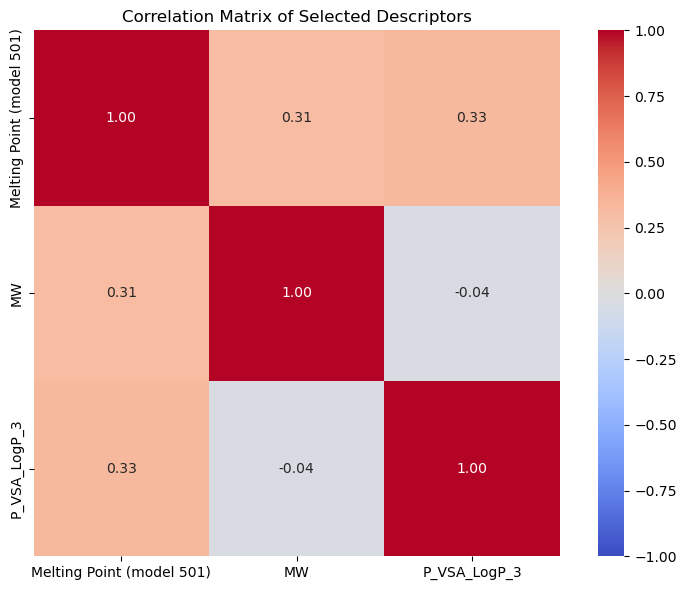


Model equation:
Flash point = 20.5225 + 0.8907 * Melting Point (model 501) + 0.3973 * MW + 0.5519 * P_VSA_LogP_3

Y-randomization: 50
Original model:   R = 0.8835 | R2 = 0.7805 | Q2_LOO = 0.7227
Randomized (avg): R = 0.2333 | R2 = 0.0611 | Q2_LOO = -0.0929
Randomized (max): R2 = 0.1966 | Q2_LOO = 0.0960
cRp2 = 0.7494   (PASS, threshold > 0.5)

Model  Average R  Average R2  Average Q2_LOO   cRp2
 H304     0.2333      0.0611         -0.0929 0.7494


In [18]:
#Flash Point 


import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, KFold
from sklearn.linear_model import LinearRegression
from sklearn.feature_selection import VarianceThreshold
from sklearn.metrics import r2_score, mean_squared_error
import seaborn as sns
import matplotlib.pyplot as plt


VAR_THRESHOLD = 0.01
CORR_THRESHOLD = 0.70
N_FEATURES = 3
OUTER_FOLDS = 5
INNER_FOLDS = 5

file_path = "Flash_Point.xlsx"
new_solvent_path = "Smiles_desc_distinct_cleaned.xlsx"



def fit_predict(X_learn, y_learn, X_check):
    A_learn = np.column_stack([np.ones(len(X_learn)), X_learn])
    A_check = np.column_stack([np.ones(len(X_check)), X_check])
    coef, *_ = np.linalg.lstsq(A_learn, y_learn, rcond=None)
    return A_check @ coef


def filter_descriptors(X_learn):
    var_thresh = VarianceThreshold(threshold=VAR_THRESHOLD)
    var_thresh.fit(X_learn)
    X_var = X_learn.loc[:, var_thresh.get_support()]
    corr_matrix = X_var.corr().abs()
    upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
    to_drop = [col for col in upper.columns if any(upper[col] > CORR_THRESHOLD)]
    return [col for col in X_var.columns if col not in to_drop]


def inner_cv_error(X_learn, y_learn, features, inner_folds):
    Xv = X_learn[features].to_numpy(dtype=float)
    yv = y_learn.to_numpy(dtype=float)
    errors = []
    for learn_idx, check_idx in inner_folds:
        pred = fit_predict(Xv[learn_idx], yv[learn_idx], Xv[check_idx])
        errors.append(np.mean((yv[check_idx] - pred) ** 2))
    return np.mean(errors)


def select_descriptors(X_learn, y_learn, n_features=N_FEATURES):
    candidates = filter_descriptors(X_learn)
    if len(candidates) == 0:
        raise ValueError("No descriptors survived filtering. Adjust thresholds.")
    inner_folds = list(KFold(n_splits=INNER_FOLDS, shuffle=True,
                             random_state=11).split(X_learn))
    remaining = list(candidates)
    selected = []
    while len(selected) < min(n_features, len(candidates)):
        best_error, best_feature = np.inf, None
        for feature in remaining:
            error = inner_cv_error(X_learn, y_learn, selected + [feature], inner_folds)
            if error < best_error:
                best_error, best_feature = error, feature
        selected.append(best_feature)
        remaining.remove(best_feature)
    return selected


def nested_q2(X_tr, y_tr):
    outer = KFold(n_splits=OUTER_FOLDS, shuffle=True, random_state=11)
    y_pred_cv = np.empty(len(y_tr))
    for learn_idx, hidden_idx in outer.split(X_tr):
        X_learn, y_learn = X_tr.iloc[learn_idx], y_tr.iloc[learn_idx]
        X_hidden = X_tr.iloc[hidden_idx]
        selected = select_descriptors(X_learn, y_learn)
        y_pred_cv[hidden_idx] = fit_predict(
            X_learn[selected].to_numpy(float), y_learn.to_numpy(float),
            X_hidden[selected].to_numpy(float)
        )
    return r2_score(y_tr, y_pred_cv)


def compute_leverage(X_train_matrix, X_query_matrix):
    X_tr_f = np.column_stack([np.ones(len(X_train_matrix)), np.asarray(X_train_matrix, float)])
    X_q_f = np.column_stack([np.ones(len(X_query_matrix)), np.asarray(X_query_matrix, float)])
    XtX_inv = np.linalg.pinv(X_tr_f.T @ X_tr_f)
    return np.einsum("ij,jk,ik->i", X_q_f, XtX_inv, X_q_f)


data = pd.read_excel(file_path)
X = data.iloc[:, 1:-1]
X.columns = X.columns.astype(str)
y = data.iloc[:, -1].astype(float)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=11
)

Q2_nested = nested_q2(X_train, y_train)

final_descriptors = select_descriptors(X_train, y_train)
X_train_final = X_train[final_descriptors]
X_test_final = X_test[final_descriptors]

model = LinearRegression()
model.fit(X_train_final, y_train)
y_train_pred = model.predict(X_train_final)
y_test_pred = model.predict(X_test_final)

R2_train = r2_score(y_train, y_train_pred)
R2_test = r2_score(y_test, y_test_pred)
RMSE_train = np.sqrt(mean_squared_error(y_train, y_train_pred))
RMSE_test = np.sqrt(mean_squared_error(y_test, y_test_pred))

ss_res_test = np.sum((y_test - y_test_pred) ** 2)
Q2_F2 = 1 - ss_res_test / np.sum((y_test - y_test.mean()) ** 2)
Q2_F3 = 1 - (ss_res_test / len(y_test)) / (np.sum((y_train - y_train.mean()) ** 2) / len(y_train))

metrics = pd.DataFrame([{
    "Model": "Flash point",
    "R2_train": round(R2_train, 4),
    "Q2_nested": round(Q2_nested, 4),
    "RMSE_tr": round(RMSE_train, 4),
    "R2_test": round(R2_test, 4),
    "Q2_F2": round(Q2_F2, 4),
    "Q2_F3": round(Q2_F3, 4),
    "RMSE_test": round(RMSE_test, 4),
}])
print("Final descriptors:", final_descriptors)
print()
print(metrics.to_string(index=False))

new_df = pd.read_excel(new_solvent_path)
X_new = new_df.iloc[:, 1:]
X_new.columns = X_new.columns.astype(str)
missing = [d for d in final_descriptors if d not in X_new.columns]
if missing:
    raise ValueError(f"Descriptors missing from new solvent file: {missing}")
X_new_final = X_new[final_descriptors].astype(float)

X_tr = X_train_final.to_numpy(float)
p = X_tr.shape[1]
n_train = X_tr.shape[0]
h_star = 3 * (p + 1) / n_train

train_residuals = y_train.to_numpy(float) - y_train_pred
residual_std = np.std(train_residuals, ddof=p + 1) or 1.0

h_train = compute_leverage(X_tr, X_tr)
sr_train = train_residuals / residual_std
inside_train = int(np.sum((h_train <= h_star) & (np.abs(sr_train) <= 3)))

h_test = compute_leverage(X_tr, X_test_final.to_numpy(float))
sr_test = (y_test.to_numpy(float) - y_test_pred) / residual_std
inside_test = int(np.sum((h_test <= h_star) & (np.abs(sr_test) <= 3)))

h_new = compute_leverage(X_tr, X_new_final.to_numpy(float))
inside_new = int(np.sum(h_new <= h_star))

ad_summary = pd.DataFrame({
    "Set": ["Train", "Test", "New solvents"],
    "Inside AD": [inside_train, inside_test, inside_new],
    "Total": [len(h_train), len(h_test), len(h_new)],
})
ad_summary["Inside AD (%)"] = (100 * ad_summary["Inside AD"] / ad_summary["Total"]).round(1)

print(f"\nApplicability domain (h* = {h_star:.4f})")
print(ad_summary.to_string(index=False))

plt.figure(figsize=(8, 6))
sns.heatmap(X_train_final.corr(), annot=True, cmap="coolwarm", fmt=".2f",
            vmin=-1, vmax=1, square=True)
plt.title("Correlation Matrix of Selected Descriptors")
plt.tight_layout()
plt.show()



intercept = model.intercept_
coefs = model.coef_

terms = [f"{intercept:.4f}"]
for coef, name in zip(coefs, final_descriptors):
    sign = "+" if coef >= 0 else "-"
    terms.append(f"{sign} {abs(coef):.4f} * {name}")

equation = "Flash point = " + " ".join(terms)

print("\nModel equation:")
print(equation)


N_PERMUTATIONS = 50



def model_stats(X_mat, y_vec):
    A = np.column_stack([np.ones(len(X_mat)), X_mat])
    coef, *_ = np.linalg.lstsq(A, y_vec, rcond=None)
    pred = A @ coef
    resid = y_vec - pred
    tss = np.sum((y_vec - y_vec.mean()) ** 2)

    R2 = 1 - np.sum(resid ** 2) / tss
    R = abs(np.corrcoef(y_vec, pred)[0, 1]) if np.std(pred) > 1e-12 else 0.0

    H = A @ np.linalg.pinv(A.T @ A) @ A.T
    h = np.clip(np.diag(H), 0, 1 - 1e-12)
    Q2_LOO = 1 - np.sum((resid / (1 - h)) ** 2) / tss
    return R, R2, Q2_LOO



X_tr_np = X_train[final_descriptors].to_numpy(float)
y_tr_np = y_train.to_numpy(float)
R_orig, R2_orig, Q2_orig = model_stats(X_tr_np, y_tr_np)


rng = np.random.default_rng(2024)
rows = [model_stats(X_tr_np, rng.permutation(y_tr_np)) for _ in range(N_PERMUTATIONS)]
yr = pd.DataFrame(rows, columns=["R", "R2", "Q2_LOO"])


cRp2 = R_orig * np.sqrt(max(R2_orig - yr["R2"].mean(), 0.0))

print(f"\nY-randomization: {N_PERMUTATIONS}")
print(f"Original model:   R = {R_orig:.4f} | R2 = {R2_orig:.4f} | Q2_LOO = {Q2_orig:.4f}")
print(f"Randomized (avg): R = {yr['R'].mean():.4f} | R2 = {yr['R2'].mean():.4f} "
      f"| Q2_LOO = {yr['Q2_LOO'].mean():.4f}")
print(f"Randomized (max): R2 = {yr['R2'].max():.4f} | Q2_LOO = {yr['Q2_LOO'].max():.4f}")
print(f"cRp2 = {cRp2:.4f}   ({'PASS' if cRp2 > 0.5 else 'FAIL'}, threshold > 0.5)")

summary = pd.DataFrame([{
    "Model": ENDPOINT_NAME,
    "Average R": round(yr["R"].mean(), 4),
    "Average R2": round(yr["R2"].mean(), 4),
    "Average Q2_LOO": round(yr["Q2_LOO"].mean(), 4),
    "cRp2": round(cRp2, 4),
}])
print("\n" + summary.to_string(index=False))




Final descriptors: ['Melting Point (model 501)', 'MW', 'AMW']

        Model  R2_train  Q2_nested  RMSE_tr  R2_test  Q2_F2  Q2_F3  RMSE_test
Boiling point    0.7404     0.5962  37.5787   0.6094 0.6094  0.773    35.1425

Applicability domain (h* = 0.1967)
         Set  Inside AD  Total  Inside AD (%)
       Train         57     61           93.4
        Test         20     21           95.2
New solvents         91    105           86.7


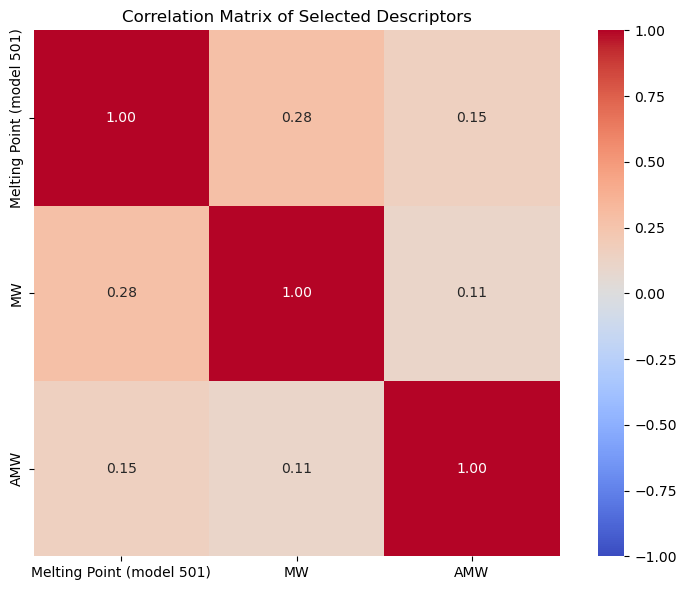


Model equation:
Boiling Point = 129.4396 + 1.1043 * Melting Point (model 501) + 0.7274 * MW - 4.7588 * AMW

Y-randomization: 50 permutations
Original model:   R = 0.8605 | R2 = 0.7404 | Q2_LOO = 0.7001
Randomized (avg): R = 0.2041 | R2 = 0.0497 | Q2_LOO = -0.1055
Randomized (max): R2 = 0.1477 | Q2_LOO = 0.0166
cRp2 = 0.7151   (PASS, threshold > 0.5)

        Model  Average R  Average R2  Average Q2_LOO   cRp2
Boiling point     0.2041      0.0497         -0.1055 0.7151


In [19]:
#Boiling Point

import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, KFold
from sklearn.linear_model import LinearRegression
from sklearn.feature_selection import VarianceThreshold
from sklearn.metrics import r2_score, mean_squared_error
import seaborn as sns
import matplotlib.pyplot as plt


VAR_THRESHOLD = 0.01
CORR_THRESHOLD = 0.65
N_FEATURES = 3
OUTER_FOLDS = 5
INNER_FOLDS = 5

file_path = "Boiling_Point.xlsx"
new_solvent_path = "Smiles_desc_distinct_cleaned.xlsx"

def fit_predict(X_learn, y_learn, X_check):
    A_learn = np.column_stack([np.ones(len(X_learn)), X_learn])
    A_check = np.column_stack([np.ones(len(X_check)), X_check])
    coef, *_ = np.linalg.lstsq(A_learn, y_learn, rcond=None)
    return A_check @ coef


def filter_descriptors(X_learn):
    var_thresh = VarianceThreshold(threshold=VAR_THRESHOLD)
    var_thresh.fit(X_learn)
    X_var = X_learn.loc[:, var_thresh.get_support()]
    corr_matrix = X_var.corr().abs()
    upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
    to_drop = [col for col in upper.columns if any(upper[col] > CORR_THRESHOLD)]
    return [col for col in X_var.columns if col not in to_drop]


def inner_cv_error(X_learn, y_learn, features, inner_folds):
    Xv = X_learn[features].to_numpy(dtype=float)
    yv = y_learn.to_numpy(dtype=float)
    errors = []
    for learn_idx, check_idx in inner_folds:
        pred = fit_predict(Xv[learn_idx], yv[learn_idx], Xv[check_idx])
        errors.append(np.mean((yv[check_idx] - pred) ** 2))
    return np.mean(errors)


def select_descriptors(X_learn, y_learn, n_features=N_FEATURES):
    candidates = filter_descriptors(X_learn)
    if len(candidates) == 0:
        raise ValueError("No descriptors survived filtering. Adjust thresholds.")
    inner_folds = list(KFold(n_splits=INNER_FOLDS, shuffle=True,
                             random_state=40).split(X_learn))
    remaining = list(candidates)
    selected = []
    while len(selected) < min(n_features, len(candidates)):
        best_error, best_feature = np.inf, None
        for feature in remaining:
            error = inner_cv_error(X_learn, y_learn, selected + [feature], inner_folds)
            if error < best_error:
                best_error, best_feature = error, feature
        selected.append(best_feature)
        remaining.remove(best_feature)
    return selected


def nested_q2(X_tr, y_tr):
    outer = KFold(n_splits=OUTER_FOLDS, shuffle=True, random_state=40)
    y_pred_cv = np.empty(len(y_tr))
    for learn_idx, hidden_idx in outer.split(X_tr):
        X_learn, y_learn = X_tr.iloc[learn_idx], y_tr.iloc[learn_idx]
        X_hidden = X_tr.iloc[hidden_idx]
        selected = select_descriptors(X_learn, y_learn)
        y_pred_cv[hidden_idx] = fit_predict(
            X_learn[selected].to_numpy(float), y_learn.to_numpy(float),
            X_hidden[selected].to_numpy(float)
        )
    return r2_score(y_tr, y_pred_cv)


def compute_leverage(X_train_matrix, X_query_matrix):
    X_tr_f = np.column_stack([np.ones(len(X_train_matrix)), np.asarray(X_train_matrix, float)])
    X_q_f = np.column_stack([np.ones(len(X_query_matrix)), np.asarray(X_query_matrix, float)])
    XtX_inv = np.linalg.pinv(X_tr_f.T @ X_tr_f)
    return np.einsum("ij,jk,ik->i", X_q_f, XtX_inv, X_q_f)


data = pd.read_excel(file_path)
X = data.iloc[:, 1:-1]
X.columns = X.columns.astype(str)
y = data.iloc[:, -1].astype(float)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=40
)


Q2_nested = nested_q2(X_train, y_train)

final_descriptors = select_descriptors(X_train, y_train)
X_train_final = X_train[final_descriptors]
X_test_final = X_test[final_descriptors]

model = LinearRegression()
model.fit(X_train_final, y_train)
y_train_pred = model.predict(X_train_final)
y_test_pred = model.predict(X_test_final)

R2_train = r2_score(y_train, y_train_pred)
R2_test = r2_score(y_test, y_test_pred)
RMSE_train = np.sqrt(mean_squared_error(y_train, y_train_pred))
RMSE_test = np.sqrt(mean_squared_error(y_test, y_test_pred))

ss_res_test = np.sum((y_test - y_test_pred) ** 2)
Q2_F2 = 1 - ss_res_test / np.sum((y_test - y_test.mean()) ** 2)
Q2_F3 = 1 - (ss_res_test / len(y_test)) / (np.sum((y_train - y_train.mean()) ** 2) / len(y_train))

metrics = pd.DataFrame([{
    "Model": "Boiling point",
    "R2_train": round(R2_train, 4),
    "Q2_nested": round(Q2_nested, 4),
    "RMSE_tr": round(RMSE_train, 4),
    "R2_test": round(R2_test, 4),
    "Q2_F2": round(Q2_F2, 4),
    "Q2_F3": round(Q2_F3, 4),
    "RMSE_test": round(RMSE_test, 4),
}])
print("Final descriptors:", final_descriptors)
print()
print(metrics.to_string(index=False))

new_df = pd.read_excel(new_solvent_path)
X_new = new_df.iloc[:, 1:]
X_new.columns = X_new.columns.astype(str)
missing = [d for d in final_descriptors if d not in X_new.columns]
if missing:
    raise ValueError(f"Descriptors missing from new solvent file: {missing}")
X_new_final = X_new[final_descriptors].astype(float)

X_tr = X_train_final.to_numpy(float)
p = X_tr.shape[1]
n_train = X_tr.shape[0]
h_star = 3 * (p + 1) / n_train

train_residuals = y_train.to_numpy(float) - y_train_pred
residual_std = np.std(train_residuals, ddof=p + 1) or 1.0

h_train = compute_leverage(X_tr, X_tr)
sr_train = train_residuals / residual_std
inside_train = int(np.sum((h_train <= h_star) & (np.abs(sr_train) <= 3)))

h_test = compute_leverage(X_tr, X_test_final.to_numpy(float))
sr_test = (y_test.to_numpy(float) - y_test_pred) / residual_std
inside_test = int(np.sum((h_test <= h_star) & (np.abs(sr_test) <= 3)))

h_new = compute_leverage(X_tr, X_new_final.to_numpy(float))
inside_new = int(np.sum(h_new <= h_star))

ad_summary = pd.DataFrame({
    "Set": ["Train", "Test", "New solvents"],
    "Inside AD": [inside_train, inside_test, inside_new],
    "Total": [len(h_train), len(h_test), len(h_new)],
})
ad_summary["Inside AD (%)"] = (100 * ad_summary["Inside AD"] / ad_summary["Total"]).round(1)

print(f"\nApplicability domain (h* = {h_star:.4f})")
print(ad_summary.to_string(index=False))

plt.figure(figsize=(8, 6))
sns.heatmap(X_train_final.corr(), annot=True, cmap="coolwarm", fmt=".2f",
            vmin=-1, vmax=1, square=True)
plt.title("Correlation Matrix of Selected Descriptors")
plt.tight_layout()
plt.show()

intercept = model.intercept_
coefs = model.coef_

terms = [f"{intercept:.4f}"]
for coef, name in zip(coefs, final_descriptors):
    sign = "+" if coef >= 0 else "-"
    terms.append(f"{sign} {abs(coef):.4f} * {name}")

equation = "Boiling Point = " + " ".join(terms)

print("\nModel equation:")
print(equation)


ENDPOINT_NAME = "Boiling point"
N_PERMUTATIONS = 50


def model_stats(X_mat, y_vec):

    A = np.column_stack([np.ones(len(X_mat)), X_mat])
    coef, *_ = np.linalg.lstsq(A, y_vec, rcond=None)
    pred = A @ coef
    resid = y_vec - pred
    tss = np.sum((y_vec - y_vec.mean()) ** 2)

    R2 = 1 - np.sum(resid ** 2) / tss
    R = abs(np.corrcoef(y_vec, pred)[0, 1]) if np.std(pred) > 1e-12 else 0.0

    H = A @ np.linalg.pinv(A.T @ A) @ A.T
    h = np.clip(np.diag(H), 0, 1 - 1e-12)
    Q2_LOO = 1 - np.sum((resid / (1 - h)) ** 2) / tss
    return R, R2, Q2_LOO


X_tr_np = X_train[final_descriptors].to_numpy(float)
y_tr_np = y_train.to_numpy(float)
R_orig, R2_orig, Q2_orig = model_stats(X_tr_np, y_tr_np)

rng = np.random.default_rng(2024)
rows = [model_stats(X_tr_np, rng.permutation(y_tr_np)) for _ in range(N_PERMUTATIONS)]
yr = pd.DataFrame(rows, columns=["R", "R2", "Q2_LOO"])

cRp2 = R_orig * np.sqrt(max(R2_orig - yr["R2"].mean(), 0.0))

print(f"\nY-randomization: {N_PERMUTATIONS} permutations")
print(f"Original model:   R = {R_orig:.4f} | R2 = {R2_orig:.4f} | Q2_LOO = {Q2_orig:.4f}")
print(f"Randomized (avg): R = {yr['R'].mean():.4f} | R2 = {yr['R2'].mean():.4f} | Q2_LOO = {yr['Q2_LOO'].mean():.4f}")
print(f"Randomized (max): R2 = {yr['R2'].max():.4f} | Q2_LOO = {yr['Q2_LOO'].max():.4f}")
print(f"cRp2 = {cRp2:.4f}   ({'PASS' if cRp2 > 0.5 else 'FAIL'}, threshold > 0.5)")

summary = pd.DataFrame([{
    "Model": ENDPOINT_NAME,
    "Average R": round(yr["R"].mean(), 4),
    "Average R2": round(yr["R2"].mean(), 4),
    "Average Q2_LOO": round(yr["Q2_LOO"].mean(), 4),
    "cRp2": round(cRp2, 4),
}])
print("\n" + summary.to_string(index=False))

Final descriptors: ['P_VSA_LogP_2', 'J_Dz(Z)', 'P_VSA_LogP_5', 'P_VSA_charge_10']

        Model  R2_train  Q2_nested  RMSE_tr  R2_test  Q2_F2  Q2_F3  RMSE_test
Auto-ignition    0.5992     0.4202  62.4524   0.5977 0.5977 0.5342    67.3268

Applicability domain (d* = 1.9701)
         Set  Inside AD  Total  Inside AD (%)
       Train         48     57           84.2
        Test         13     19           68.4
New solvents         58    105           55.2


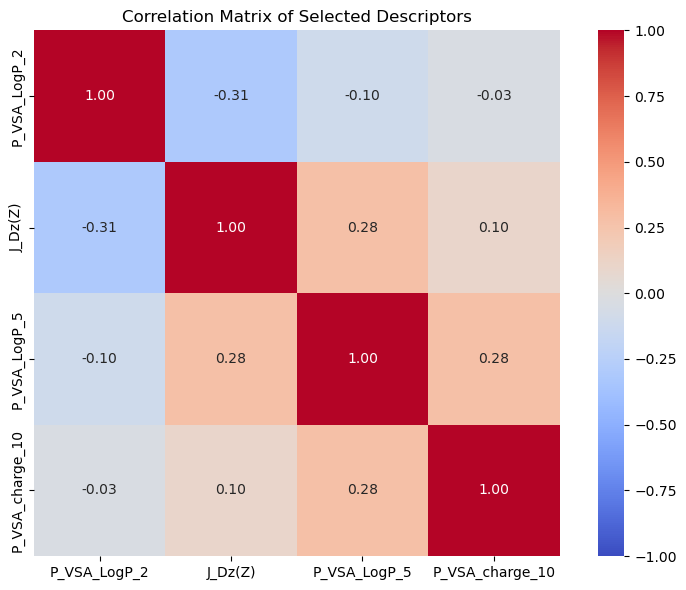


Y-randomization: 50 permutations
Original model:   R = 0.7745 | R2 = 0.5992 | Q2_LOO = 0.5434
Randomized (avg): R = 0.2907 | R2 = 0.0848 | Q2_LOO = -0.1358
Randomized (max): R2 = 0.2396 | Q2_LOO = 0.0106
cRp2 = 0.5555   (PASS, threshold > 0.5)

        Model  Average R  Average R2  Average Q2_LOO   cRp2
Auto-ignition     0.2907      0.0848         -0.1358 0.5555


In [14]:
#Auto-ignition  

import pandas as pd
import numpy as np
from collections import Counter
from sklearn.model_selection import train_test_split, KFold
from sklearn.neighbors import KNeighborsRegressor, NearestNeighbors
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import VarianceThreshold
from sklearn.metrics import r2_score, mean_squared_error
import seaborn as sns
import matplotlib.pyplot as plt

import warnings
warnings.filterwarnings("ignore", category=UserWarning, module="sklearn")


VAR_THRESHOLD = 0.01
CORR_THRESHOLD = 0.70
N_FEATURES = 4
K = 9
OUTER_FOLDS = 5
INNER_FOLDS = 5



file_path = "Auto_Ignition_d.xlsx"
new_solvent_path = "Smiles_desc_distinct_cleaned.xlsx"


def forward_selection_knn_val(X_train, y_train, X_val, y_val, n_features=N_FEATURES, k=K):
    remaining = list(X_train.columns)
    selected = []
    while len(selected) < min(n_features, len(remaining)):
        best_score, best_feature = -np.inf, None
        for feature in remaining:
            features_to_test = selected + [feature]
            scaler = StandardScaler()
            X_tr_scaled = scaler.fit_transform(X_train[features_to_test].values)
            X_val_scaled = scaler.transform(X_val[features_to_test].values)
            model = KNeighborsRegressor(n_neighbors=k)
            model.fit(X_tr_scaled, y_train)
            score = r2_score(y_val, model.predict(X_val_scaled))
            if score > best_score:
                best_score, best_feature = score, feature
        selected.append(best_feature)
        remaining.remove(best_feature)
    return selected


def filter_descriptors(X_fit, X_other):
    var_thresh = VarianceThreshold(threshold=VAR_THRESHOLD)
    X_fit_var = pd.DataFrame(var_thresh.fit_transform(X_fit),
                             columns=X_fit.columns[var_thresh.get_support()])
    X_other_var = pd.DataFrame(var_thresh.transform(X_other), columns=X_fit_var.columns)
    corr_matrix = X_fit_var.corr().abs()
    upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
    to_drop = [col for col in upper.columns if any(upper[col] > CORR_THRESHOLD)]
    return X_fit_var.drop(columns=to_drop), X_other_var.drop(columns=to_drop)


def select_descriptors(X_learn, y_learn, seed):
    """5-fold voting with forward selection, then top N_FEATURES."""
    X_learn = X_learn.reset_index(drop=True)
    y_learn = y_learn.reset_index(drop=True)

    kf = KFold(n_splits=INNER_FOLDS, shuffle=True, random_state=24)
    all_selected_features = []
    for train_idx, val_idx in kf.split(X_learn):
        X_inner_train = X_learn.iloc[train_idx].reset_index(drop=True)
        y_inner_train = y_learn.iloc[train_idx].reset_index(drop=True)
        X_inner_val = X_learn.iloc[val_idx].reset_index(drop=True)
        y_inner_val = y_learn.iloc[val_idx].reset_index(drop=True)

        X_inner_filtered, X_inner_val_filtered = filter_descriptors(X_inner_train, X_inner_val)
        all_selected_features.extend(forward_selection_knn_val(
            X_inner_filtered, y_inner_train, X_inner_val_filtered, y_inner_val
        ))

    feature_counts = Counter(all_selected_features)
    X_learn_filtered, _ = filter_descriptors(X_learn, X_learn)
    available_features = [
        feat for feat, count in feature_counts.most_common()
        if feat in X_learn_filtered.columns
    ]
    selected = available_features[:N_FEATURES]
    if len(selected) == 0:
        raise ValueError("No descriptors survived filtering. Adjust thresholds.")
    return selected


def fit_predict_knn(X_learn, y_learn, X_check):
    scaler = StandardScaler()
    X_learn_scaled = scaler.fit_transform(X_learn)
    X_check_scaled = scaler.transform(X_check)
    model = KNeighborsRegressor(n_neighbors=K)
    model.fit(X_learn_scaled, y_learn)
    return model.predict(X_check_scaled)


def nested_q2(X_tr, y_tr, seed):
    """Outer CV: descriptors are re-selected inside every outer fold."""
    outer = KFold(n_splits=OUTER_FOLDS, shuffle=True, random_state=24)
    y_pred_cv = np.empty(len(y_tr))
    for learn_idx, hidden_idx in outer.split(X_tr):
        X_learn, y_learn = X_tr.iloc[learn_idx], y_tr.iloc[learn_idx]
        X_hidden = X_tr.iloc[hidden_idx]
        selected = select_descriptors(X_learn, y_learn, seed)
        y_pred_cv[hidden_idx] = fit_predict_knn(
            X_learn[selected].values, y_learn.values, X_hidden[selected].values
        )
    return r2_score(y_tr, y_pred_cv)


data = pd.read_excel(file_path)
X = data.iloc[:, 1:-1]
y = data.iloc[:, -1]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=24
)

Q2_nested = nested_q2(X_train, y_train, 24)

final_descriptors = select_descriptors(X_train, y_train, 24)
X_train_final = X_train[final_descriptors]
X_test_final = X_test[final_descriptors]

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_final)
X_test_scaled = scaler.transform(X_test_final)

model = KNeighborsRegressor(n_neighbors=K)
model.fit(X_train_scaled, y_train)
y_train_pred = model.predict(X_train_scaled)
y_test_pred = model.predict(X_test_scaled)

y_train_arr = y_train.values
y_test_arr = y_test.values

R2_train = r2_score(y_train, y_train_pred)
R2_test = r2_score(y_test, y_test_pred)
RMSE_train = np.sqrt(mean_squared_error(y_train, y_train_pred))
RMSE_test = np.sqrt(mean_squared_error(y_test, y_test_pred))

ss_res_test = np.sum((y_test_arr - y_test_pred) ** 2)
Q2_F2 = 1 - ss_res_test / np.sum((y_test_arr - y_test_arr.mean()) ** 2)
Q2_F3 = 1 - (ss_res_test / len(y_test_arr)) / (np.sum((y_train_arr - y_train_arr.mean()) ** 2) / len(y_train_arr))

metrics = pd.DataFrame([{
    "Model": "Auto-ignition",
    "R2_train": round(R2_train, 4),
    "Q2_nested": round(Q2_nested, 4),
    "RMSE_tr": round(RMSE_train, 4),
    "R2_test": round(R2_test, 4),
    "Q2_F2": round(Q2_F2, 4),
    "Q2_F3": round(Q2_F3, 4),
    "RMSE_test": round(RMSE_test, 4),
}])
print("Final descriptors:", final_descriptors)
print()
print(metrics.to_string(index=False))

new_df = pd.read_excel(new_solvent_path)
new_df.columns = new_df.columns.astype(str)
missing = [d for d in final_descriptors if d not in new_df.columns]
if missing:
    raise ValueError(f"Descriptors missing from new solvent file: {missing}")
X_new_final = new_df[final_descriptors].apply(pd.to_numeric, errors="coerce")
valid = X_new_final.notna().all(axis=1).to_numpy()

y_new_pred = np.full(len(X_new_final), np.nan)
new_mean_dists = np.full(len(X_new_final), np.nan)

nn_train = NearestNeighbors(n_neighbors=K + 1).fit(X_train_scaled)
train_dists, _ = nn_train.kneighbors(X_train_scaled)
train_mean_dists = train_dists[:, 1:].mean(axis=1)
d_star = train_mean_dists.mean() + 1.0 * train_mean_dists.std()

nn_ref = NearestNeighbors(n_neighbors=K).fit(X_train_scaled)
test_dists, _ = nn_ref.kneighbors(X_test_scaled)
test_mean_dists = test_dists.mean(axis=1)

if valid.any():
    X_new_scaled = scaler.transform(X_new_final[valid])
    y_new_pred[valid] = model.predict(X_new_scaled)
    new_dists, _ = nn_ref.kneighbors(X_new_scaled)
    new_mean_dists[valid] = new_dists.mean(axis=1)

p = X_train_scaled.shape[1]
train_residuals = y_train_arr - y_train_pred
residual_std = np.std(train_residuals, ddof=p + 1) or 1.0
sr_train = train_residuals / residual_std
sr_test = (y_test_arr - y_test_pred) / residual_std

inside_train = int(np.sum((train_mean_dists <= d_star) & (np.abs(sr_train) <= 3)))
inside_test = int(np.sum((test_mean_dists <= d_star) & (np.abs(sr_test) <= 3)))
inside_new = int(np.sum(valid & (np.nan_to_num(new_mean_dists, nan=np.inf) <= d_star)))

ad_summary = pd.DataFrame({
    "Set": ["Train", "Test", "New solvents"],
    "Inside AD": [inside_train, inside_test, inside_new],
    "Total": [len(train_mean_dists), len(test_mean_dists), int(valid.sum())],
})
ad_summary["Inside AD (%)"] = (100 * ad_summary["Inside AD"] / ad_summary["Total"]).round(1)

print(f"\nApplicability domain (d* = {d_star:.4f})")
print(ad_summary.to_string(index=False))

plt.figure(figsize=(8, 6))
sns.heatmap(X_train_final.corr(), annot=True, cmap="coolwarm", fmt=".2f",
            vmin=-1, vmax=1, square=True)
plt.title("Correlation Matrix of Selected Descriptors")
plt.tight_layout()
plt.show()


from sklearn.model_selection import LeaveOneOut, cross_val_predict

ENDPOINT_NAME = "Auto-ignition"

N_PERMUTATIONS = 50



def model_stats(X_mat, y_vec):
    """|R|, R2 (fit on the full training set) and Q2_LOO for the kNN model."""
    knn = KNeighborsRegressor(n_neighbors=K)
    pred = knn.fit(X_mat, y_vec).predict(X_mat)
    R2 = r2_score(y_vec, pred)
    R = abs(np.corrcoef(y_vec, pred)[0, 1]) if np.std(pred) > 1e-12 else 0.0

    pred_loo = cross_val_predict(KNeighborsRegressor(n_neighbors=K), X_mat, y_vec, cv=LeaveOneOut())
    Q2_LOO = r2_score(y_vec, pred_loo)
    return R, R2, Q2_LOO


y_tr_np = y_train.to_numpy(float)
R_orig, R2_orig, Q2_orig = model_stats(X_train_scaled, y_tr_np)

rng = np.random.default_rng(2024)
rows = [model_stats(X_train_scaled, rng.permutation(y_tr_np)) for _ in range(N_PERMUTATIONS)]
yr = pd.DataFrame(rows, columns=["R", "R2", "Q2_LOO"])

cRp2 = R_orig * np.sqrt(max(R2_orig - yr["R2"].mean(), 0.0))

print(f"\nY-randomization: {N_PERMUTATIONS} permutations")
print(f"Original model:   R = {R_orig:.4f} | R2 = {R2_orig:.4f} | Q2_LOO = {Q2_orig:.4f}")
print(f"Randomized (avg): R = {yr['R'].mean():.4f} | R2 = {yr['R2'].mean():.4f} | Q2_LOO = {yr['Q2_LOO'].mean():.4f}")
print(f"Randomized (max): R2 = {yr['R2'].max():.4f} | Q2_LOO = {yr['Q2_LOO'].max():.4f}")
print(f"cRp2 = {cRp2:.4f}   ({'PASS' if cRp2 > 0.5 else 'FAIL'}, threshold > 0.5)")

summary = pd.DataFrame([{
    "Model": ENDPOINT_NAME,
    "Average R": round(yr["R"].mean(), 4),
    "Average R2": round(yr["R2"].mean(), 4),
    "Average Q2_LOO": round(yr["Q2_LOO"].mean(), 4),
    "cRp2": round(cRp2, 4),
}])
print("\n" + summary.to_string(index=False))



In [35]:
#H302

import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.feature_selection import VarianceThreshold
from sklearn.metrics import (
    matthews_corrcoef,
    f1_score,
    balanced_accuracy_score,
    cohen_kappa_score,
    roc_auc_score
)



TEST_SIZE = 0.25
VAR_THRESHOLD = 0.01
CORR_THRESHOLD = 0.90
N_FEATURES = 2
N_OUTER = 3
N_INNER = 3
AD_K = 3


DATA_FILE = "H302.xlsx"
new_solvent_path = "Smiles_desc_distinct_cleaned.xlsx"


def filter_features(X):
    vt = VarianceThreshold(threshold=VAR_THRESHOLD).fit(X)
    cols = X.columns[vt.get_support()]
    corr = X[cols].corr().abs()
    upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
    to_drop = {c for c in upper.columns if any(upper[c] > CORR_THRESHOLD)}
    return [c for c in cols if c not in to_drop]


def fast_mcc(y_true, y_pred):
    tp = np.sum((y_true == 1) & (y_pred == 1))
    tn = np.sum((y_true == 0) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    denom = np.sqrt(float((tp + fp) * (tp + fn) * (tn + fp) * (tn + fn)))
    return 0.0 if denom == 0 else (tp * tn - fp * fn) / denom


def forward_selection(X, y, cv):
    names = list(X.columns)
    Xv, yv = X.to_numpy(dtype=float), y.to_numpy()
    folds = []
    for tr, va in cv.split(Xv, yv):
        sc = StandardScaler().fit(Xv[tr])
        folds.append((sc.transform(Xv[tr]), yv[tr], sc.transform(Xv[va]), yv[va]))

    selected, remaining = [], list(range(len(names)))
    for _ in range(N_FEATURES):
        best_score, best_j = -np.inf, None
        for j in remaining:
            cols = selected + [j]
            scores = []
            for X_tr, y_tr, X_va, y_va in folds:
                m = make_model().fit(X_tr[:, cols], y_tr)
                scores.append(fast_mcc(y_va, m.predict(X_va[:, cols])))
            s = np.mean(scores)
            if s > best_score:
                best_score, best_j = s, j
        selected.append(best_j)
        remaining.remove(best_j)
    return [names[j] for j in selected]


def all_metrics(y_true, y_pred, y_proba):
    return {
        "Balanced Accuracy": balanced_accuracy_score(y_true, y_pred),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "MCC": matthews_corrcoef(y_true, y_pred),
        "Cohen's Kappa": cohen_kappa_score(y_true, y_pred),
        "ROC-AUC": roc_auc_score(y_true, y_proba) if len(np.unique(y_true)) == 2 else np.nan,
    }


def ad_distance(X_scaled, centroid):
    return np.linalg.norm(np.asarray(X_scaled, dtype=float) - centroid, axis=1)

def make_model():
    return KNeighborsClassifier(n_neighbors=5, weights="distance", metric="euclidean")





full_df = pd.read_excel(DATA_FILE)
names = full_df.iloc[:, 0]
X = full_df.iloc[:, 1:-1]
y = full_df.iloc[:, -1]

X_train, X_test, y_train, y_test, names_train, names_test = train_test_split(
    X, y, names, test_size=TEST_SIZE, stratify=y, random_state=3
)
X_train = X_train.reset_index(drop=True)
y_train = y_train.reset_index(drop=True)
X_test = X_test.reset_index(drop=True)
y_test = y_test.reset_index(drop=True)
names_train = names_train.reset_index(drop=True)
names_test = names_test.reset_index(drop=True)


outer_cv = StratifiedKFold(n_splits=N_OUTER, shuffle=True, random_state=3)
inner_cv = StratifiedKFold(n_splits=N_INNER, shuffle=True, random_state=3)

fold_results = []
fold_features = []

for fold, (tr_idx, va_idx) in enumerate(outer_cv.split(X_train, y_train), 1):
    X_tr = X_train.iloc[tr_idx].reset_index(drop=True)
    X_va = X_train.iloc[va_idx].reset_index(drop=True)
    y_tr = y_train.iloc[tr_idx].reset_index(drop=True)
    y_va = y_train.iloc[va_idx].reset_index(drop=True)

    kept = filter_features(X_tr)
    feats = forward_selection(X_tr[kept], y_tr, inner_cv)

    fold_scaler = StandardScaler().fit(X_tr[feats])
    model = make_model().fit(fold_scaler.transform(X_tr[feats]), y_tr)

    X_va_s = fold_scaler.transform(X_va[feats])
    y_pred = model.predict(X_va_s)
    y_proba = model.predict_proba(X_va_s)[:, 1]

    fold_results.append(all_metrics(y_va, y_pred, y_proba))
    fold_features.append(feats)

nested_df = pd.DataFrame(fold_results)


kept = filter_features(X_train)
selected_features = forward_selection(X_train[kept], y_train, inner_cv)

scaler = StandardScaler().fit(X_train[selected_features])
X_train_final = pd.DataFrame(scaler.transform(X_train[selected_features]), columns=selected_features)
X_test_final = pd.DataFrame(scaler.transform(X_test[selected_features]), columns=selected_features)

final_model = make_model().fit(X_train_final, y_train)

y_train_pred = final_model.predict(X_train_final)
y_test_pred = final_model.predict(X_test_final)
y_train_proba = final_model.predict_proba(X_train_final)[:, 1]
y_test_proba = final_model.predict_proba(X_test_final)[:, 1]

train_m = all_metrics(y_train, y_train_pred, y_train_proba)
test_m = all_metrics(y_test, y_test_pred, y_test_proba)
metric_names = list(train_m)

metrics = pd.DataFrame(
    [[len(y_train)] + [round(v, 4) for v in train_m.values()]
     + [len(y_test)] + [round(v, 4) for v in test_m.values()]],
    columns=["N_train"] + metric_names + ["N_test"] + metric_names,
)

print("Final descriptors:", selected_features)
print()
print(metrics.to_string(index=False))


train_centroid = X_train_final.mean(axis=0).to_numpy()
train_distances = ad_distance(X_train_final, train_centroid)
AD_THRESHOLD = train_distances.mean() + AD_K * train_distances.std()
test_distances = ad_distance(X_test_final, train_centroid)

new_df = pd.read_excel(new_solvent_path)
missing = [f for f in selected_features if f not in new_df.columns]
if missing:
    raise ValueError(f"Descriptors missing from new solvent file: {missing}")

new_names = new_df.iloc[:, 0]
X_new_raw = new_df[selected_features].apply(pd.to_numeric, errors="coerce")
valid = X_new_raw.notna().all(axis=1).to_numpy()

new_pred = np.full(len(X_new_raw), np.nan)
new_proba = np.full(len(X_new_raw), np.nan)
new_distances = np.full(len(X_new_raw), np.nan)

if valid.any():
    X_new_scaled = pd.DataFrame(scaler.transform(X_new_raw.loc[valid, selected_features]),
                                columns=selected_features)
    new_pred[valid] = final_model.predict(X_new_scaled)
    new_proba[valid] = final_model.predict_proba(X_new_scaled)[:, 1]
    new_distances[valid] = ad_distance(X_new_scaled, train_centroid)

train_in_ad = train_distances <= AD_THRESHOLD
test_in_ad = test_distances <= AD_THRESHOLD
new_in_ad = valid & (np.nan_to_num(new_distances, nan=np.inf) <= AD_THRESHOLD)

ad_summary = pd.DataFrame({
    "Set": ["Train", "Test", "New solvents"],
    "Inside AD": [int(train_in_ad.sum()), int(test_in_ad.sum()), int(new_in_ad.sum())],
    "Total": [len(train_distances), len(test_distances), int(valid.sum())],
})
ad_summary["Inside AD (%)"] = (100 * ad_summary["Inside AD"] / ad_summary["Total"]).round(1)

print(f"\nApplicability domain (distance threshold = {AD_THRESHOLD:.4f}, mean + {AD_K}·SD)")
print(ad_summary.to_string(index=False))
if (~valid).any():
    print(f"{int((~valid).sum())} new solvents skipped (missing descriptor values)")

new_predictions = pd.DataFrame({
    "Solvent_Name": new_names.values,
    "Predicted_Class": pd.Series(new_pred).astype("Int64").values,
    "Prob_Class1": new_proba,
    "Distance": new_distances,
    "AD_Status": np.where(~valid, "Not predicted",
                          np.where(new_in_ad, "Inside AD", "Outside AD")),
})




plt.figure(figsize=(8, 6))
sns.heatmap(X_train[selected_features].corr(), annot=True, cmap="coolwarm", fmt=".2f",
            vmin=-1, vmax=1, square=True)
plt.title("Correlation Matrix of Selected Descriptors")
plt.tight_layout()
plt.show()

ENDPOINT_NAME = "H302"
N_PERMUTATIONS = 500



def cv_metrics(X_mat, y_vec, seed):
    cv = StratifiedKFold(n_splits=N_OUTER, shuffle=True, random_state=seed)
    pred = np.empty(len(y_vec))
    proba = np.empty(len(y_vec))
    for tr, va in cv.split(X_mat, y_vec):
        m = make_model().fit(X_mat.iloc[tr], y_vec[tr])
        pred[va] = m.predict(X_mat.iloc[va])
        proba[va] = m.predict_proba(X_mat.iloc[va])[:, 1]
    return (f1_score(y_vec, pred, zero_division=0),
            balanced_accuracy_score(y_vec, pred),
            roc_auc_score(y_vec, proba))


y_tr_np = y_train.to_numpy()
F1_orig, BA_orig, AUC_orig = cv_metrics(X_train_final, y_tr_np, 3)

rng = np.random.default_rng(2024)
rows = [cv_metrics(X_train_final, rng.permutation(y_tr_np), 3) for _ in range(N_PERMUTATIONS)]
yr = pd.DataFrame(rows, columns=["F1", "Balanced Accuracy", "ROC-AUC"])

print(f"\nY-randomization: {N_PERMUTATIONS} permutations on features {selected_features}")
print(f"Original model (CV): F1 = {F1_orig:.4f} | BA = {BA_orig:.4f} | ROC-AUC = {AUC_orig:.4f}")
print(f"Randomized (avg):    F1 = {yr['F1'].mean():.4f} | BA = {yr['Balanced Accuracy'].mean():.4f} | ROC-AUC = {yr['ROC-AUC'].mean():.4f}")
print(f"Randomized (max):    F1 = {yr['F1'].max():.4f} | BA = {yr['Balanced Accuracy'].max():.4f} | ROC-AUC = {yr['ROC-AUC'].max():.4f}")
print(f"Permutations reaching the original ROC-AUC: {(yr['ROC-AUC'] >= AUC_orig).mean():.3f}")

summary = pd.DataFrame([{
    "Model": ENDPOINT_NAME,
    "Average F1": round(yr["F1"].mean(), 4),
    "Average Balanced Accuracy": round(yr["Balanced Accuracy"].mean(), 4),
    "Average ROC-AUC": round(yr["ROC-AUC"].mean(), 4),
}])
print("\n" + summary.to_string(index=False))


FileNotFoundError: [Errno 2] No such file or directory: 'H302.xlsx'

In [17]:
#H304

import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.feature_selection import VarianceThreshold
from sklearn.metrics import (
    matthews_corrcoef,
    f1_score,
    balanced_accuracy_score,
    cohen_kappa_score,
    roc_auc_score
)


TEST_SIZE = 0.25
VAR_THRESHOLD = 0.01
CORR_THRESHOLD = 0.95
N_FEATURES = 1
N_OUTER = 3
N_INNER = 3
AD_K = 3


DATA_FILE = "H304.xlsx"
new_solvent_path = "Smiles_desc_distinct_cleaned.xlsx"


def make_model():
    return KNeighborsClassifier(n_neighbors=5, weights="distance", metric="euclidean")


def filter_features(X):
    vt = VarianceThreshold(threshold=VAR_THRESHOLD).fit(X)
    cols = X.columns[vt.get_support()]
    corr = X[cols].corr().abs()
    upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
    to_drop = {c for c in upper.columns if any(upper[c] > CORR_THRESHOLD)}
    return [c for c in cols if c not in to_drop]


def fast_mcc(y_true, y_pred):
    tp = np.sum((y_true == 1) & (y_pred == 1))
    tn = np.sum((y_true == 0) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    denom = np.sqrt(float((tp + fp) * (tp + fn) * (tn + fp) * (tn + fn)))
    return 0.0 if denom == 0 else (tp * tn - fp * fn) / denom


def forward_selection(X, y, cv):
    names = list(X.columns)
    Xv, yv = X.to_numpy(dtype=float), y.to_numpy()
    folds = []
    for tr, va in cv.split(Xv, yv):
        sc = StandardScaler().fit(Xv[tr])
        folds.append((sc.transform(Xv[tr]), yv[tr], sc.transform(Xv[va]), yv[va]))

    selected, remaining = [], list(range(len(names)))
    for _ in range(N_FEATURES):
        best_score, best_j = -np.inf, None
        for j in remaining:
            cols = selected + [j]
            scores = []
            for X_tr, y_tr, X_va, y_va in folds:
                m = make_model().fit(X_tr[:, cols], y_tr)
                scores.append(fast_mcc(y_va, m.predict(X_va[:, cols])))
            s = np.mean(scores)
            if s > best_score:
                best_score, best_j = s, j
        selected.append(best_j)
        remaining.remove(best_j)
    return [names[j] for j in selected]


def all_metrics(y_true, y_pred, y_proba):
    return {
        "Balanced Accuracy": balanced_accuracy_score(y_true, y_pred),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "MCC": matthews_corrcoef(y_true, y_pred),
        "Cohen's Kappa": cohen_kappa_score(y_true, y_pred),
        "ROC-AUC": roc_auc_score(y_true, y_proba) if len(np.unique(y_true)) == 2 else np.nan,
    }


def ad_distance(X_scaled, centroid):
    return np.linalg.norm(np.asarray(X_scaled, dtype=float) - centroid, axis=1)


full_df = pd.read_excel(DATA_FILE)
names = full_df.iloc[:, 0]
X = full_df.iloc[:, 1:-1]
y = full_df.iloc[:, -1]

X_train, X_test, y_train, y_test, names_train, names_test = train_test_split(
    X, y, names, test_size=TEST_SIZE, stratify=y, random_state=5
)
X_train = X_train.reset_index(drop=True)
y_train = y_train.reset_index(drop=True)
X_test = X_test.reset_index(drop=True)
y_test = y_test.reset_index(drop=True)
names_train = names_train.reset_index(drop=True)
names_test = names_test.reset_index(drop=True)


outer_cv = StratifiedKFold(n_splits=N_OUTER, shuffle=True, random_state=5)
inner_cv = StratifiedKFold(n_splits=N_INNER, shuffle=True, random_state=5)

fold_results = []
fold_features = []

for fold, (tr_idx, va_idx) in enumerate(outer_cv.split(X_train, y_train), 1):
    X_tr = X_train.iloc[tr_idx].reset_index(drop=True)
    X_va = X_train.iloc[va_idx].reset_index(drop=True)
    y_tr = y_train.iloc[tr_idx].reset_index(drop=True)
    y_va = y_train.iloc[va_idx].reset_index(drop=True)

    kept = filter_features(X_tr)
    feats = forward_selection(X_tr[kept], y_tr, inner_cv)

    fold_scaler = StandardScaler().fit(X_tr[feats])
    model = make_model().fit(fold_scaler.transform(X_tr[feats]), y_tr)

    X_va_s = fold_scaler.transform(X_va[feats])
    y_pred = model.predict(X_va_s)
    y_proba = model.predict_proba(X_va_s)[:, 1]

    fold_results.append(all_metrics(y_va, y_pred, y_proba))
    fold_features.append(feats)

nested_df = pd.DataFrame(fold_results)


kept = filter_features(X_train)
selected_features = forward_selection(X_train[kept], y_train, inner_cv)

scaler = StandardScaler().fit(X_train[selected_features])
X_train_final = pd.DataFrame(scaler.transform(X_train[selected_features]), columns=selected_features)
X_test_final = pd.DataFrame(scaler.transform(X_test[selected_features]), columns=selected_features)

final_model = make_model().fit(X_train_final, y_train)

y_train_pred = final_model.predict(X_train_final)
y_test_pred = final_model.predict(X_test_final)
y_train_proba = final_model.predict_proba(X_train_final)[:, 1]
y_test_proba = final_model.predict_proba(X_test_final)[:, 1]

train_m = all_metrics(y_train, y_train_pred, y_train_proba)
test_m = all_metrics(y_test, y_test_pred, y_test_proba)
metric_names = list(train_m)

metrics = pd.DataFrame(
    [[len(y_train)] + [round(v, 4) for v in train_m.values()]
     + [len(y_test)] + [round(v, 4) for v in test_m.values()]],
    columns=["N_train"] + metric_names + ["N_test"] + metric_names,
)

print("Final descriptors:", selected_features)
print()
print(metrics.to_string(index=False))


train_centroid = X_train_final.mean(axis=0).to_numpy()
train_distances = ad_distance(X_train_final, train_centroid)
AD_THRESHOLD = train_distances.mean() + AD_K * train_distances.std()
test_distances = ad_distance(X_test_final, train_centroid)

new_df = pd.read_excel(new_solvent_path)
missing = [f for f in selected_features if f not in new_df.columns]
if missing:
    raise ValueError(f"Descriptors missing from new solvent file: {missing}")

new_names = new_df.iloc[:, 0]
X_new_raw = new_df[selected_features].apply(pd.to_numeric, errors="coerce")
valid = X_new_raw.notna().all(axis=1).to_numpy()

new_pred = np.full(len(X_new_raw), np.nan)
new_proba = np.full(len(X_new_raw), np.nan)
new_distances = np.full(len(X_new_raw), np.nan)

if valid.any():
    X_new_scaled = pd.DataFrame(scaler.transform(X_new_raw.loc[valid, selected_features]),
                                columns=selected_features)
    new_pred[valid] = final_model.predict(X_new_scaled)
    new_proba[valid] = final_model.predict_proba(X_new_scaled)[:, 1]
    new_distances[valid] = ad_distance(X_new_scaled, train_centroid)

train_in_ad = train_distances <= AD_THRESHOLD
test_in_ad = test_distances <= AD_THRESHOLD
new_in_ad = valid & (np.nan_to_num(new_distances, nan=np.inf) <= AD_THRESHOLD)

ad_summary = pd.DataFrame({
    "Set": ["Train", "Test", "New solvents"],
    "Inside AD": [int(train_in_ad.sum()), int(test_in_ad.sum()), int(new_in_ad.sum())],
    "Total": [len(train_distances), len(test_distances), int(valid.sum())],
})
ad_summary["Inside AD (%)"] = (100 * ad_summary["Inside AD"] / ad_summary["Total"]).round(1)

print(f"\nApplicability domain (distance threshold = {AD_THRESHOLD:.4f}, mean + {AD_K}·SD)")
print(ad_summary.to_string(index=False))
if (~valid).any():
    print(f"{int((~valid).sum())} new solvents skipped (missing descriptor values)")

new_predictions = pd.DataFrame({
    "Solvent_Name": new_names.values,
    "Predicted_Class": pd.Series(new_pred).astype("Int64").values,
    "Prob_Class1": new_proba,
    "Distance": new_distances,
    "AD_Status": np.where(~valid, "Not predicted",
                          np.where(new_in_ad, "Inside AD", "Outside AD")),
})


ENDPOINT_NAME = "H304"
N_PERMUTATIONS = 500


def cv_metrics(X_mat, y_vec, seed):
    cv = StratifiedKFold(n_splits=N_OUTER, shuffle=True, random_state=seed)
    pred = np.empty(len(y_vec))
    proba = np.empty(len(y_vec))
    for tr, va in cv.split(X_mat, y_vec):
        m = make_model().fit(X_mat.iloc[tr], y_vec[tr])
        pred[va] = m.predict(X_mat.iloc[va])
        proba[va] = m.predict_proba(X_mat.iloc[va])[:, 1]
    return (f1_score(y_vec, pred, zero_division=0),
            balanced_accuracy_score(y_vec, pred),
            roc_auc_score(y_vec, proba))


y_tr_np = y_train.to_numpy()
F1_orig, BA_orig, AUC_orig = cv_metrics(X_train_final, y_tr_np, 5)

rng = np.random.default_rng(2024)
rows = [cv_metrics(X_train_final, rng.permutation(y_tr_np), 5) for _ in range(N_PERMUTATIONS)]
yr = pd.DataFrame(rows, columns=["F1", "Balanced Accuracy", "ROC-AUC"])

print(f"\nY-randomization: {N_PERMUTATIONS} permutations on features {selected_features}")
print(f"Original model (CV): F1 = {F1_orig:.4f} | BA = {BA_orig:.4f} | ROC-AUC = {AUC_orig:.4f}")
print(f"Randomized (avg):    F1 = {yr['F1'].mean():.4f} | BA = {yr['Balanced Accuracy'].mean():.4f} | ROC-AUC = {yr['ROC-AUC'].mean():.4f}")
print(f"Randomized (max):    F1 = {yr['F1'].max():.4f} | BA = {yr['Balanced Accuracy'].max():.4f} | ROC-AUC = {yr['ROC-AUC'].max():.4f}")
print(f"Permutations reaching the original ROC-AUC: {(yr['ROC-AUC'] >= AUC_orig).mean():.3f}")

summary = pd.DataFrame([{
    "Model": ENDPOINT_NAME,
    "Average F1": round(yr["F1"].mean(), 4),
    "Average Balanced Accuracy": round(yr["Balanced Accuracy"].mean(), 4),
    "Average ROC-AUC": round(yr["ROC-AUC"].mean(), 4),
}])
print("\n" + summary.to_string(index=False))


Final descriptors: ['nHet']

 N_train  Balanced Accuracy     F1    MCC  Cohen's Kappa  ROC-AUC  N_test  Balanced Accuracy  F1  MCC  Cohen's Kappa  ROC-AUC
      67             0.9667 0.9655 0.9569          0.956    0.991      23                1.0 1.0  1.0            1.0      1.0

Applicability domain (distance threshold = 2.4466, mean + 3·SD)
         Set  Inside AD  Total  Inside AD (%)
       Train         66     67           98.5
        Test         23     23          100.0
New solvents        101    105           96.2

Y-randomization: 500 permutations on features ['nHet']
Original model (CV): F1 = 0.9655 | BA = 0.9667 | ROC-AUC = 0.9603
Randomized (avg):    F1 = 0.0801 | BA = 0.5007 | ROC-AUC = 0.4973
Randomized (max):    F1 = 0.5161 | BA = 0.6897 | ROC-AUC = 0.7756
Permutations reaching the original ROC-AUC: 0.000

Model  Average F1  Average Balanced Accuracy  Average ROC-AUC
 H304      0.0801                     0.5007           0.4973


Final descriptors: ['ZM1V', '|S|n|||4|||HB|A-I-I-I', 'B02[C-C]']

 N_train  Balanced Accuracy     F1   MCC  Cohen's Kappa  ROC-AUC  N_test  Balanced Accuracy     F1    MCC  Cohen's Kappa  ROC-AUC
      67             0.8035 0.7333 0.668         0.6582   0.8718      23             0.8039 0.7273 0.6471         0.6425   0.8039

Applicability domain (distance threshold = 4.0936, mean + 3·SD)
         Set  Inside AD  Total  Inside AD (%)
       Train         67     67          100.0
        Test         21     23           91.3
New solvents         99    105           94.3

New solvents: predicted class 1 = 11, predicted class 0 = 94


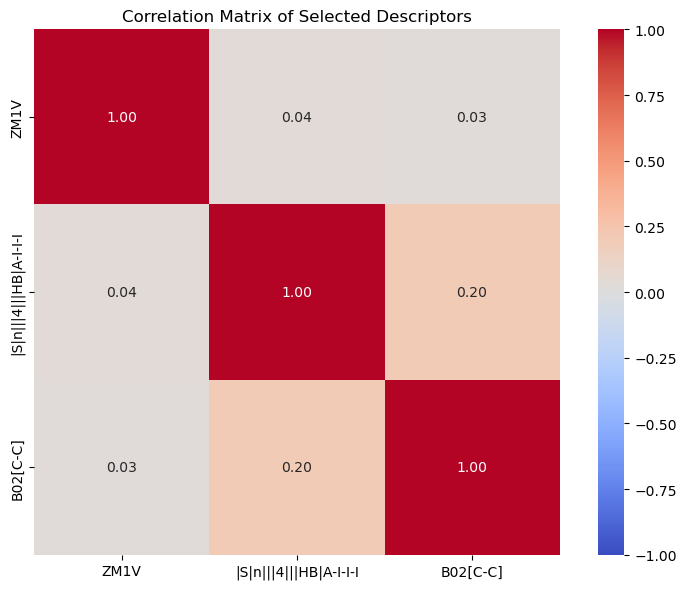


Y-randomization: 500 permutations on features ['ZM1V', '|S|n|||4|||HB|A-I-I-I', 'B02[C-C]']
Original model (CV): F1 = 0.7333 | BA = 0.8035 | ROC-AUC = 0.7776
Randomized (avg):    F1 = 0.0917 | BA = 0.5024 | ROC-AUC = 0.4937
Randomized (max):    F1 = 0.5714 | BA = 0.7053 | ROC-AUC = 0.7924
Permutations reaching the original ROC-AUC: 0.002

Model  Average F1  Average Balanced Accuracy  Average ROC-AUC
 H332      0.0917                     0.5024           0.4937


In [20]:
#H332

import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.feature_selection import VarianceThreshold
from sklearn.metrics import (
    matthews_corrcoef,
    f1_score,
    balanced_accuracy_score,
    cohen_kappa_score,
    roc_auc_score
)



TEST_SIZE = 0.25
VAR_THRESHOLD = 0.01
CORR_THRESHOLD = 0.90
N_FEATURES = 3
N_OUTER = 3
N_INNER = 3
AD_K = 3


DATA_FILE = "H332.xlsx"
new_solvent_path = "Smiles_desc_distinct_cleaned.xlsx"

def filter_features(X):
    vt = VarianceThreshold(threshold=VAR_THRESHOLD).fit(X)
    cols = X.columns[vt.get_support()]
    corr = X[cols].corr().abs()
    upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
    to_drop = {c for c in upper.columns if any(upper[c] > CORR_THRESHOLD)}
    return [c for c in cols if c not in to_drop]


def fast_mcc(y_true, y_pred):
    tp = np.sum((y_true == 1) & (y_pred == 1))
    tn = np.sum((y_true == 0) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    denom = np.sqrt(float((tp + fp) * (tp + fn) * (tn + fp) * (tn + fn)))
    return 0.0 if denom == 0 else (tp * tn - fp * fn) / denom


def forward_selection(X, y, cv):
    names = list(X.columns)
    Xv, yv = X.to_numpy(dtype=float), y.to_numpy()
    folds = []
    for tr, va in cv.split(Xv, yv):
        sc = StandardScaler().fit(Xv[tr])
        folds.append((sc.transform(Xv[tr]), yv[tr], sc.transform(Xv[va]), yv[va]))

    selected, remaining = [], list(range(len(names)))
    for _ in range(N_FEATURES):
        best_score, best_j = -np.inf, None
        for j in remaining:
            cols = selected + [j]
            scores = []
            for X_tr, y_tr, X_va, y_va in folds:
                m = make_model().fit(X_tr[:, cols], y_tr)
                scores.append(fast_mcc(y_va, m.predict(X_va[:, cols])))
            s = np.mean(scores)
            if s > best_score:
                best_score, best_j = s, j
        selected.append(best_j)
        remaining.remove(best_j)
    return [names[j] for j in selected]


def all_metrics(y_true, y_pred, y_proba):
    return {
        "Balanced Accuracy": balanced_accuracy_score(y_true, y_pred),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "MCC": matthews_corrcoef(y_true, y_pred),
        "Cohen's Kappa": cohen_kappa_score(y_true, y_pred),
        "ROC-AUC": roc_auc_score(y_true, y_proba) if len(np.unique(y_true)) == 2 else np.nan,
    }


def ad_distance(X_scaled, centroid):
    return np.linalg.norm(np.asarray(X_scaled, dtype=float) - centroid, axis=1)


def make_model():
    return KNeighborsClassifier(n_neighbors=7, weights="uniform", metric="euclidean")


full_df = pd.read_excel(DATA_FILE)
names = full_df.iloc[:, 0]
X = full_df.iloc[:, 1:-1]
y = full_df.iloc[:, -1]

X_train, X_test, y_train, y_test, names_train, names_test = train_test_split(
    X, y, names, test_size=TEST_SIZE, stratify=y, random_state=25
)
X_train = X_train.reset_index(drop=True)
y_train = y_train.reset_index(drop=True)
X_test = X_test.reset_index(drop=True)
y_test = y_test.reset_index(drop=True)
names_train = names_train.reset_index(drop=True)
names_test = names_test.reset_index(drop=True)


outer_cv = StratifiedKFold(n_splits=N_OUTER, shuffle=True, random_state=25)
inner_cv = StratifiedKFold(n_splits=N_INNER, shuffle=True, random_state=25)

fold_results = []
fold_features = []

for fold, (tr_idx, va_idx) in enumerate(outer_cv.split(X_train, y_train), 1):
    X_tr = X_train.iloc[tr_idx].reset_index(drop=True)
    X_va = X_train.iloc[va_idx].reset_index(drop=True)
    y_tr = y_train.iloc[tr_idx].reset_index(drop=True)
    y_va = y_train.iloc[va_idx].reset_index(drop=True)

    kept = filter_features(X_tr)
    feats = forward_selection(X_tr[kept], y_tr, inner_cv)

    fold_scaler = StandardScaler().fit(X_tr[feats])
    model = make_model().fit(fold_scaler.transform(X_tr[feats]), y_tr)

    X_va_s = fold_scaler.transform(X_va[feats])
    y_pred = model.predict(X_va_s)
    y_proba = model.predict_proba(X_va_s)[:, 1]

    fold_results.append(all_metrics(y_va, y_pred, y_proba))
    fold_features.append(feats)

nested_df = pd.DataFrame(fold_results)


kept = filter_features(X_train)
selected_features = forward_selection(X_train[kept], y_train, inner_cv)

scaler = StandardScaler().fit(X_train[selected_features])
X_train_final = pd.DataFrame(scaler.transform(X_train[selected_features]), columns=selected_features)
X_test_final = pd.DataFrame(scaler.transform(X_test[selected_features]), columns=selected_features)

final_model = make_model().fit(X_train_final, y_train)

y_train_pred = final_model.predict(X_train_final)
y_test_pred = final_model.predict(X_test_final)
y_train_proba = final_model.predict_proba(X_train_final)[:, 1]
y_test_proba = final_model.predict_proba(X_test_final)[:, 1]

train_m = all_metrics(y_train, y_train_pred, y_train_proba)
test_m = all_metrics(y_test, y_test_pred, y_test_proba)
metric_names = list(train_m)

metrics = pd.DataFrame(
    [[len(y_train)] + [round(v, 4) for v in train_m.values()]
     + [len(y_test)] + [round(v, 4) for v in test_m.values()]],
    columns=["N_train"] + metric_names + ["N_test"] + metric_names,
)

print("Final descriptors:", selected_features)
print()
print(metrics.to_string(index=False))


train_centroid = X_train_final.mean(axis=0).to_numpy()
train_distances = ad_distance(X_train_final, train_centroid)
AD_THRESHOLD = train_distances.mean() + AD_K * train_distances.std()
test_distances = ad_distance(X_test_final, train_centroid)

new_df = pd.read_excel(new_solvent_path)
missing = [f for f in selected_features if f not in new_df.columns]
if missing:
    raise ValueError(f"Descriptors missing from new solvent file: {missing}")

new_names = new_df.iloc[:, 0]
X_new_raw = new_df[selected_features].apply(pd.to_numeric, errors="coerce")
valid = X_new_raw.notna().all(axis=1).to_numpy()

new_pred = np.full(len(X_new_raw), np.nan)
new_proba = np.full(len(X_new_raw), np.nan)
new_distances = np.full(len(X_new_raw), np.nan)

if valid.any():
    X_new_scaled = pd.DataFrame(scaler.transform(X_new_raw.loc[valid, selected_features]),
                                columns=selected_features)
    new_pred[valid] = final_model.predict(X_new_scaled)
    new_proba[valid] = final_model.predict_proba(X_new_scaled)[:, 1]
    new_distances[valid] = ad_distance(X_new_scaled, train_centroid)

train_in_ad = train_distances <= AD_THRESHOLD
test_in_ad = test_distances <= AD_THRESHOLD
new_in_ad = valid & (np.nan_to_num(new_distances, nan=np.inf) <= AD_THRESHOLD)

ad_summary = pd.DataFrame({
    "Set": ["Train", "Test", "New solvents"],
    "Inside AD": [int(train_in_ad.sum()), int(test_in_ad.sum()), int(new_in_ad.sum())],
    "Total": [len(train_distances), len(test_distances), int(valid.sum())],
})
ad_summary["Inside AD (%)"] = (100 * ad_summary["Inside AD"] / ad_summary["Total"]).round(1)

print(f"\nApplicability domain (distance threshold = {AD_THRESHOLD:.4f}, mean + {AD_K}·SD)")
print(ad_summary.to_string(index=False))
if (~valid).any():
    print(f"{int((~valid).sum())} new solvents skipped (missing descriptor values)")

new_predictions = pd.DataFrame({
    "Solvent_Name": new_names.values,
    "Predicted_Class": pd.Series(new_pred).astype("Int64").values,
    "Prob_Class1": new_proba,
    "Distance": new_distances,
    "AD_Status": np.where(~valid, "Not predicted",
                          np.where(new_in_ad, "Inside AD", "Outside AD")),
})

print(f"\nNew solvents: predicted class 1 = {int(np.nansum(new_pred == 1))}, "
      f"predicted class 0 = {int(np.nansum(new_pred == 0))}")


plt.figure(figsize=(8, 6))
sns.heatmap(X_train[selected_features].corr(), annot=True, cmap="coolwarm", fmt=".2f",
            vmin=-1, vmax=1, square=True)
plt.title("Correlation Matrix of Selected Descriptors")
plt.tight_layout()
plt.show()

ENDPOINT_NAME = "H332"
N_PERMUTATIONS = 500


def cv_metrics(X_mat, y_vec, seed):
    cv = StratifiedKFold(n_splits=N_OUTER, shuffle=True, random_state=seed)
    pred = np.empty(len(y_vec))
    proba = np.empty(len(y_vec))
    for tr, va in cv.split(X_mat, y_vec):
        m = make_model().fit(X_mat.iloc[tr], y_vec[tr])
        pred[va] = m.predict(X_mat.iloc[va])
        proba[va] = m.predict_proba(X_mat.iloc[va])[:, 1]
    return (f1_score(y_vec, pred, zero_division=0),
            balanced_accuracy_score(y_vec, pred),
            roc_auc_score(y_vec, proba))


y_tr_np = y_train.to_numpy()
F1_orig, BA_orig, AUC_orig = cv_metrics(X_train_final, y_tr_np, 25)

rng = np.random.default_rng(2024)
rows = [cv_metrics(X_train_final, rng.permutation(y_tr_np), 25) for _ in range(N_PERMUTATIONS)]
yr = pd.DataFrame(rows, columns=["F1", "Balanced Accuracy", "ROC-AUC"])

print(f"\nY-randomization: {N_PERMUTATIONS} permutations on features {selected_features}")
print(f"Original model (CV): F1 = {F1_orig:.4f} | BA = {BA_orig:.4f} | ROC-AUC = {AUC_orig:.4f}")
print(f"Randomized (avg):    F1 = {yr['F1'].mean():.4f} | BA = {yr['Balanced Accuracy'].mean():.4f} | ROC-AUC = {yr['ROC-AUC'].mean():.4f}")
print(f"Randomized (max):    F1 = {yr['F1'].max():.4f} | BA = {yr['Balanced Accuracy'].max():.4f} | ROC-AUC = {yr['ROC-AUC'].max():.4f}")
print(f"Permutations reaching the original ROC-AUC: {(yr['ROC-AUC'] >= AUC_orig).mean():.3f}")

summary = pd.DataFrame([{
    "Model": ENDPOINT_NAME,
    "Average F1": round(yr["F1"].mean(), 4),
    "Average Balanced Accuracy": round(yr["Balanced Accuracy"].mean(), 4),
    "Average ROC-AUC": round(yr["ROC-AUC"].mean(), 4),
}])
print("\n" + summary.to_string(index=False))

Final descriptors: ['|S|n|||1|||LOGP|D', 'SpMax7_Bh(m)']

 N_train  Balanced Accuracy     F1    MCC  Cohen's Kappa  ROC-AUC  N_test  Balanced Accuracy     F1    MCC  Cohen's Kappa  ROC-AUC
      71             0.7185 0.6122 0.4162         0.4112   0.7333      24               0.75 0.6667 0.5186         0.5161   0.7734

Model equation:
logit(P) = ln(P / (1 - P)) = -0.4660 + 0.7345 * |S|n|||1|||LOGP|D - 0.5627 * SpMax7_Bh(m)
P(class 1) = 1 / (1 + exp(-logit(P)))   ->   class 1 if P >= 0.5

Applicability domain (h* = 0.1268)
         Set  Inside AD  Total  Inside AD (%)
       Train         67     71           94.4
        Test         22     24           91.7
New solvents         79    105           75.2

New solvents: predicted class 1 = 45, predicted class 0 = 60


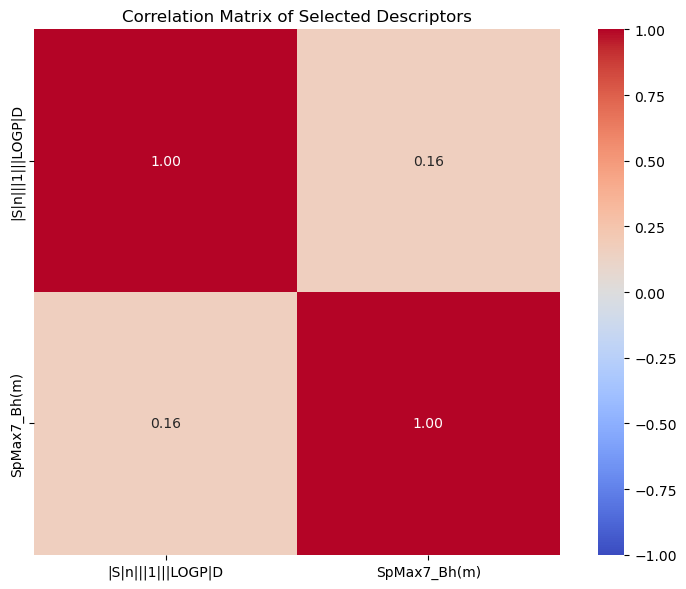


Y-randomization: 500 permutations on features ['|S|n|||1|||LOGP|D', 'SpMax7_Bh(m)']
Original model (CV): F1 = 0.6383 | BA = 0.7389 | ROC-AUC = 0.6929
Randomized (avg):    F1 = 0.3773 | BA = 0.5022 | ROC-AUC = 0.4911
Randomized (max):    F1 = 0.6032 | BA = 0.7073 | ROC-AUC = 0.7699
Permutations reaching the original ROC-AUC: 0.002

Model  Average F1  Average Balanced Accuracy  Average ROC-AUC
 H335      0.3773                     0.5022           0.4911


In [21]:
#H335

import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import VarianceThreshold
from sklearn.metrics import (
    matthews_corrcoef,
    f1_score,
    balanced_accuracy_score,
    cohen_kappa_score,
    roc_auc_score
)


TEST_SIZE = 0.25
VAR_THRESHOLD = 0.01
CORR_THRESHOLD = 0.90
N_FEATURES = 2
N_OUTER = 3
N_INNER = 3


DATA_FILE = "H335.xlsx"
new_solvent_path = "Smiles_desc_distinct_cleaned.xlsx"


def filter_features(X):
    vt = VarianceThreshold(threshold=VAR_THRESHOLD).fit(X)
    cols = X.columns[vt.get_support()]
    corr = X[cols].corr().abs()
    upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
    to_drop = {c for c in upper.columns if any(upper[c] > CORR_THRESHOLD)}
    return [c for c in cols if c not in to_drop]


def fast_mcc(y_true, y_pred):
    tp = np.sum((y_true == 1) & (y_pred == 1))
    tn = np.sum((y_true == 0) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    denom = np.sqrt(float((tp + fp) * (tp + fn) * (tn + fp) * (tn + fn)))
    return 0.0 if denom == 0 else (tp * tn - fp * fn) / denom


def forward_selection(X, y, cv):
    names = list(X.columns)
    Xv, yv = X.to_numpy(dtype=float), y.to_numpy()
    folds = [(Xv[tr], yv[tr], Xv[va], yv[va]) for tr, va in cv.split(Xv, yv)]

    selected, remaining = [], list(range(len(names)))
    for _ in range(N_FEATURES):
        best_score, best_j = -np.inf, None
        for j in remaining:
            cols = selected + [j]
            scores = []
            for X_tr, y_tr, X_va, y_va in folds:
                m = make_model().fit(X_tr[:, cols], y_tr)
                scores.append(fast_mcc(y_va, m.predict(X_va[:, cols])))
            s = np.mean(scores)
            if s > best_score:
                best_score, best_j = s, j
        selected.append(best_j)
        remaining.remove(best_j)
    return [names[j] for j in selected]


def all_metrics(y_true, y_pred, y_proba):
    return {
        "Balanced Accuracy": balanced_accuracy_score(y_true, y_pred),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "MCC": matthews_corrcoef(y_true, y_pred),
        "Cohen's Kappa": cohen_kappa_score(y_true, y_pred),
        "ROC-AUC": roc_auc_score(y_true, y_proba) if len(np.unique(y_true)) == 2 else np.nan,
    }


def add_intercept(X_mat):
    X_mat = np.asarray(X_mat, dtype=float)
    return np.column_stack([np.ones(len(X_mat)), X_mat])


def compute_leverage(X_mat, XtX_inv):
    Xa = add_intercept(X_mat)
    return np.einsum("ij,jk,ik->i", Xa, XtX_inv, Xa)


full_df = pd.read_excel(DATA_FILE)
X = full_df.iloc[:, 1:-1]
y = full_df.iloc[:, -1]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=57
)
X_train = X_train.reset_index(drop=True)
y_train = y_train.reset_index(drop=True)
X_test = X_test.reset_index(drop=True)
y_test = y_test.reset_index(drop=True)


outer_cv = StratifiedKFold(n_splits=N_OUTER, shuffle=True, random_state=57)
inner_cv = StratifiedKFold(n_splits=N_INNER, shuffle=True, random_state=57)

fold_results = []
fold_features = []

for fold, (tr_idx, va_idx) in enumerate(outer_cv.split(X_train, y_train), 1):
    X_tr = X_train.iloc[tr_idx].reset_index(drop=True)
    X_va = X_train.iloc[va_idx].reset_index(drop=True)
    y_tr = y_train.iloc[tr_idx].reset_index(drop=True)
    y_va = y_train.iloc[va_idx].reset_index(drop=True)

    kept = filter_features(X_tr)
    feats = forward_selection(X_tr[kept], y_tr, inner_cv)

    model = make_model().fit(X_tr[feats], y_tr)
    y_pred = model.predict(X_va[feats])
    y_proba = model.predict_proba(X_va[feats])[:, 1]

    fold_results.append(all_metrics(y_va, y_pred, y_proba))
    fold_features.append(feats)

nested_df = pd.DataFrame(fold_results)

def make_model():
    return LogisticRegression(class_weight="balanced", max_iter=500, random_state=57)





kept = filter_features(X_train)
selected_features = forward_selection(X_train[kept], y_train, inner_cv)

X_train_final = X_train[selected_features]
X_test_final = X_test[selected_features]

final_model = make_model().fit(X_train_final, y_train)

y_train_pred = final_model.predict(X_train_final)
y_test_pred = final_model.predict(X_test_final)
y_train_proba = final_model.predict_proba(X_train_final)[:, 1]
y_test_proba = final_model.predict_proba(X_test_final)[:, 1]

train_m = all_metrics(y_train, y_train_pred, y_train_proba)
test_m = all_metrics(y_test, y_test_pred, y_test_proba)
metric_names = list(train_m)

metrics = pd.DataFrame(
    [[len(y_train)] + [round(v, 4) for v in train_m.values()]
     + [len(y_test)] + [round(v, 4) for v in test_m.values()]],
    columns=["N_train"] + metric_names + ["N_test"] + metric_names,
)

print("Final descriptors:", selected_features)
print()
print(metrics.to_string(index=False))


intercept = final_model.intercept_[0]
terms = [f"{intercept:.4f}"]
for coef, name in zip(final_model.coef_[0], selected_features):
    sign = "+" if coef >= 0 else "-"
    terms.append(f"{sign} {abs(coef):.4f} * {name}")
logit_expr = " ".join(terms)

print("\nModel equation:")
print(f"logit(P) = ln(P / (1 - P)) = {logit_expr}")
print("P(class 1) = 1 / (1 + exp(-logit(P)))   ->   class 1 if P >= 0.5")


new_df = pd.read_excel(new_solvent_path)
missing = [f for f in selected_features if f not in new_df.columns]
if missing:
    raise ValueError(f"Descriptors missing from new solvent file: {missing}")

new_names = new_df.iloc[:, 0]
X_new_raw = new_df[selected_features].apply(pd.to_numeric, errors="coerce")
valid = X_new_raw.notna().all(axis=1).to_numpy()

new_pred = np.full(len(X_new_raw), np.nan)
new_proba = np.full(len(X_new_raw), np.nan)
if valid.any():
    X_new_valid = X_new_raw.loc[valid, selected_features]
    new_pred[valid] = final_model.predict(X_new_valid)
    new_proba[valid] = final_model.predict_proba(X_new_valid)[:, 1]


X_tr_aug = add_intercept(X_train_final)
n_train = X_tr_aug.shape[0]
p = len(selected_features)
XtX_inv = np.linalg.pinv(X_tr_aug.T @ X_tr_aug)
H_THRESHOLD = 3 * (p + 1) / n_train

train_leverages = compute_leverage(X_train_final, XtX_inv)
test_leverages = compute_leverage(X_test_final, XtX_inv)
new_leverages = np.full(len(X_new_raw), np.nan)
if valid.any():
    new_leverages[valid] = compute_leverage(X_new_raw.loc[valid, selected_features], XtX_inv)

train_in_ad = train_leverages <= H_THRESHOLD
test_in_ad = test_leverages <= H_THRESHOLD
new_in_ad = valid & (np.nan_to_num(new_leverages, nan=np.inf) <= H_THRESHOLD)

ad_summary = pd.DataFrame({
    "Set": ["Train", "Test", "New solvents"],
    "Inside AD": [int(train_in_ad.sum()), int(test_in_ad.sum()), int(new_in_ad.sum())],
    "Total": [len(train_leverages), len(test_leverages), int(valid.sum())],
})
ad_summary["Inside AD (%)"] = (100 * ad_summary["Inside AD"] / ad_summary["Total"]).round(1)

print(f"\nApplicability domain (h* = {H_THRESHOLD:.4f})")
print(ad_summary.to_string(index=False))
if (~valid).any():
    print(f"{int((~valid).sum())} new solvents skipped (missing descriptor values)")

new_predictions = pd.DataFrame({
    "Solvent_Name": new_names.values,
    "Predicted_Class": pd.Series(new_pred).astype("Int64").values,
    "Prob_Class1": new_proba,
    "Leverage": new_leverages,
    "AD_Status": np.where(~valid, "Not predicted",
                          np.where(new_in_ad, "Inside AD", "Outside AD")),
})

print(f"\nNew solvents: predicted class 1 = {int(np.nansum(new_pred == 1))}, "
      f"predicted class 0 = {int(np.nansum(new_pred == 0))}")


plt.figure(figsize=(8, 6))
sns.heatmap(X_train_final.corr(), annot=True, cmap="coolwarm", fmt=".2f",
            vmin=-1, vmax=1, square=True)
plt.title("Correlation Matrix of Selected Descriptors")
plt.tight_layout()
plt.show()

ENDPOINT_NAME = "H335"
N_PERMUTATIONS = 500


def cv_metrics(X_mat, y_vec, seed):
    cv = StratifiedKFold(n_splits=N_OUTER, shuffle=True, random_state=seed)
    pred = np.empty(len(y_vec))
    proba = np.empty(len(y_vec))
    for tr, va in cv.split(X_mat, y_vec):
        m = make_model().fit(X_mat.iloc[tr], y_vec[tr])
        pred[va] = m.predict(X_mat.iloc[va])
        proba[va] = m.predict_proba(X_mat.iloc[va])[:, 1]
    return (f1_score(y_vec, pred, zero_division=0),
            balanced_accuracy_score(y_vec, pred),
            roc_auc_score(y_vec, proba))


y_tr_np = y_train.to_numpy()
F1_orig, BA_orig, AUC_orig = cv_metrics(X_train_final, y_tr_np, 57)

rng = np.random.default_rng(2024)
rows = [cv_metrics(X_train_final, rng.permutation(y_tr_np), 57) for _ in range(N_PERMUTATIONS)]
yr = pd.DataFrame(rows, columns=["F1", "Balanced Accuracy", "ROC-AUC"])

print(f"\nY-randomization: {N_PERMUTATIONS} permutations on features {selected_features}")
print(f"Original model (CV): F1 = {F1_orig:.4f} | BA = {BA_orig:.4f} | ROC-AUC = {AUC_orig:.4f}")
print(f"Randomized (avg):    F1 = {yr['F1'].mean():.4f} | BA = {yr['Balanced Accuracy'].mean():.4f} | ROC-AUC = {yr['ROC-AUC'].mean():.4f}")
print(f"Randomized (max):    F1 = {yr['F1'].max():.4f} | BA = {yr['Balanced Accuracy'].max():.4f} | ROC-AUC = {yr['ROC-AUC'].max():.4f}")
print(f"Permutations reaching the original ROC-AUC: {(yr['ROC-AUC'] >= AUC_orig).mean():.3f}")

summary = pd.DataFrame([{
    "Model": ENDPOINT_NAME,
    "Average F1": round(yr["F1"].mean(), 4),
    "Average Balanced Accuracy": round(yr["Balanced Accuracy"].mean(), 4),
    "Average ROC-AUC": round(yr["ROC-AUC"].mean(), 4),
}])
print("\n" + summary.to_string(index=False))

Final descriptors: ['Melting Point (model 501)', 'H-047']

 N_train  Balanced Accuracy  F1    MCC  Cohen's Kappa  ROC-AUC  N_test  Balanced Accuracy     F1    MCC  Cohen's Kappa  ROC-AUC
      63             0.8571 0.8 0.6934         0.6897   0.9082      22             0.8667 0.7778 0.6831         0.6364   0.9333

Model equation:
logit(P) = ln(P / (1 - P)) = -0.9827 - 0.0454 * Melting Point (model 501) - 0.3687 * H-047

Applicability domain (h* = 0.1429)
         Set  Inside AD  Total  Inside AD (%)
       Train         61     63           96.8
        Test         21     22           95.5
New solvents        104    105           99.0


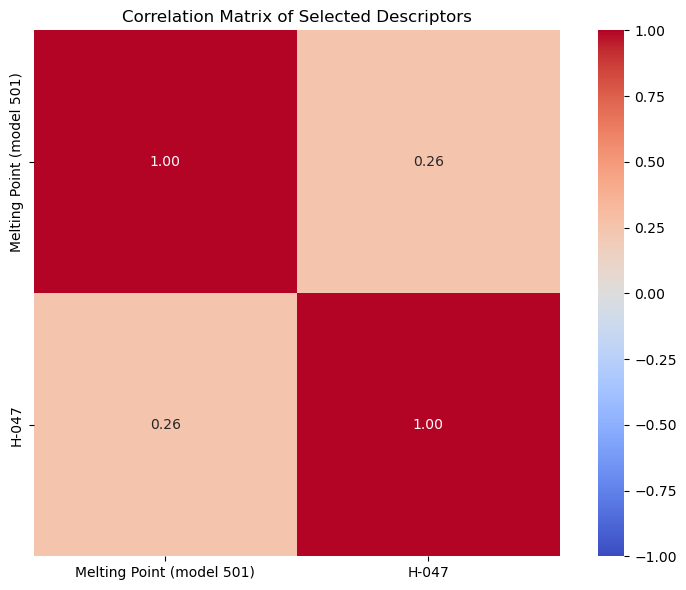


Y-randomization: 500 permutations on features ['Melting Point (model 501)', 'H-047']
Original model (CV): F1 = 0.8085 | BA = 0.8690 | ROC-AUC = 0.8946
Randomized (avg):    F1 = 0.3893 | BA = 0.5008 | ROC-AUC = 0.4964
Randomized (max):    F1 = 0.6383 | BA = 0.7262 | ROC-AUC = 0.7528
Permutations reaching the original ROC-AUC: 0.000

Model  Average F1  Average Balanced Accuracy  Average ROC-AUC
 H336      0.3893                     0.5008           0.4964


In [22]:
#H336

import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import VarianceThreshold
from sklearn.metrics import (
    matthews_corrcoef,
    f1_score,
    balanced_accuracy_score,
    cohen_kappa_score,
    roc_auc_score
)



TEST_SIZE = 0.25
VAR_THRESHOLD = 0.01
CORR_THRESHOLD = 0.90
N_FEATURES = 2
N_OUTER = 3
N_INNER = 3

DATA_FILE = "H336.xlsx"
new_solvent_path = "Smiles_desc_distinct_cleaned.xlsx"


def filter_features(X):
    vt = VarianceThreshold(threshold=VAR_THRESHOLD).fit(X)
    cols = X.columns[vt.get_support()]
    corr = X[cols].corr().abs()
    upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
    to_drop = {c for c in upper.columns if any(upper[c] > CORR_THRESHOLD)}
    return [c for c in cols if c not in to_drop]


def fast_mcc(y_true, y_pred):
    tp = np.sum((y_true == 1) & (y_pred == 1))
    tn = np.sum((y_true == 0) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    denom = np.sqrt(float((tp + fp) * (tp + fn) * (tn + fp) * (tn + fn)))
    return 0.0 if denom == 0 else (tp * tn - fp * fn) / denom


def forward_selection(X, y, cv):
    names = list(X.columns)
    Xv, yv = X.to_numpy(dtype=float), y.to_numpy()
    folds = [(Xv[tr], yv[tr], Xv[va], yv[va]) for tr, va in cv.split(Xv, yv)]

    selected, remaining = [], list(range(len(names)))
    for _ in range(N_FEATURES):
        best_score, best_j = -np.inf, None
        for j in remaining:
            cols = selected + [j]
            scores = []
            for X_tr, y_tr, X_va, y_va in folds:
                m = make_model().fit(X_tr[:, cols], y_tr)
                scores.append(fast_mcc(y_va, m.predict(X_va[:, cols])))
            s = np.mean(scores)
            if s > best_score:
                best_score, best_j = s, j
        selected.append(best_j)
        remaining.remove(best_j)
    return [names[j] for j in selected]


def all_metrics(y_true, y_pred, y_proba):
    return {
        "Balanced Accuracy": balanced_accuracy_score(y_true, y_pred),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "MCC": matthews_corrcoef(y_true, y_pred),
        "Cohen's Kappa": cohen_kappa_score(y_true, y_pred),
        "ROC-AUC": roc_auc_score(y_true, y_proba) if len(np.unique(y_true)) == 2 else np.nan,
    }


def add_intercept(X_mat):
    X_mat = np.asarray(X_mat, dtype=float)
    return np.column_stack([np.ones(len(X_mat)), X_mat])


def compute_leverage(X_mat, XtX_inv):
    Xa = add_intercept(X_mat)
    return np.einsum("ij,jk,ik->i", Xa, XtX_inv, Xa)


full_df = pd.read_excel(DATA_FILE)
X = full_df.iloc[:, 1:-1]
y = full_df.iloc[:, -1]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=2
)
X_train = X_train.reset_index(drop=True)
y_train = y_train.reset_index(drop=True)
X_test = X_test.reset_index(drop=True)
y_test = y_test.reset_index(drop=True)


outer_cv = StratifiedKFold(n_splits=N_OUTER, shuffle=True, random_state=2)
inner_cv = StratifiedKFold(n_splits=N_INNER, shuffle=True, random_state=2)

fold_results = []
fold_features = []

for fold, (tr_idx, va_idx) in enumerate(outer_cv.split(X_train, y_train), 1):
    X_tr = X_train.iloc[tr_idx].reset_index(drop=True)
    X_va = X_train.iloc[va_idx].reset_index(drop=True)
    y_tr = y_train.iloc[tr_idx].reset_index(drop=True)
    y_va = y_train.iloc[va_idx].reset_index(drop=True)

    kept = filter_features(X_tr)
    feats = forward_selection(X_tr[kept], y_tr, inner_cv)

    model = make_model().fit(X_tr[feats], y_tr)
    y_pred = model.predict(X_va[feats])
    y_proba = model.predict_proba(X_va[feats])[:, 1]

    fold_results.append(all_metrics(y_va, y_pred, y_proba))
    fold_features.append(feats)

nested_df = pd.DataFrame(fold_results)

def make_model():
    return LogisticRegression(class_weight="balanced", max_iter=500, random_state=2)





kept = filter_features(X_train)
selected_features = forward_selection(X_train[kept], y_train, inner_cv)

X_train_final = X_train[selected_features]
X_test_final = X_test[selected_features]

final_model = make_model().fit(X_train_final, y_train)

y_train_pred = final_model.predict(X_train_final)
y_test_pred = final_model.predict(X_test_final)
y_train_proba = final_model.predict_proba(X_train_final)[:, 1]
y_test_proba = final_model.predict_proba(X_test_final)[:, 1]

train_m = all_metrics(y_train, y_train_pred, y_train_proba)
test_m = all_metrics(y_test, y_test_pred, y_test_proba)
metric_names = list(train_m)

metrics = pd.DataFrame(
    [[len(y_train)] + [round(v, 4) for v in train_m.values()]
     + [len(y_test)] + [round(v, 4) for v in test_m.values()]],
    columns=["N_train"] + metric_names + ["N_test"] + metric_names,
)

print("Final descriptors:", selected_features)
print()
print(metrics.to_string(index=False))


intercept = final_model.intercept_[0]
terms = [f"{intercept:.4f}"]
for coef, name in zip(final_model.coef_[0], selected_features):
    sign = "+" if coef >= 0 else "-"
    terms.append(f"{sign} {abs(coef):.4f} * {name}")
logit_expr = " ".join(terms)

print("\nModel equation:")
print(f"logit(P) = ln(P / (1 - P)) = {logit_expr}")



new_df = pd.read_excel(new_solvent_path)
missing = [f for f in selected_features if f not in new_df.columns]
if missing:
    raise ValueError(f"Descriptors missing from new solvent file: {missing}")

new_names = new_df.iloc[:, 0]
X_new_raw = new_df[selected_features].apply(pd.to_numeric, errors="coerce")
valid = X_new_raw.notna().all(axis=1).to_numpy()

new_pred = np.full(len(X_new_raw), np.nan)
new_proba = np.full(len(X_new_raw), np.nan)
if valid.any():
    X_new_valid = X_new_raw.loc[valid, selected_features]
    new_pred[valid] = final_model.predict(X_new_valid)
    new_proba[valid] = final_model.predict_proba(X_new_valid)[:, 1]


X_tr_aug = add_intercept(X_train_final)
n_train = X_tr_aug.shape[0]
p = len(selected_features)
XtX_inv = np.linalg.pinv(X_tr_aug.T @ X_tr_aug)
H_THRESHOLD = 3 * (p + 1) / n_train

train_leverages = compute_leverage(X_train_final, XtX_inv)
test_leverages = compute_leverage(X_test_final, XtX_inv)
new_leverages = np.full(len(X_new_raw), np.nan)
if valid.any():
    new_leverages[valid] = compute_leverage(X_new_raw.loc[valid, selected_features], XtX_inv)

train_in_ad = train_leverages <= H_THRESHOLD
test_in_ad = test_leverages <= H_THRESHOLD
new_in_ad = valid & (np.nan_to_num(new_leverages, nan=np.inf) <= H_THRESHOLD)

ad_summary = pd.DataFrame({
    "Set": ["Train", "Test", "New solvents"],
    "Inside AD": [int(train_in_ad.sum()), int(test_in_ad.sum()), int(new_in_ad.sum())],
    "Total": [len(train_leverages), len(test_leverages), int(valid.sum())],
})
ad_summary["Inside AD (%)"] = (100 * ad_summary["Inside AD"] / ad_summary["Total"]).round(1)

print(f"\nApplicability domain (h* = {H_THRESHOLD:.4f})")
print(ad_summary.to_string(index=False))
if (~valid).any():
    print(f"{int((~valid).sum())} new solvents skipped (missing descriptor values)")

new_predictions = pd.DataFrame({
    "Solvent_Name": new_names.values,
    "Predicted_Class": pd.Series(new_pred).astype("Int64").values,
    "Prob_Class1": new_proba,
    "Leverage": new_leverages,
    "AD_Status": np.where(~valid, "Not predicted",
                          np.where(new_in_ad, "Inside AD", "Outside AD")),
})




plt.figure(figsize=(8, 6))
sns.heatmap(X_train_final.corr(), annot=True, cmap="coolwarm", fmt=".2f",
            vmin=-1, vmax=1, square=True)
plt.title("Correlation Matrix of Selected Descriptors")
plt.tight_layout()
plt.show()


ENDPOINT_NAME = "H336"
N_PERMUTATIONS = 500


def cv_metrics(X_mat, y_vec, seed):
    cv = StratifiedKFold(n_splits=N_OUTER, shuffle=True, random_state=seed)
    pred = np.empty(len(y_vec))
    proba = np.empty(len(y_vec))
    for tr, va in cv.split(X_mat, y_vec):
        m = make_model().fit(X_mat.iloc[tr], y_vec[tr])
        pred[va] = m.predict(X_mat.iloc[va])
        proba[va] = m.predict_proba(X_mat.iloc[va])[:, 1]
    return (f1_score(y_vec, pred, zero_division=0),
            balanced_accuracy_score(y_vec, pred),
            roc_auc_score(y_vec, proba))


y_tr_np = y_train.to_numpy()
F1_orig, BA_orig, AUC_orig = cv_metrics(X_train_final, y_tr_np, 2)

rng = np.random.default_rng(2024)
rows = [cv_metrics(X_train_final, rng.permutation(y_tr_np), 2) for _ in range(N_PERMUTATIONS)]
yr = pd.DataFrame(rows, columns=["F1", "Balanced Accuracy", "ROC-AUC"])

print(f"\nY-randomization: {N_PERMUTATIONS} permutations on features {selected_features}")
print(f"Original model (CV): F1 = {F1_orig:.4f} | BA = {BA_orig:.4f} | ROC-AUC = {AUC_orig:.4f}")
print(f"Randomized (avg):    F1 = {yr['F1'].mean():.4f} | BA = {yr['Balanced Accuracy'].mean():.4f} | ROC-AUC = {yr['ROC-AUC'].mean():.4f}")
print(f"Randomized (max):    F1 = {yr['F1'].max():.4f} | BA = {yr['Balanced Accuracy'].max():.4f} | ROC-AUC = {yr['ROC-AUC'].max():.4f}")
print(f"Permutations reaching the original ROC-AUC: {(yr['ROC-AUC'] >= AUC_orig).mean():.3f}")

summary = pd.DataFrame([{
    "Model": ENDPOINT_NAME,
    "Average F1": round(yr["F1"].mean(), 4),
    "Average Balanced Accuracy": round(yr["Balanced Accuracy"].mean(), 4),
    "Average ROC-AUC": round(yr["ROC-AUC"].mean(), 4),
}])
print("\n" + summary.to_string(index=False))

Final descriptors: ['SM1_Dz(e)', 'B03[C-N]']

 N_train  Balanced Accuracy     F1    MCC  Cohen's Kappa  ROC-AUC  N_test  Balanced Accuracy  F1    MCC  Cohen's Kappa  ROC-AUC
      62             0.8468 0.5455 0.5125         0.4627   0.8701      27             0.9167 0.6 0.5976         0.5263    0.875

Model equation:
logit(P) = ln(P / (1 - P)) = 0.2163 - 2.2140 * SM1_Dz(e) + 1.3428 * B03[C-N]

Applicability domain (h* = 0.1452)
         Set  Inside AD  Total  Inside AD (%)
       Train         58     62           93.5
        Test         25     27           92.6
New solvents        103    105           98.1


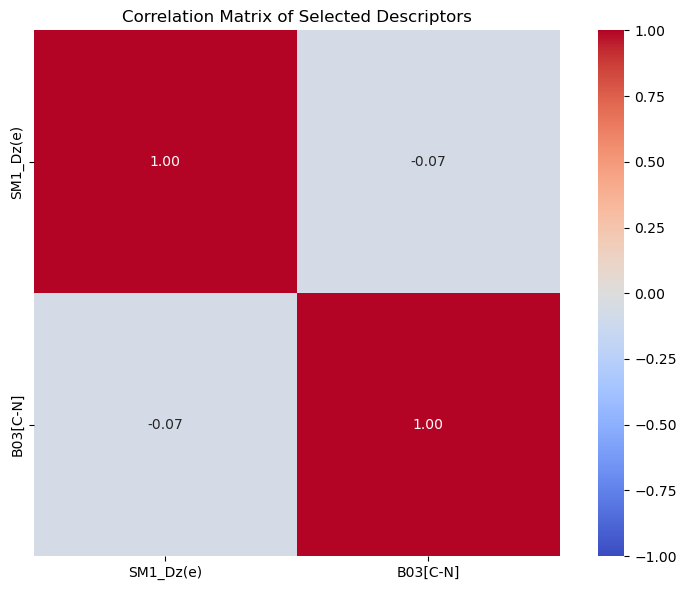


Y-randomization: 500 permutations on features ['SM1_Dz(e)', 'B03[C-N]']
Original model (CV): F1 = 0.5455 | BA = 0.8468 | ROC-AUC = 0.8481
Randomized (avg):    F1 = 0.1656 | BA = 0.4871 | ROC-AUC = 0.4743
Randomized (max):    F1 = 0.5000 | BA = 0.8455 | ROC-AUC = 0.8675
Permutations reaching the original ROC-AUC: 0.002

Model  Average F1  Average Balanced Accuracy  Average ROC-AUC
 H410      0.1656                     0.4871           0.4743


In [23]:
#H410

import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import VarianceThreshold
from sklearn.metrics import (
    matthews_corrcoef,
    f1_score,
    balanced_accuracy_score,
    cohen_kappa_score,
    roc_auc_score
)


TEST_SIZE = 0.3
VAR_THRESHOLD = 0.01
CORR_THRESHOLD = 0.90
N_FEATURES = 2
N_OUTER = 3
N_INNER = 3


DATA_FILE = "H410.xlsx"
new_solvent_path = "Smiles_desc_distinct_cleaned.xlsx"


def filter_features(X):
    vt = VarianceThreshold(threshold=VAR_THRESHOLD).fit(X)
    cols = X.columns[vt.get_support()]
    corr = X[cols].corr().abs()
    upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
    to_drop = {c for c in upper.columns if any(upper[c] > CORR_THRESHOLD)}
    return [c for c in cols if c not in to_drop]


def fast_mcc(y_true, y_pred):
    tp = np.sum((y_true == 1) & (y_pred == 1))
    tn = np.sum((y_true == 0) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    denom = np.sqrt(float((tp + fp) * (tp + fn) * (tn + fp) * (tn + fn)))
    return 0.0 if denom == 0 else (tp * tn - fp * fn) / denom


def forward_selection(X, y, cv):
    names = list(X.columns)
    Xv, yv = X.to_numpy(dtype=float), y.to_numpy()
    folds = [(Xv[tr], yv[tr], Xv[va], yv[va]) for tr, va in cv.split(Xv, yv)]

    selected, remaining = [], list(range(len(names)))
    for _ in range(N_FEATURES):
        best_score, best_j = -np.inf, None
        for j in remaining:
            cols = selected + [j]
            scores = []
            for X_tr, y_tr, X_va, y_va in folds:
                m = make_model().fit(X_tr[:, cols], y_tr)
                scores.append(fast_mcc(y_va, m.predict(X_va[:, cols])))
            s = np.mean(scores)
            if s > best_score:
                best_score, best_j = s, j
        selected.append(best_j)
        remaining.remove(best_j)
    return [names[j] for j in selected]


def all_metrics(y_true, y_pred, y_proba):
    return {
        "Balanced Accuracy": balanced_accuracy_score(y_true, y_pred),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "MCC": matthews_corrcoef(y_true, y_pred),
        "Cohen's Kappa": cohen_kappa_score(y_true, y_pred),
        "ROC-AUC": roc_auc_score(y_true, y_proba) if len(np.unique(y_true)) == 2 else np.nan,
    }


def add_intercept(X_mat):
    X_mat = np.asarray(X_mat, dtype=float)
    return np.column_stack([np.ones(len(X_mat)), X_mat])


def compute_leverage(X_mat, XtX_inv):
    Xa = add_intercept(X_mat)
    return np.einsum("ij,jk,ik->i", Xa, XtX_inv, Xa)


full_df = pd.read_excel(DATA_FILE)
X = full_df.iloc[:, 1:-1]
y = full_df.iloc[:, -1]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=48
)
X_train = X_train.reset_index(drop=True)
y_train = y_train.reset_index(drop=True)
X_test = X_test.reset_index(drop=True)
y_test = y_test.reset_index(drop=True)


outer_cv = StratifiedKFold(n_splits=N_OUTER, shuffle=True, random_state=48)
inner_cv = StratifiedKFold(n_splits=N_INNER, shuffle=True, random_state=48)

fold_results = []
fold_features = []

for fold, (tr_idx, va_idx) in enumerate(outer_cv.split(X_train, y_train), 1):
    X_tr = X_train.iloc[tr_idx].reset_index(drop=True)
    X_va = X_train.iloc[va_idx].reset_index(drop=True)
    y_tr = y_train.iloc[tr_idx].reset_index(drop=True)
    y_va = y_train.iloc[va_idx].reset_index(drop=True)

    kept = filter_features(X_tr)
    feats = forward_selection(X_tr[kept], y_tr, inner_cv)

    model = make_model().fit(X_tr[feats], y_tr)
    y_pred = model.predict(X_va[feats])
    y_proba = model.predict_proba(X_va[feats])[:, 1]

    fold_results.append(all_metrics(y_va, y_pred, y_proba))
    fold_features.append(feats)

nested_df = pd.DataFrame(fold_results)

def make_model():
    return LogisticRegression(class_weight="balanced", max_iter=500, random_state=48)


kept = filter_features(X_train)
selected_features = forward_selection(X_train[kept], y_train, inner_cv)

X_train_final = X_train[selected_features]
X_test_final = X_test[selected_features]

final_model = make_model().fit(X_train_final, y_train)

y_train_pred = final_model.predict(X_train_final)
y_test_pred = final_model.predict(X_test_final)
y_train_proba = final_model.predict_proba(X_train_final)[:, 1]
y_test_proba = final_model.predict_proba(X_test_final)[:, 1]

train_m = all_metrics(y_train, y_train_pred, y_train_proba)
test_m = all_metrics(y_test, y_test_pred, y_test_proba)
metric_names = list(train_m)

metrics = pd.DataFrame(
    [[len(y_train)] + [round(v, 4) for v in train_m.values()]
     + [len(y_test)] + [round(v, 4) for v in test_m.values()]],
    columns=["N_train"] + metric_names + ["N_test"] + metric_names,
)

print("Final descriptors:", selected_features)
print()
print(metrics.to_string(index=False))


intercept = final_model.intercept_[0]
terms = [f"{intercept:.4f}"]
for coef, name in zip(final_model.coef_[0], selected_features):
    sign = "+" if coef >= 0 else "-"
    terms.append(f"{sign} {abs(coef):.4f} * {name}")
logit_expr = " ".join(terms)

print("\nModel equation:")
print(f"logit(P) = ln(P / (1 - P)) = {logit_expr}")


new_df = pd.read_excel(new_solvent_path)
missing = [f for f in selected_features if f not in new_df.columns]
if missing:
    raise ValueError(f"Descriptors missing from new solvent file: {missing}")

new_names = new_df.iloc[:, 0]
X_new_raw = new_df[selected_features].apply(pd.to_numeric, errors="coerce")
valid = X_new_raw.notna().all(axis=1).to_numpy()

new_pred = np.full(len(X_new_raw), np.nan)
new_proba = np.full(len(X_new_raw), np.nan)
if valid.any():
    X_new_valid = X_new_raw.loc[valid, selected_features]
    new_pred[valid] = final_model.predict(X_new_valid)
    new_proba[valid] = final_model.predict_proba(X_new_valid)[:, 1]


X_tr_aug = add_intercept(X_train_final)
n_train = X_tr_aug.shape[0]
p = len(selected_features)
XtX_inv = np.linalg.pinv(X_tr_aug.T @ X_tr_aug)
H_THRESHOLD = 3 * (p + 1) / n_train

train_leverages = compute_leverage(X_train_final, XtX_inv)
test_leverages = compute_leverage(X_test_final, XtX_inv)
new_leverages = np.full(len(X_new_raw), np.nan)
if valid.any():
    new_leverages[valid] = compute_leverage(X_new_raw.loc[valid, selected_features], XtX_inv)

train_in_ad = train_leverages <= H_THRESHOLD
test_in_ad = test_leverages <= H_THRESHOLD
new_in_ad = valid & (np.nan_to_num(new_leverages, nan=np.inf) <= H_THRESHOLD)

ad_summary = pd.DataFrame({
    "Set": ["Train", "Test", "New solvents"],
    "Inside AD": [int(train_in_ad.sum()), int(test_in_ad.sum()), int(new_in_ad.sum())],
    "Total": [len(train_leverages), len(test_leverages), int(valid.sum())],
})
ad_summary["Inside AD (%)"] = (100 * ad_summary["Inside AD"] / ad_summary["Total"]).round(1)

print(f"\nApplicability domain (h* = {H_THRESHOLD:.4f})")
print(ad_summary.to_string(index=False))
if (~valid).any():
    print(f"{int((~valid).sum())} new solvents skipped (missing descriptor values)")

new_predictions = pd.DataFrame({
    "Solvent_Name": new_names.values,
    "Predicted_Class": pd.Series(new_pred).astype("Int64").values,
    "Prob_Class1": new_proba,
    "Leverage": new_leverages,
    "AD_Status": np.where(~valid, "Not predicted",
                          np.where(new_in_ad, "Inside AD", "Outside AD")),
})


plt.figure(figsize=(8, 6))
sns.heatmap(X_train_final.corr(), annot=True, cmap="coolwarm", fmt=".2f",
            vmin=-1, vmax=1, square=True)
plt.title("Correlation Matrix of Selected Descriptors")
plt.tight_layout()
plt.show()

ENDPOINT_NAME = "H410"
N_PERMUTATIONS = 500


def cv_metrics(X_mat, y_vec, seed):
    cv = StratifiedKFold(n_splits=N_OUTER, shuffle=True, random_state=seed)
    pred = np.empty(len(y_vec))
    proba = np.empty(len(y_vec))
    for tr, va in cv.split(X_mat, y_vec):
        m = make_model().fit(X_mat.iloc[tr], y_vec[tr])
        pred[va] = m.predict(X_mat.iloc[va])
        proba[va] = m.predict_proba(X_mat.iloc[va])[:, 1]
    return (f1_score(y_vec, pred, zero_division=0),
            balanced_accuracy_score(y_vec, pred),
            roc_auc_score(y_vec, proba))


y_tr_np = y_train.to_numpy()
F1_orig, BA_orig, AUC_orig = cv_metrics(X_train_final, y_tr_np, 48)

rng = np.random.default_rng(2024)
rows = [cv_metrics(X_train_final, rng.permutation(y_tr_np), 48) for _ in range(N_PERMUTATIONS)]
yr = pd.DataFrame(rows, columns=["F1", "Balanced Accuracy", "ROC-AUC"])

print(f"\nY-randomization: {N_PERMUTATIONS} permutations on features {selected_features}")
print(f"Original model (CV): F1 = {F1_orig:.4f} | BA = {BA_orig:.4f} | ROC-AUC = {AUC_orig:.4f}")
print(f"Randomized (avg):    F1 = {yr['F1'].mean():.4f} | BA = {yr['Balanced Accuracy'].mean():.4f} | ROC-AUC = {yr['ROC-AUC'].mean():.4f}")
print(f"Randomized (max):    F1 = {yr['F1'].max():.4f} | BA = {yr['Balanced Accuracy'].max():.4f} | ROC-AUC = {yr['ROC-AUC'].max():.4f}")
print(f"Permutations reaching the original ROC-AUC: {(yr['ROC-AUC'] >= AUC_orig).mean():.3f}")

summary = pd.DataFrame([{
    "Model": ENDPOINT_NAME,
    "Average F1": round(yr["F1"].mean(), 4),
    "Average Balanced Accuracy": round(yr["Balanced Accuracy"].mean(), 4),
    "Average ROC-AUC": round(yr["ROC-AUC"].mean(), 4),
}])
print("\n" + summary.to_string(index=False))

Final descriptors: ['GATS1p', 'GATS3v', 'VE3sign_H2']

 N_train  Balanced Accuracy     F1    MCC  Cohen's Kappa  ROC-AUC  N_test  Balanced Accuracy  F1    MCC  Cohen's Kappa  ROC-AUC
      71             0.8821 0.6875 0.6366         0.6038   0.9421      24                0.8 0.6 0.5164            0.5   0.8625

Applicability domain (distance threshold = 4.0984, mean + 3·SD)
         Set  Inside AD  Total  Inside AD (%)
       Train         70     71           98.6
        Test         24     24          100.0
New solvents        100    105           95.2


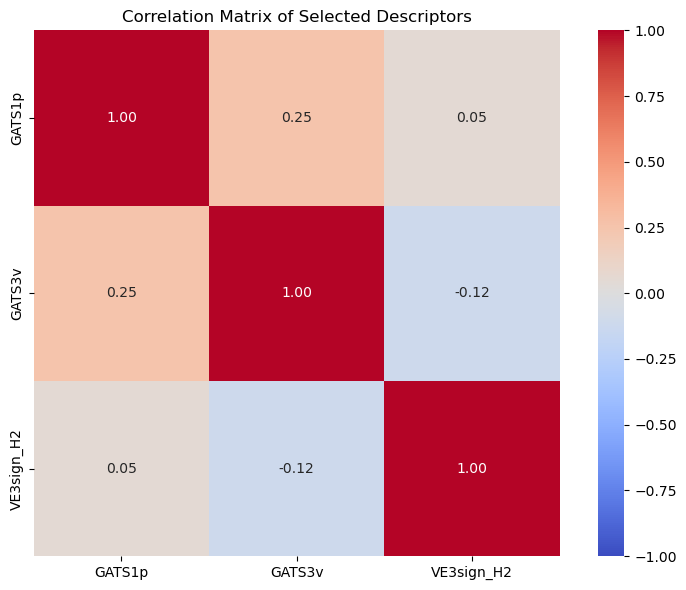


Y-randomization: 500 permutations on features ['GATS1p', 'GATS3v', 'VE3sign_H2']
Original model (CV): F1 = 0.5517 | BA = 0.7571 | ROC-AUC = 0.8545
Randomized (avg):    F1 = 0.2299 | BA = 0.5001 | ROC-AUC = 0.4969
Randomized (max):    F1 = 0.5000 | BA = 0.7641 | ROC-AUC = 0.7895
Permutations reaching the original ROC-AUC: 0.000

Model  Average F1  Average Balanced Accuracy  Average ROC-AUC
 H301      0.2299                     0.5001           0.4969


In [24]:
#H301
import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from collections import Counter
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.feature_selection import VarianceThreshold
from sklearn.metrics import (
    matthews_corrcoef,
    f1_score,
    balanced_accuracy_score,
    cohen_kappa_score,
    roc_auc_score
)


TEST_SIZE = 0.25
VAR_THRESHOLD = 0.01
CORR_THRESHOLD = 0.95
N_FEATURES = 3
N_OUTER = 3
N_INNER = 3
AD_K = 3


DATA_FILE = "H301.xlsx"
new_solvent_path = "Smiles_desc_distinct_cleaned.xlsx"


def fast_mcc(y_true, y_pred):
    tp = np.sum((y_true == 1) & (y_pred == 1))
    tn = np.sum((y_true == 0) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    denom = np.sqrt(float((tp + fp) * (tp + fn) * (tn + fp) * (tn + fn)))
    return 0.0 if denom == 0 else (tp * tn - fp * fn) / denom


def all_metrics(y_true, y_pred, y_score):
    return {
        "Balanced Accuracy": balanced_accuracy_score(y_true, y_pred),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "MCC": matthews_corrcoef(y_true, y_pred),
        "Cohen's Kappa": cohen_kappa_score(y_true, y_pred),
        "ROC-AUC": roc_auc_score(y_true, y_score) if len(np.unique(y_true)) == 2 else np.nan,
    }


def make_model():
    return SVC(kernel="rbf", C=1.0, class_weight="balanced", random_state=44)


full_df = pd.read_excel(DATA_FILE)
X = full_df.iloc[:, 1:-1]
y = full_df.iloc[:, -1]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=44
)
X_train = X_train.reset_index(drop=True)
X_test = X_test.reset_index(drop=True)
y_train = y_train.reset_index(drop=True)
y_test = y_test.reset_index(drop=True)


var_selector = VarianceThreshold(threshold=VAR_THRESHOLD)
X_train_var = var_selector.fit_transform(X_train)
X_test_var = var_selector.transform(X_test)

retained_features = X_train.columns[var_selector.get_support()]
X_train_var = pd.DataFrame(X_train_var, columns=retained_features)
X_test_var = pd.DataFrame(X_test_var, columns=retained_features)

corr_matrix = X_train_var.corr().abs()
upper_tri = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
to_drop = [col for col in upper_tri.columns if any(upper_tri[col] > CORR_THRESHOLD)]

X_train_corr = X_train_var.drop(columns=to_drop)
X_test_corr = X_test_var.drop(columns=to_drop)

scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train_corr), columns=X_train_corr.columns)
X_test_scaled = pd.DataFrame(scaler.transform(X_test_corr), columns=X_test_corr.columns)


outer_cv = StratifiedKFold(n_splits=N_OUTER, shuffle=True, random_state=44)

cv_mcc, cv_auc = [], []
fold_selected_features = []

for fold, (train_idx, val_idx) in enumerate(outer_cv.split(X_train_scaled, y_train), 1):
    X_outer_train = X_train_scaled.iloc[train_idx].reset_index(drop=True)
    X_outer_val = X_train_scaled.iloc[val_idx].reset_index(drop=True)
    y_outer_train = y_train.iloc[train_idx].reset_index(drop=True)
    y_outer_val = y_train.iloc[val_idx].reset_index(drop=True)

    inner_cv = StratifiedKFold(n_splits=N_INNER, shuffle=True, random_state=44)
    col_names = list(X_outer_train.columns)
    Xv = X_outer_train.to_numpy(dtype=float)
    yv = y_outer_train.to_numpy()
    inner_folds = list(inner_cv.split(Xv, yv))

    selected_idx = []
    remaining_idx = list(range(len(col_names)))

    for step in range(N_FEATURES):
        best_score = -np.inf
        best_j = None

        for j in remaining_idx:
            cols = selected_idx + [j]
            inner_scores = []
            for in_tr, in_val in inner_folds:
                svm = make_model()
                svm.fit(Xv[np.ix_(in_tr, cols)], yv[in_tr])
                y_p = svm.predict(Xv[np.ix_(in_val, cols)])
                inner_scores.append(fast_mcc(yv[in_val], y_p))

            mean_mcc = np.mean(inner_scores)
            if mean_mcc > best_score:
                best_score = mean_mcc
                best_j = j

        selected_idx.append(best_j)
        remaining_idx.remove(best_j)

    selected_features = [col_names[j] for j in selected_idx]

    fold_selected_features.append(selected_features)

    model = make_model()
    model.fit(X_outer_train[selected_features], y_outer_train)

    y_val_pred = model.predict(X_outer_val[selected_features])
    y_val_scores = model.decision_function(X_outer_val[selected_features])

    cv_mcc.append(matthews_corrcoef(y_outer_val, y_val_pred))
    cv_auc.append(roc_auc_score(y_outer_val, y_val_scores))


feature_counts = Counter(f for fold_feats in fold_selected_features for f in fold_feats)
final_selected_features = [f for f, _ in feature_counts.most_common(N_FEATURES)]

X_train_final = X_train_scaled[final_selected_features]
X_test_final = X_test_scaled[final_selected_features]

final_model = make_model()
final_model.fit(X_train_final, y_train)

y_train_pred = final_model.predict(X_train_final)
y_test_pred = final_model.predict(X_test_final)
y_train_scores = final_model.decision_function(X_train_final)
y_test_scores = final_model.decision_function(X_test_final)

train_m = all_metrics(y_train, y_train_pred, y_train_scores)
test_m = all_metrics(y_test, y_test_pred, y_test_scores)
metric_names = list(train_m)

metrics = pd.DataFrame(
    [[len(y_train)] + [round(v, 4) for v in train_m.values()]
     + [len(y_test)] + [round(v, 4) for v in test_m.values()]],
    columns=["N_train"] + metric_names + ["N_test"] + metric_names,
)

print("Final descriptors:", final_selected_features)
print()
print(metrics.to_string(index=False))


scaler_cols = list(scaler.feature_names_in_)
feat_idx = [scaler_cols.index(f) for f in final_selected_features]
final_mean_ = scaler.mean_[feat_idx]
final_scale_ = scaler.scale_[feat_idx]


def scale_final(X_raw):
    return (np.asarray(X_raw, dtype=float) - final_mean_) / final_scale_


train_centroid = X_train_final.mean(axis=0).to_numpy()
train_distances = np.linalg.norm(X_train_final.to_numpy() - train_centroid, axis=1)
AD_THRESHOLD = train_distances.mean() + AD_K * train_distances.std()


def ad_distance(X_scaled):
    return np.linalg.norm(np.asarray(X_scaled, dtype=float) - train_centroid, axis=1)


test_distances = ad_distance(X_test_final)

new_df = pd.read_excel(new_solvent_path)
missing = [f for f in final_selected_features if f not in new_df.columns]
if missing:
    raise ValueError(f"Descriptors missing from new solvent file: {missing}")

new_names = new_df.iloc[:, 0]
X_new_raw = new_df[final_selected_features].apply(pd.to_numeric, errors="coerce")
valid = X_new_raw.notna().all(axis=1).to_numpy()

new_pred = np.full(len(X_new_raw), np.nan)
new_score = np.full(len(X_new_raw), np.nan)
new_distances = np.full(len(X_new_raw), np.nan)

if valid.any():
    X_new_scaled = pd.DataFrame(scale_final(X_new_raw.loc[valid, final_selected_features]),
                                columns=final_selected_features)
    new_pred[valid] = final_model.predict(X_new_scaled)
    new_score[valid] = final_model.decision_function(X_new_scaled)
    new_distances[valid] = ad_distance(X_new_scaled)

train_in_ad = train_distances <= AD_THRESHOLD
test_in_ad = test_distances <= AD_THRESHOLD
new_in_ad = valid & (np.nan_to_num(new_distances, nan=np.inf) <= AD_THRESHOLD)

ad_summary = pd.DataFrame({
    "Set": ["Train", "Test", "New solvents"],
    "Inside AD": [int(train_in_ad.sum()), int(test_in_ad.sum()), int(new_in_ad.sum())],
    "Total": [len(train_distances), len(test_distances), int(valid.sum())],
})
ad_summary["Inside AD (%)"] = (100 * ad_summary["Inside AD"] / ad_summary["Total"]).round(1)

print(f"\nApplicability domain (distance threshold = {AD_THRESHOLD:.4f}, mean + {AD_K}·SD)")
print(ad_summary.to_string(index=False))
if (~valid).any():
    print(f"{int((~valid).sum())} new solvents skipped (missing descriptor values)")

new_predictions = pd.DataFrame({
    "Solvent_Name": new_names.values,
    "Predicted_Class": pd.Series(new_pred).astype("Int64").values,
    "SVM_Decision_Score": new_score,
    "Distance": new_distances,
    "AD_Status": np.where(~valid, "Not predicted",
                          np.where(new_in_ad, "Inside AD", "Outside AD")),
})


plt.figure(figsize=(8, 6))
sns.heatmap(X_train_final.corr(), annot=True, cmap="coolwarm", fmt=".2f",
            vmin=-1, vmax=1, square=True)
plt.title("Correlation Matrix of Selected Descriptors")
plt.tight_layout()
plt.show()

ENDPOINT_NAME = "H301"
N_PERMUTATIONS = 500


def cv_metrics(X_mat, y_vec, seed):
    cv = StratifiedKFold(n_splits=N_OUTER, shuffle=True, random_state=seed)
    pred = np.empty(len(y_vec))
    score = np.empty(len(y_vec))
    for tr, va in cv.split(X_mat, y_vec):
        m = make_model().fit(X_mat.iloc[tr], y_vec[tr])
        pred[va] = m.predict(X_mat.iloc[va])
        score[va] = m.decision_function(X_mat.iloc[va])
    return (f1_score(y_vec, pred, zero_division=0),
            balanced_accuracy_score(y_vec, pred),
            roc_auc_score(y_vec, score))


y_tr_np = y_train.to_numpy()
F1_orig, BA_orig, AUC_orig = cv_metrics(X_train_final, y_tr_np, 44)

rng = np.random.default_rng(2024)
rows = [cv_metrics(X_train_final, rng.permutation(y_tr_np), 44) for _ in range(N_PERMUTATIONS)]
yr = pd.DataFrame(rows, columns=["F1", "Balanced Accuracy", "ROC-AUC"])

print(f"\nY-randomization: {N_PERMUTATIONS} permutations on features {final_selected_features}")
print(f"Original model (CV): F1 = {F1_orig:.4f} | BA = {BA_orig:.4f} | ROC-AUC = {AUC_orig:.4f}")
print(f"Randomized (avg):    F1 = {yr['F1'].mean():.4f} | BA = {yr['Balanced Accuracy'].mean():.4f} | ROC-AUC = {yr['ROC-AUC'].mean():.4f}")
print(f"Randomized (max):    F1 = {yr['F1'].max():.4f} | BA = {yr['Balanced Accuracy'].max():.4f} | ROC-AUC = {yr['ROC-AUC'].max():.4f}")
print(f"Permutations reaching the original ROC-AUC: {(yr['ROC-AUC'] >= AUC_orig).mean():.3f}")

summary = pd.DataFrame([{
    "Model": ENDPOINT_NAME,
    "Average F1": round(yr["F1"].mean(), 4),
    "Average Balanced Accuracy": round(yr["Balanced Accuracy"].mean(), 4),
    "Average ROC-AUC": round(yr["ROC-AUC"].mean(), 4),
}])
print("\n" + summary.to_string(index=False))

Final descriptors: ['GATS1v', 'DECC', '|S|n|||3|||LOGP|C-C-D']

 N_train  Balanced Accuracy     F1    MCC  Cohen's Kappa  ROC-AUC  N_test  Balanced Accuracy   F1  MCC  Cohen's Kappa  ROC-AUC
      70             0.9417 0.7407 0.7208         0.6839   0.9767      24               0.85 0.75  0.7            0.7   0.9375

Applicability domain (distance threshold = 4.4336, mean + 3·SD)
         Set  Inside AD  Total  Inside AD (%)
       Train         69     70           98.6
        Test         23     24           95.8
New solvents         96    105           91.4

New solvents: predicted class 1 = 16, predicted class 0 = 89


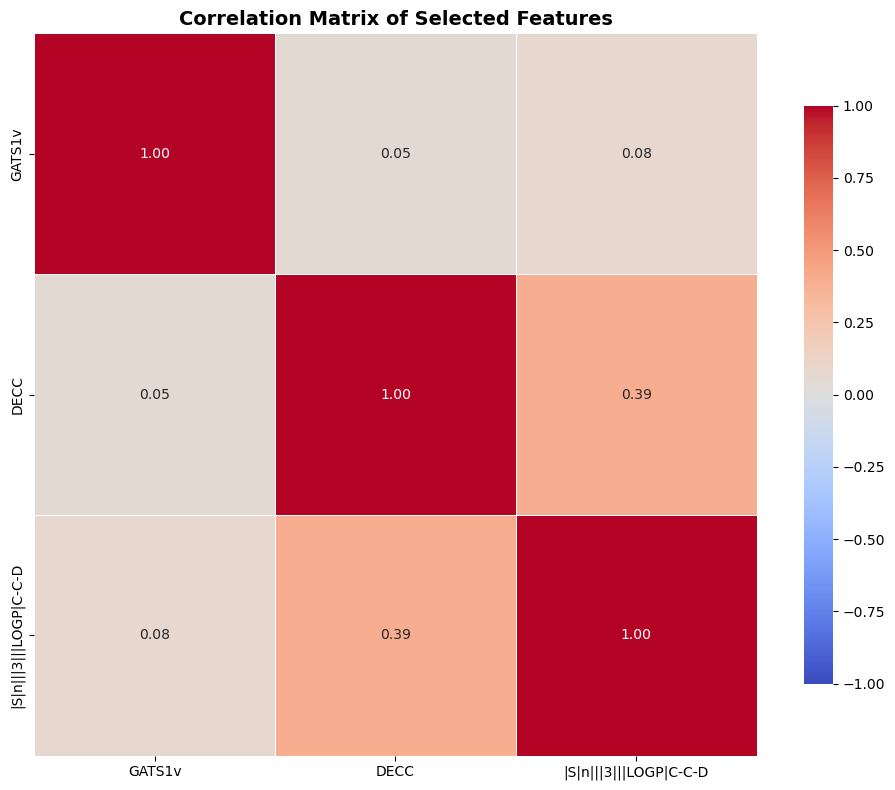


Y-randomization: 500 permutations on features ['GATS1v', 'DECC', '|S|n|||3|||LOGP|C-C-D']
Original model (CV): F1 = 0.5833 | BA = 0.7917 | ROC-AUC = 0.9233
Randomized (avg):    F1 = 0.1974 | BA = 0.4966 | ROC-AUC = 0.4896
Randomized (max):    F1 = 0.5333 | BA = 0.8000 | ROC-AUC = 0.8233
Permutations reaching the original ROC-AUC: 0.000

Model  Average F1  Average Balanced Accuracy  Average ROC-AUC
 HXXX      0.1974                     0.4966           0.4896


In [25]:
#H311

import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.feature_selection import VarianceThreshold
from sklearn.metrics import (
    matthews_corrcoef,
    f1_score,
    balanced_accuracy_score,
    cohen_kappa_score,
    roc_auc_score
)

TEST_SIZE = 0.25
VAR_THRESHOLD = 0.01
CORR_THRESHOLD = 0.90
N_FEATURES = 3
N_OUTER = 3
N_INNER = 3
FINAL_SELECTION = "vote"
AD_K = 3

DATA_FILE = "H311.xlsx"
new_solvent_path = "Smiles_desc_distinct_cleaned.xlsx"


def filter_features(X):
    vt = VarianceThreshold(threshold=VAR_THRESHOLD).fit(X)
    cols = X.columns[vt.get_support()]
    corr = X[cols].corr().abs()
    upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
    to_drop = {c for c in upper.columns if any(upper[c] > CORR_THRESHOLD)}
    return [c for c in cols if c not in to_drop]


def fast_mcc(y_true, y_pred):
    tp = np.sum((y_true == 1) & (y_pred == 1))
    tn = np.sum((y_true == 0) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    denom = np.sqrt(float((tp + fp) * (tp + fn) * (tn + fp) * (tn + fn)))
    return 0.0 if denom == 0 else (tp * tn - fp * fn) / denom


def forward_selection(X, y, cv):
    names = list(X.columns)
    Xv, yv = X.to_numpy(dtype=float), y.to_numpy()
    folds = []
    for tr, va in cv.split(Xv, yv):
        sc = StandardScaler().fit(Xv[tr])
        folds.append((sc.transform(Xv[tr]), yv[tr], sc.transform(Xv[va]), yv[va]))

    selected, remaining = [], list(range(len(names)))
    for step in range(N_FEATURES):
        best_score, best_j = -np.inf, None
        for j in remaining:
            cols = selected + [j]
            scores = []
            for X_tr, y_tr, X_va, y_va in folds:
                m = make_model().fit(X_tr[:, cols], y_tr)
                scores.append(fast_mcc(y_va, m.predict(X_va[:, cols])))
            s = np.mean(scores)
            if s > best_score:
                best_score, best_j = s, j
        selected.append(best_j)
        remaining.remove(best_j)
    return [names[j] for j in selected]


def all_metrics(y_true, y_pred, y_score):
    return {
        "Balanced Accuracy": balanced_accuracy_score(y_true, y_pred),
        "F1": f1_score(y_true, y_pred),
        "MCC": matthews_corrcoef(y_true, y_pred),
        "Cohen's Kappa": cohen_kappa_score(y_true, y_pred),
        "ROC-AUC": roc_auc_score(y_true, y_score),
    }

def make_model():
    return SVC(kernel="rbf", C=1.0, class_weight="balanced", random_state=4)

full_df = pd.read_excel(DATA_FILE)
X = full_df.iloc[:, 1:-1]
y = full_df.iloc[:, -1]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=4
)
X_train = X_train.reset_index(drop=True)
X_test = X_test.reset_index(drop=True)
y_train = y_train.reset_index(drop=True)
y_test = y_test.reset_index(drop=True)


outer_cv = StratifiedKFold(n_splits=N_OUTER, shuffle=True, random_state=4)
inner_cv = StratifiedKFold(n_splits=N_INNER, shuffle=True, random_state=4)

fold_results = []
fold_features = []

for fold, (tr_idx, va_idx) in enumerate(outer_cv.split(X_train, y_train), 1):
    X_tr = X_train.iloc[tr_idx].reset_index(drop=True)
    X_va = X_train.iloc[va_idx].reset_index(drop=True)
    y_tr = y_train.iloc[tr_idx].reset_index(drop=True)
    y_va = y_train.iloc[va_idx].reset_index(drop=True)

    kept = filter_features(X_tr)
    feats = forward_selection(X_tr[kept], y_tr, inner_cv)

    fold_scaler = StandardScaler().fit(X_tr[feats])
    model = make_model().fit(fold_scaler.transform(X_tr[feats]), y_tr)

    X_va_s = fold_scaler.transform(X_va[feats])
    m = all_metrics(y_va, model.predict(X_va_s), model.decision_function(X_va_s))
    fold_results.append(m)
    fold_features.append(feats)

nested_df = pd.DataFrame(fold_results)
feature_freq = pd.Series([f for fs in fold_features for f in fs]).value_counts()


if FINAL_SELECTION == "vote":
    final_selected_features = list(feature_freq.index[:N_FEATURES])
else:
    kept = filter_features(X_train)
    final_selected_features = forward_selection(X_train[kept], y_train, inner_cv)

X_train_corr = X_train[final_selected_features]
scaler = StandardScaler().fit(X_train_corr)
X_train_final = pd.DataFrame(scaler.transform(X_train_corr), columns=final_selected_features)
X_test_final = pd.DataFrame(scaler.transform(X_test[final_selected_features]), columns=final_selected_features)

final_model = make_model().fit(X_train_final, y_train)

y_train_pred = final_model.predict(X_train_final)
y_test_pred = final_model.predict(X_test_final)
y_train_scores = final_model.decision_function(X_train_final)
y_test_scores = final_model.decision_function(X_test_final)

train_m = all_metrics(y_train, y_train_pred, y_train_scores)
test_m = all_metrics(y_test, y_test_pred, y_test_scores)
metric_names = list(train_m)

metrics = pd.DataFrame(
    [[len(y_train)] + [round(v, 4) for v in train_m.values()]
     + [len(y_test)] + [round(v, 4) for v in test_m.values()]],
    columns=["N_train"] + metric_names + ["N_test"] + metric_names,
)

print("Final descriptors:", final_selected_features)
print()
print(metrics.to_string(index=False))


feats = list(final_selected_features)
ad_scaler = StandardScaler().fit(X_train[feats])

X_tr_s = X_train_final[feats].to_numpy(dtype=float)
train_centroid = X_tr_s.mean(axis=0)
train_distances = np.linalg.norm(X_tr_s - train_centroid, axis=1)
AD_THRESHOLD = train_distances.mean() + AD_K * train_distances.std()


def ad_distance(X_scaled):
    return np.linalg.norm(np.asarray(X_scaled, dtype=float) - train_centroid, axis=1)


test_distances = ad_distance(X_test_final[feats])

new_solvents_df = pd.read_excel(new_solvent_path)
missing = [f for f in feats if f not in new_solvents_df.columns]
if missing:
    raise KeyError(f"New-solvent file is missing required features: {missing}")

new_names = new_solvents_df.iloc[:, 0]
X_new_raw = new_solvents_df[feats].apply(pd.to_numeric, errors="coerce")
valid = X_new_raw.notna().all(axis=1).to_numpy()

new_pred = np.full(len(X_new_raw), np.nan)
new_score = np.full(len(X_new_raw), np.nan)
new_distances = np.full(len(X_new_raw), np.nan)
if valid.any():
    X_new_scaled = pd.DataFrame(ad_scaler.transform(X_new_raw.loc[valid, feats]), columns=feats)
    new_pred[valid] = final_model.predict(X_new_scaled)
    new_score[valid] = final_model.decision_function(X_new_scaled)
    new_distances[valid] = ad_distance(X_new_scaled)

train_in_ad = train_distances <= AD_THRESHOLD
test_in_ad = test_distances <= AD_THRESHOLD
new_in_ad = valid & (np.nan_to_num(new_distances, nan=np.inf) <= AD_THRESHOLD)

ad_summary = pd.DataFrame({
    "Set": ["Train", "Test", "New solvents"],
    "Inside AD": [int(train_in_ad.sum()), int(test_in_ad.sum()), int(new_in_ad.sum())],
    "Total": [len(train_distances), len(test_distances), int(valid.sum())],
})
ad_summary["Inside AD (%)"] = (100 * ad_summary["Inside AD"] / ad_summary["Total"]).round(1)

print(f"\nApplicability domain (distance threshold = {AD_THRESHOLD:.4f}, mean + {AD_K}·SD)")
print(ad_summary.to_string(index=False))
if (~valid).any():
    print(f"{int((~valid).sum())} new solvents skipped (missing descriptor values)")

new_predictions = pd.DataFrame({
    "Solvent_Name": new_names.values,
    "Predicted_Class": pd.array(new_pred, dtype="Int64"),
    "SVM_Decision_Score": new_score,
    "Distance": new_distances,
    "AD_Status": np.where(~valid, "Not predicted",
                          np.where(new_in_ad, "Inside AD", "Outside AD")),
})

print(f"\nNew solvents: predicted class 1 = {int(np.nansum(new_pred == 1))}, "
      f"predicted class 0 = {int(np.nansum(new_pred == 0))}")


selected_corr_matrix = X_train[final_selected_features].corr()
plt.figure(figsize=(10, 8))
sns.heatmap(selected_corr_matrix, annot=True, cmap="coolwarm", fmt=".2f",
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.8},
            vmin=-1, vmax=1)
plt.title("Correlation Matrix of Selected Features", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

ENDPOINT_NAME = "H311"
N_PERMUTATIONS = 500


def cv_metrics(X_mat, y_vec, seed):
    cv = StratifiedKFold(n_splits=N_OUTER, shuffle=True, random_state=seed)
    pred = np.empty(len(y_vec))
    score = np.empty(len(y_vec))
    for tr, va in cv.split(X_mat, y_vec):
        m = make_model().fit(X_mat.iloc[tr], y_vec[tr])
        pred[va] = m.predict(X_mat.iloc[va])
        score[va] = m.decision_function(X_mat.iloc[va])
    return (f1_score(y_vec, pred, zero_division=0),
            balanced_accuracy_score(y_vec, pred),
            roc_auc_score(y_vec, score))


y_tr_np = y_train.to_numpy()
F1_orig, BA_orig, AUC_orig = cv_metrics(X_train_final, y_tr_np, 4)

rng = np.random.default_rng(2024)
rows = [cv_metrics(X_train_final, rng.permutation(y_tr_np), 4) for _ in range(N_PERMUTATIONS)]
yr = pd.DataFrame(rows, columns=["F1", "Balanced Accuracy", "ROC-AUC"])

print(f"\nY-randomization: {N_PERMUTATIONS} permutations on features {final_selected_features}")
print(f"Original model (CV): F1 = {F1_orig:.4f} | BA = {BA_orig:.4f} | ROC-AUC = {AUC_orig:.4f}")
print(f"Randomized (avg):    F1 = {yr['F1'].mean():.4f} | BA = {yr['Balanced Accuracy'].mean():.4f} | ROC-AUC = {yr['ROC-AUC'].mean():.4f}")
print(f"Randomized (max):    F1 = {yr['F1'].max():.4f} | BA = {yr['Balanced Accuracy'].max():.4f} | ROC-AUC = {yr['ROC-AUC'].max():.4f}")
print(f"Permutations reaching the original ROC-AUC: {(yr['ROC-AUC'] >= AUC_orig).mean():.3f}")

summary = pd.DataFrame([{
    "Model": ENDPOINT_NAME,
    "Average F1": round(yr["F1"].mean(), 4),
    "Average Balanced Accuracy": round(yr["Balanced Accuracy"].mean(), 4),
    "Average ROC-AUC": round(yr["ROC-AUC"].mean(), 4),
}])
print("\n" + summary.to_string(index=False))

Final descriptors: ['nN', 'nR05', '|S|n|||4|||REFRACTIVITY|B.B-C=C']

 N_train  Balanced Accuracy     F1    MCC  Cohen's Kappa  ROC-AUC  N_test  Balanced Accuracy   F1    MCC  Cohen's Kappa  ROC-AUC
      60             0.8693 0.7778 0.7386         0.7386   0.8802      27             0.8533 0.75 0.7065         0.7065   0.8533

Applicability domain (distance threshold = 4.8783, mean + 3·SD)
         Set  Inside AD  Total  Inside AD (%)
       Train         59     60           98.3
        Test         26     27           96.3
New solvents        100    105           95.2

New solvents: predicted class 1 = 7, predicted class 0 = 98


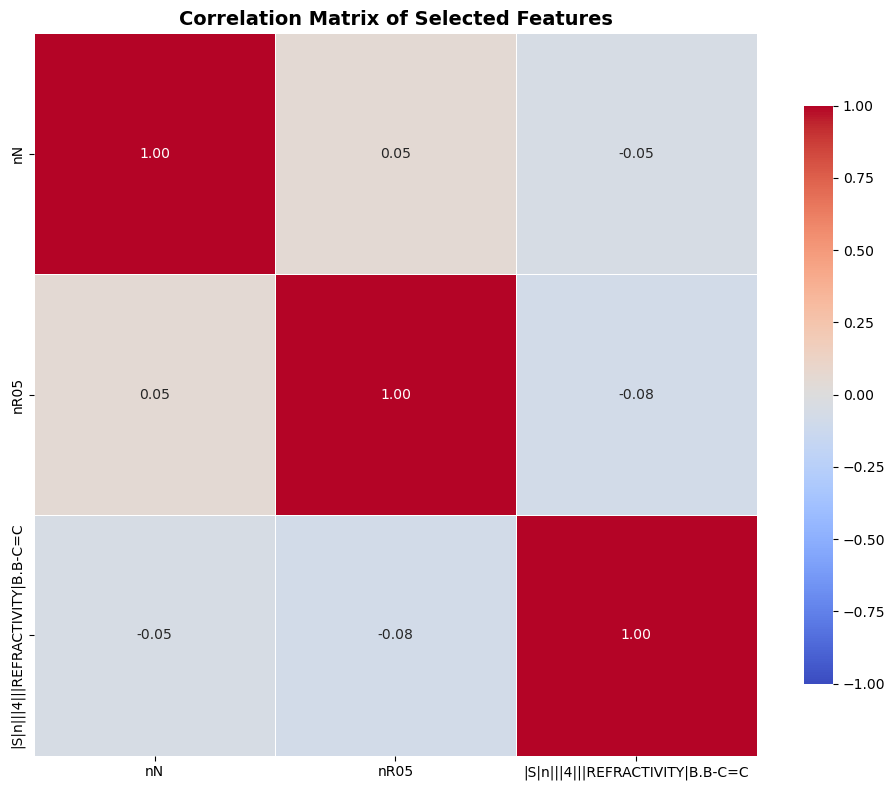


Y-randomization: 500 permutations on features ['nN', 'nR05', '|S|n|||4|||REFRACTIVITY|B.B-C=C']
Original model (CV): F1 = 0.5882 | BA = 0.7484 | ROC-AUC = 0.8627
Randomized (avg):    F1 = 0.1947 | BA = 0.4954 | ROC-AUC = 0.4898
Randomized (max):    F1 = 0.5714 | BA = 0.7712 | ROC-AUC = 0.7614
Permutations reaching the original ROC-AUC: 0.000

Model  Average F1  Average Balanced Accuracy  Average ROC-AUC
 H312      0.1947                     0.4954           0.4898


In [26]:
#H312

import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.feature_selection import VarianceThreshold
from sklearn.metrics import (
    matthews_corrcoef,
    f1_score,
    balanced_accuracy_score,
    cohen_kappa_score,
    roc_auc_score
)



TEST_SIZE = 0.3
VAR_THRESHOLD = 0.01
CORR_THRESHOLD = 0.90
N_FEATURES = 3
N_OUTER = 3
N_INNER = 3
FINAL_SELECTION = "vote"
AD_K = 3

DATA_FILE = "H312.xlsx"
new_solvent_path = "Smiles_desc_distinct_cleaned.xlsx"


def filter_features(X):
    vt = VarianceThreshold(threshold=VAR_THRESHOLD).fit(X)
    cols = X.columns[vt.get_support()]
    corr = X[cols].corr().abs()
    upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
    to_drop = {c for c in upper.columns if any(upper[c] > CORR_THRESHOLD)}
    return [c for c in cols if c not in to_drop]


def fast_mcc(y_true, y_pred):
    tp = np.sum((y_true == 1) & (y_pred == 1))
    tn = np.sum((y_true == 0) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    denom = np.sqrt(float((tp + fp) * (tp + fn) * (tn + fp) * (tn + fn)))
    return 0.0 if denom == 0 else (tp * tn - fp * fn) / denom


def forward_selection(X, y, cv):
    names = list(X.columns)
    Xv, yv = X.to_numpy(dtype=float), y.to_numpy()
    folds = []
    for tr, va in cv.split(Xv, yv):
        sc = StandardScaler().fit(Xv[tr])
        folds.append((sc.transform(Xv[tr]), yv[tr], sc.transform(Xv[va]), yv[va]))

    selected, remaining = [], list(range(len(names)))
    for step in range(N_FEATURES):
        best_score, best_j = -np.inf, None
        for j in remaining:
            cols = selected + [j]
            scores = []
            for X_tr, y_tr, X_va, y_va in folds:
                m = make_model().fit(X_tr[:, cols], y_tr)
                scores.append(fast_mcc(y_va, m.predict(X_va[:, cols])))
            s = np.mean(scores)
            if s > best_score:
                best_score, best_j = s, j
        selected.append(best_j)
        remaining.remove(best_j)
    return [names[j] for j in selected]


def all_metrics(y_true, y_pred, y_score):
    return {
        "Balanced Accuracy": balanced_accuracy_score(y_true, y_pred),
        "F1": f1_score(y_true, y_pred),
        "MCC": matthews_corrcoef(y_true, y_pred),
        "Cohen's Kappa": cohen_kappa_score(y_true, y_pred),
        "ROC-AUC": roc_auc_score(y_true, y_score),
    }

def make_model():
    return SVC(kernel="rbf", C=1.0, class_weight="balanced", random_state=11)


full_df = pd.read_excel(DATA_FILE)
X = full_df.iloc[:, 1:-1]
y = full_df.iloc[:, -1]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=11
)
X_train = X_train.reset_index(drop=True)
X_test = X_test.reset_index(drop=True)
y_train = y_train.reset_index(drop=True)
y_test = y_test.reset_index(drop=True)


outer_cv = StratifiedKFold(n_splits=N_OUTER, shuffle=True, random_state=11)
inner_cv = StratifiedKFold(n_splits=N_INNER, shuffle=True, random_state=11)

fold_results = []
fold_features = []

for fold, (tr_idx, va_idx) in enumerate(outer_cv.split(X_train, y_train), 1):
    X_tr = X_train.iloc[tr_idx].reset_index(drop=True)
    X_va = X_train.iloc[va_idx].reset_index(drop=True)
    y_tr = y_train.iloc[tr_idx].reset_index(drop=True)
    y_va = y_train.iloc[va_idx].reset_index(drop=True)

    kept = filter_features(X_tr)
    feats = forward_selection(X_tr[kept], y_tr, inner_cv)

    fold_scaler = StandardScaler().fit(X_tr[feats])
    model = make_model().fit(fold_scaler.transform(X_tr[feats]), y_tr)

    X_va_s = fold_scaler.transform(X_va[feats])
    m = all_metrics(y_va, model.predict(X_va_s), model.decision_function(X_va_s))
    fold_results.append(m)
    fold_features.append(feats)

nested_df = pd.DataFrame(fold_results)
feature_freq = pd.Series([f for fs in fold_features for f in fs]).value_counts()


if FINAL_SELECTION == "vote":
    final_selected_features = list(feature_freq.index[:N_FEATURES])
else:
    kept = filter_features(X_train)
    final_selected_features = forward_selection(X_train[kept], y_train, inner_cv)

X_train_corr = X_train[final_selected_features]
scaler = StandardScaler().fit(X_train_corr)
X_train_final = pd.DataFrame(scaler.transform(X_train_corr), columns=final_selected_features)
X_test_final = pd.DataFrame(scaler.transform(X_test[final_selected_features]), columns=final_selected_features)

final_model = make_model().fit(X_train_final, y_train)

y_train_pred = final_model.predict(X_train_final)
y_test_pred = final_model.predict(X_test_final)
y_train_scores = final_model.decision_function(X_train_final)
y_test_scores = final_model.decision_function(X_test_final)

train_m = all_metrics(y_train, y_train_pred, y_train_scores)
test_m = all_metrics(y_test, y_test_pred, y_test_scores)
metric_names = list(train_m)

metrics = pd.DataFrame(
    [[len(y_train)] + [round(v, 4) for v in train_m.values()]
     + [len(y_test)] + [round(v, 4) for v in test_m.values()]],
    columns=["N_train"] + metric_names + ["N_test"] + metric_names,
)

print("Final descriptors:", final_selected_features)
print()
print(metrics.to_string(index=False))


feats = list(final_selected_features)
ad_scaler = StandardScaler().fit(X_train[feats])

X_tr_s = X_train_final[feats].to_numpy(dtype=float)
train_centroid = X_tr_s.mean(axis=0)
train_distances = np.linalg.norm(X_tr_s - train_centroid, axis=1)
AD_THRESHOLD = train_distances.mean() + AD_K * train_distances.std()


def ad_distance(X_scaled):
    return np.linalg.norm(np.asarray(X_scaled, dtype=float) - train_centroid, axis=1)


test_distances = ad_distance(X_test_final[feats])

new_solvents_df = pd.read_excel(new_solvent_path)
missing = [f for f in feats if f not in new_solvents_df.columns]
if missing:
    raise KeyError(f"New-solvent file is missing required features: {missing}")

new_names = new_solvents_df.iloc[:, 0]
X_new_raw = new_solvents_df[feats].apply(pd.to_numeric, errors="coerce")
valid = X_new_raw.notna().all(axis=1).to_numpy()

new_pred = np.full(len(X_new_raw), np.nan)
new_score = np.full(len(X_new_raw), np.nan)
new_distances = np.full(len(X_new_raw), np.nan)
if valid.any():
    X_new_scaled = pd.DataFrame(ad_scaler.transform(X_new_raw.loc[valid, feats]), columns=feats)
    new_pred[valid] = final_model.predict(X_new_scaled)
    new_score[valid] = final_model.decision_function(X_new_scaled)
    new_distances[valid] = ad_distance(X_new_scaled)

train_in_ad = train_distances <= AD_THRESHOLD
test_in_ad = test_distances <= AD_THRESHOLD
new_in_ad = valid & (np.nan_to_num(new_distances, nan=np.inf) <= AD_THRESHOLD)

ad_summary = pd.DataFrame({
    "Set": ["Train", "Test", "New solvents"],
    "Inside AD": [int(train_in_ad.sum()), int(test_in_ad.sum()), int(new_in_ad.sum())],
    "Total": [len(train_distances), len(test_distances), int(valid.sum())],
})
ad_summary["Inside AD (%)"] = (100 * ad_summary["Inside AD"] / ad_summary["Total"]).round(1)

print(f"\nApplicability domain (distance threshold = {AD_THRESHOLD:.4f}, mean + {AD_K}·SD)")
print(ad_summary.to_string(index=False))
if (~valid).any():
    print(f"{int((~valid).sum())} new solvents skipped (missing descriptor values)")

new_predictions = pd.DataFrame({
    "Solvent_Name": new_names.values,
    "Predicted_Class": pd.array(new_pred, dtype="Int64"),
    "SVM_Decision_Score": new_score,
    "Distance": new_distances,
    "AD_Status": np.where(~valid, "Not predicted",
                          np.where(new_in_ad, "Inside AD", "Outside AD")),
})

print(f"\nNew solvents: predicted class 1 = {int(np.nansum(new_pred == 1))}, "
      f"predicted class 0 = {int(np.nansum(new_pred == 0))}")


selected_corr_matrix = X_train[final_selected_features].corr()
plt.figure(figsize=(10, 8))
sns.heatmap(selected_corr_matrix, annot=True, cmap="coolwarm", fmt=".2f",
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.8},
            vmin=-1, vmax=1)
plt.title("Correlation Matrix of Selected Features", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

ENDPOINT_NAME = "H312"
N_PERMUTATIONS = 500


def cv_metrics(X_mat, y_vec, seed):
    cv = StratifiedKFold(n_splits=N_OUTER, shuffle=True, random_state=seed)
    pred = np.empty(len(y_vec))
    score = np.empty(len(y_vec))
    for tr, va in cv.split(X_mat, y_vec):
        m = make_model().fit(X_mat.iloc[tr], y_vec[tr])
        pred[va] = m.predict(X_mat.iloc[va])
        score[va] = m.decision_function(X_mat.iloc[va])
    return (f1_score(y_vec, pred, zero_division=0),
            balanced_accuracy_score(y_vec, pred),
            roc_auc_score(y_vec, score))


y_tr_np = y_train.to_numpy()
F1_orig, BA_orig, AUC_orig = cv_metrics(X_train_final, y_tr_np, 11)

rng = np.random.default_rng(2024)
rows = [cv_metrics(X_train_final, rng.permutation(y_tr_np), 11) for _ in range(N_PERMUTATIONS)]
yr = pd.DataFrame(rows, columns=["F1", "Balanced Accuracy", "ROC-AUC"])

print(f"\nY-randomization: {N_PERMUTATIONS} permutations on features {final_selected_features}")
print(f"Original model (CV): F1 = {F1_orig:.4f} | BA = {BA_orig:.4f} | ROC-AUC = {AUC_orig:.4f}")
print(f"Randomized (avg):    F1 = {yr['F1'].mean():.4f} | BA = {yr['Balanced Accuracy'].mean():.4f} | ROC-AUC = {yr['ROC-AUC'].mean():.4f}")
print(f"Randomized (max):    F1 = {yr['F1'].max():.4f} | BA = {yr['Balanced Accuracy'].max():.4f} | ROC-AUC = {yr['ROC-AUC'].max():.4f}")
print(f"Permutations reaching the original ROC-AUC: {(yr['ROC-AUC'] >= AUC_orig).mean():.3f}")

summary = pd.DataFrame([{
    "Model": ENDPOINT_NAME,
    "Average F1": round(yr["F1"].mean(), 4),
    "Average Balanced Accuracy": round(yr["Balanced Accuracy"].mean(), 4),
    "Average ROC-AUC": round(yr["ROC-AUC"].mean(), 4),
}])
print("\n" + summary.to_string(index=False))

Final descriptors: ['VE3sign_Dz(Z)', 'nO', '|S|n|||4|||HB|AD-I-I.I']

 N_train  Balanced Accuracy     F1    MCC  Cohen's Kappa  ROC-AUC  N_test  Balanced Accuracy     F1    MCC  Cohen's Kappa  ROC-AUC
      73             0.8519 0.8406 0.7006         0.6982   0.8765      25             0.8636 0.8421 0.7739         0.7492   0.8864

Applicability domain (distance threshold = 4.4845, mean + 3·SD)
         Set  Inside AD  Total  Inside AD (%)
       Train         71     73           97.3
        Test         25     25          100.0
New solvents         87    105           82.9

New solvents: predicted class 1 = 77, predicted class 0 = 28


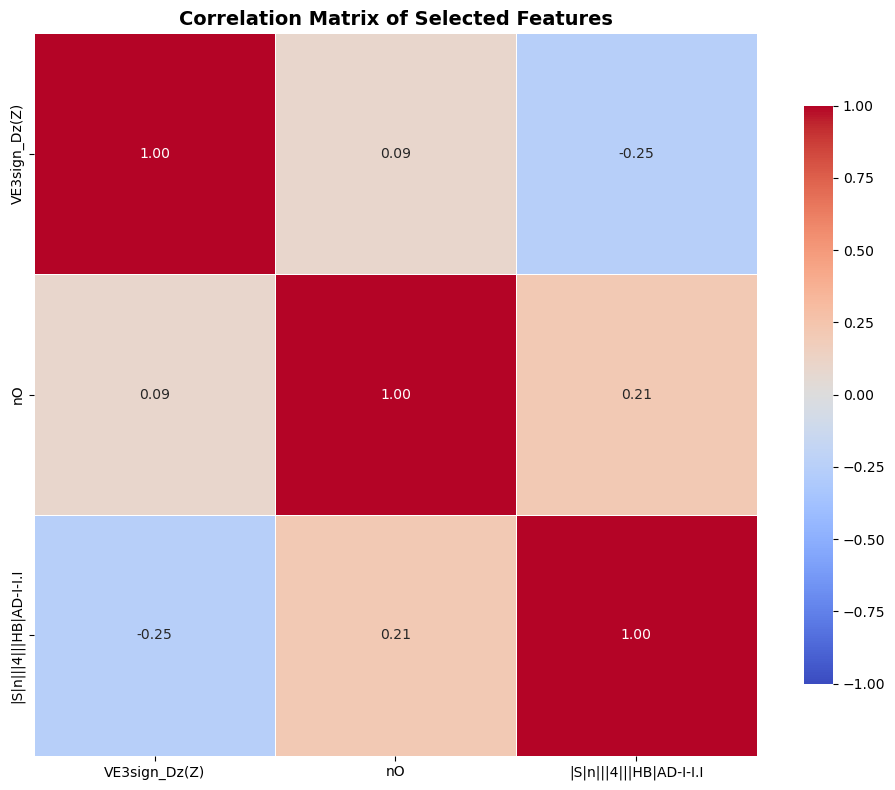


Y-randomization: 500 permutations on features ['VE3sign_Dz(Z)', 'nO', '|S|n|||4|||HB|AD-I-I.I']
Original model (CV): F1 = 0.7536 | BA = 0.7689 | ROC-AUC = 0.8106
Randomized (avg):    F1 = 0.4699 | BA = 0.5037 | ROC-AUC = 0.5026
Randomized (max):    F1 = 0.7042 | BA = 0.7163 | ROC-AUC = 0.7193
Permutations reaching the original ROC-AUC: 0.000

Model  Average F1  Average Balanced Accuracy  Average ROC-AUC
 H315      0.4699                     0.5037           0.5026


In [27]:
#H315

import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.feature_selection import VarianceThreshold
from sklearn.metrics import (
    matthews_corrcoef,
    f1_score,
    balanced_accuracy_score,
    cohen_kappa_score,
    roc_auc_score
)



TEST_SIZE = 0.25
VAR_THRESHOLD = 0.01
CORR_THRESHOLD = 0.90
N_FEATURES = 3
N_OUTER = 3
N_INNER = 3
FINAL_SELECTION = "vote"
AD_K = 3


DATA_FILE = "H315.xlsx"
new_solvent_path = "Smiles_desc_distinct_cleaned.xlsx"

def filter_features(X):
    vt = VarianceThreshold(threshold=VAR_THRESHOLD).fit(X)
    cols = X.columns[vt.get_support()]
    corr = X[cols].corr().abs()
    upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
    to_drop = {c for c in upper.columns if any(upper[c] > CORR_THRESHOLD)}
    return [c for c in cols if c not in to_drop]


def fast_mcc(y_true, y_pred):
    tp = np.sum((y_true == 1) & (y_pred == 1))
    tn = np.sum((y_true == 0) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    denom = np.sqrt(float((tp + fp) * (tp + fn) * (tn + fp) * (tn + fn)))
    return 0.0 if denom == 0 else (tp * tn - fp * fn) / denom


def forward_selection(X, y, cv):
    names = list(X.columns)
    Xv, yv = X.to_numpy(dtype=float), y.to_numpy()
    folds = []
    for tr, va in cv.split(Xv, yv):
        sc = StandardScaler().fit(Xv[tr])
        folds.append((sc.transform(Xv[tr]), yv[tr], sc.transform(Xv[va]), yv[va]))

    selected, remaining = [], list(range(len(names)))
    for step in range(N_FEATURES):
        best_score, best_j = -np.inf, None
        for j in remaining:
            cols = selected + [j]
            scores = []
            for X_tr, y_tr, X_va, y_va in folds:
                m = make_model().fit(X_tr[:, cols], y_tr)
                scores.append(fast_mcc(y_va, m.predict(X_va[:, cols])))
            s = np.mean(scores)
            if s > best_score:
                best_score, best_j = s, j
        selected.append(best_j)
        remaining.remove(best_j)
    return [names[j] for j in selected]


def all_metrics(y_true, y_pred, y_score):
    return {
        "Balanced Accuracy": balanced_accuracy_score(y_true, y_pred),
        "F1": f1_score(y_true, y_pred),
        "MCC": matthews_corrcoef(y_true, y_pred),
        "Cohen's Kappa": cohen_kappa_score(y_true, y_pred),
        "ROC-AUC": roc_auc_score(y_true, y_score),
    }


def make_model():
    return SVC(kernel="rbf", C=1.0, class_weight="balanced", random_state=18)



full_df = pd.read_excel(DATA_FILE)
X = full_df.iloc[:, 1:-1]
y = full_df.iloc[:, -1]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=18
)
X_train = X_train.reset_index(drop=True)
X_test = X_test.reset_index(drop=True)
y_train = y_train.reset_index(drop=True)
y_test = y_test.reset_index(drop=True)


outer_cv = StratifiedKFold(n_splits=N_OUTER, shuffle=True, random_state=18)
inner_cv = StratifiedKFold(n_splits=N_INNER, shuffle=True, random_state=18)

fold_results = []
fold_features = []

for fold, (tr_idx, va_idx) in enumerate(outer_cv.split(X_train, y_train), 1):
    X_tr = X_train.iloc[tr_idx].reset_index(drop=True)
    X_va = X_train.iloc[va_idx].reset_index(drop=True)
    y_tr = y_train.iloc[tr_idx].reset_index(drop=True)
    y_va = y_train.iloc[va_idx].reset_index(drop=True)

    kept = filter_features(X_tr)
    feats = forward_selection(X_tr[kept], y_tr, inner_cv)

    fold_scaler = StandardScaler().fit(X_tr[feats])
    model = make_model().fit(fold_scaler.transform(X_tr[feats]), y_tr)

    X_va_s = fold_scaler.transform(X_va[feats])
    m = all_metrics(y_va, model.predict(X_va_s), model.decision_function(X_va_s))
    fold_results.append(m)
    fold_features.append(feats)

nested_df = pd.DataFrame(fold_results)
feature_freq = pd.Series([f for fs in fold_features for f in fs]).value_counts()


if FINAL_SELECTION == "vote":
    final_selected_features = list(feature_freq.index[:N_FEATURES])
else:
    kept = filter_features(X_train)
    final_selected_features = forward_selection(X_train[kept], y_train, inner_cv)

X_train_corr = X_train[final_selected_features]
scaler = StandardScaler().fit(X_train_corr)
X_train_final = pd.DataFrame(scaler.transform(X_train_corr), columns=final_selected_features)
X_test_final = pd.DataFrame(scaler.transform(X_test[final_selected_features]), columns=final_selected_features)

final_model = make_model().fit(X_train_final, y_train)

y_train_pred = final_model.predict(X_train_final)
y_test_pred = final_model.predict(X_test_final)
y_train_scores = final_model.decision_function(X_train_final)
y_test_scores = final_model.decision_function(X_test_final)

train_m = all_metrics(y_train, y_train_pred, y_train_scores)
test_m = all_metrics(y_test, y_test_pred, y_test_scores)
metric_names = list(train_m)

metrics = pd.DataFrame(
    [[len(y_train)] + [round(v, 4) for v in train_m.values()]
     + [len(y_test)] + [round(v, 4) for v in test_m.values()]],
    columns=["N_train"] + metric_names + ["N_test"] + metric_names,
)

print("Final descriptors:", final_selected_features)
print()
print(metrics.to_string(index=False))


feats = list(final_selected_features)
ad_scaler = StandardScaler().fit(X_train[feats])

X_tr_s = X_train_final[feats].to_numpy(dtype=float)
train_centroid = X_tr_s.mean(axis=0)
train_distances = np.linalg.norm(X_tr_s - train_centroid, axis=1)
AD_THRESHOLD = train_distances.mean() + AD_K * train_distances.std()


def ad_distance(X_scaled):
    return np.linalg.norm(np.asarray(X_scaled, dtype=float) - train_centroid, axis=1)


test_distances = ad_distance(X_test_final[feats])

new_solvents_df = pd.read_excel(new_solvent_path)
missing = [f for f in feats if f not in new_solvents_df.columns]
if missing:
    raise KeyError(f"New-solvent file is missing required features: {missing}")

new_names = new_solvents_df.iloc[:, 0]
X_new_raw = new_solvents_df[feats].apply(pd.to_numeric, errors="coerce")
valid = X_new_raw.notna().all(axis=1).to_numpy()

new_pred = np.full(len(X_new_raw), np.nan)
new_score = np.full(len(X_new_raw), np.nan)
new_distances = np.full(len(X_new_raw), np.nan)
if valid.any():
    X_new_scaled = pd.DataFrame(ad_scaler.transform(X_new_raw.loc[valid, feats]), columns=feats)
    new_pred[valid] = final_model.predict(X_new_scaled)
    new_score[valid] = final_model.decision_function(X_new_scaled)
    new_distances[valid] = ad_distance(X_new_scaled)

train_in_ad = train_distances <= AD_THRESHOLD
test_in_ad = test_distances <= AD_THRESHOLD
new_in_ad = valid & (np.nan_to_num(new_distances, nan=np.inf) <= AD_THRESHOLD)

ad_summary = pd.DataFrame({
    "Set": ["Train", "Test", "New solvents"],
    "Inside AD": [int(train_in_ad.sum()), int(test_in_ad.sum()), int(new_in_ad.sum())],
    "Total": [len(train_distances), len(test_distances), int(valid.sum())],
})
ad_summary["Inside AD (%)"] = (100 * ad_summary["Inside AD"] / ad_summary["Total"]).round(1)

print(f"\nApplicability domain (distance threshold = {AD_THRESHOLD:.4f}, mean + {AD_K}·SD)")
print(ad_summary.to_string(index=False))
if (~valid).any():
    print(f"{int((~valid).sum())} new solvents skipped (missing descriptor values)")

new_predictions = pd.DataFrame({
    "Solvent_Name": new_names.values,
    "Predicted_Class": pd.array(new_pred, dtype="Int64"),
    "SVM_Decision_Score": new_score,
    "Distance": new_distances,
    "AD_Status": np.where(~valid, "Not predicted",
                          np.where(new_in_ad, "Inside AD", "Outside AD")),
})

print(f"\nNew solvents: predicted class 1 = {int(np.nansum(new_pred == 1))}, "
      f"predicted class 0 = {int(np.nansum(new_pred == 0))}")


selected_corr_matrix = X_train[final_selected_features].corr()
plt.figure(figsize=(10, 8))
sns.heatmap(selected_corr_matrix, annot=True, cmap="coolwarm", fmt=".2f",
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.8},
            vmin=-1, vmax=1)
plt.title("Correlation Matrix of Selected Features", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

ENDPOINT_NAME = "H315"
N_PERMUTATIONS = 500


def cv_metrics(X_mat, y_vec, seed):
    cv = StratifiedKFold(n_splits=N_OUTER, shuffle=True, random_state=seed)
    pred = np.empty(len(y_vec))
    score = np.empty(len(y_vec))
    for tr, va in cv.split(X_mat, y_vec):
        m = make_model().fit(X_mat.iloc[tr], y_vec[tr])
        pred[va] = m.predict(X_mat.iloc[va])
        score[va] = m.decision_function(X_mat.iloc[va])
    return (f1_score(y_vec, pred, zero_division=0),
            balanced_accuracy_score(y_vec, pred),
            roc_auc_score(y_vec, score))


y_tr_np = y_train.to_numpy()
F1_orig, BA_orig, AUC_orig = cv_metrics(X_train_final, y_tr_np, 18)

rng = np.random.default_rng(2024)
rows = [cv_metrics(X_train_final, rng.permutation(y_tr_np), 18) for _ in range(N_PERMUTATIONS)]
yr = pd.DataFrame(rows, columns=["F1", "Balanced Accuracy", "ROC-AUC"])

print(f"\nY-randomization: {N_PERMUTATIONS} permutations on features {final_selected_features}")
print(f"Original model (CV): F1 = {F1_orig:.4f} | BA = {BA_orig:.4f} | ROC-AUC = {AUC_orig:.4f}")
print(f"Randomized (avg):    F1 = {yr['F1'].mean():.4f} | BA = {yr['Balanced Accuracy'].mean():.4f} | ROC-AUC = {yr['ROC-AUC'].mean():.4f}")
print(f"Randomized (max):    F1 = {yr['F1'].max():.4f} | BA = {yr['Balanced Accuracy'].max():.4f} | ROC-AUC = {yr['ROC-AUC'].max():.4f}")
print(f"Permutations reaching the original ROC-AUC: {(yr['ROC-AUC'] >= AUC_orig).mean():.3f}")

summary = pd.DataFrame([{
    "Model": ENDPOINT_NAME,
    "Average F1": round(yr["F1"].mean(), 4),
    "Average Balanced Accuracy": round(yr["Balanced Accuracy"].mean(), 4),
    "Average ROC-AUC": round(yr["ROC-AUC"].mean(), 4),
}])
print("\n" + summary.to_string(index=False))

Final descriptors: ['Eta_D_beta', 'SpMax_B(m)', 'O-057']

 N_train  Balanced Accuracy     F1    MCC  Cohen's Kappa  ROC-AUC  N_test  Balanced Accuracy     F1    MCC  Cohen's Kappa  ROC-AUC
      73             0.8102 0.8056 0.6212         0.6175   0.8662      32             0.7812 0.7586 0.5727         0.5625   0.6836

Applicability domain (distance threshold = 4.7669, mean + 3·SD)
         Set  Inside AD  Total  Inside AD (%)
       Train         71     73           97.3
        Test         31     32           96.9
New solvents         96    105           91.4

New solvents: predicted class 1 = 28, predicted class 0 = 77


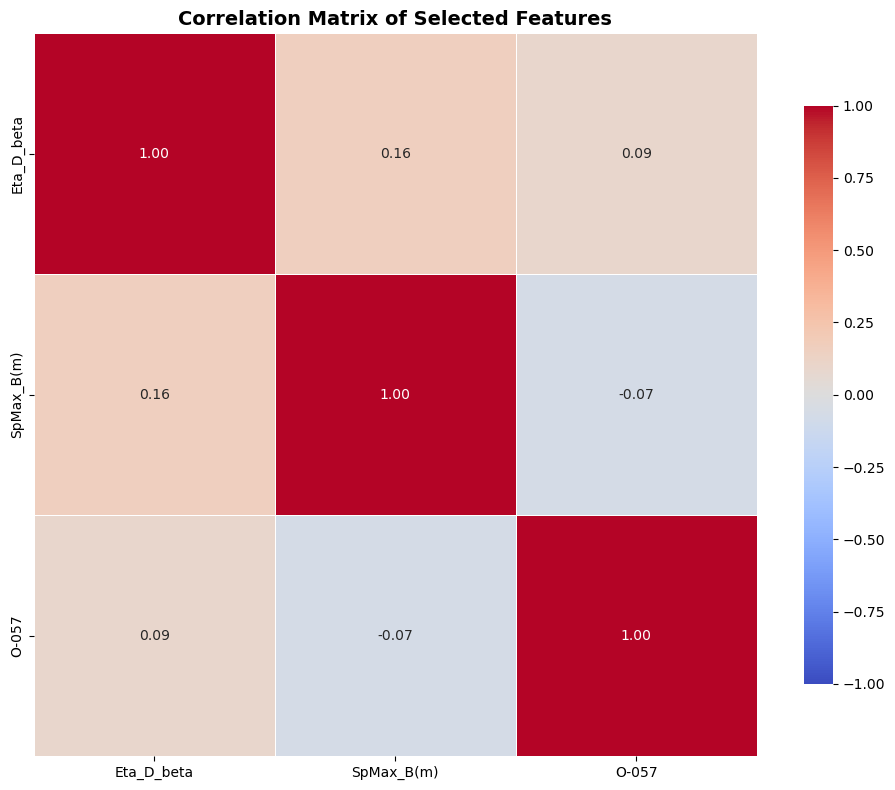


Y-randomization: 500 permutations on features ['Eta_D_beta', 'SpMax_B(m)', 'O-057']
Original model (CV): F1 = 0.6970 | BA = 0.7312 | ROC-AUC = 0.8000
Randomized (avg):    F1 = 0.5020 | BA = 0.5039 | ROC-AUC = 0.5034
Randomized (max):    F1 = 0.7234 | BA = 0.6816 | ROC-AUC = 0.7414
Permutations reaching the original ROC-AUC: 0.000

Model  Average F1  Average Balanced Accuracy  Average ROC-AUC
 H319       0.502                     0.5039           0.5034


In [29]:
#H319


import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.feature_selection import VarianceThreshold
from sklearn.metrics import (
    matthews_corrcoef,
    f1_score,
    balanced_accuracy_score,
    cohen_kappa_score,
    roc_auc_score
)



DATA_FILE = "H319.xlsx"
new_solvent_path = "Smiles_desc_distinct_cleaned.xlsx"

TEST_SIZE = 0.3
VAR_THRESHOLD = 0.01
CORR_THRESHOLD = 0.90
N_FEATURES = 3
N_OUTER = 3
N_INNER = 3
FINAL_SELECTION = "vote"
AD_K = 3


def filter_features(X):
    vt = VarianceThreshold(threshold=VAR_THRESHOLD).fit(X)
    cols = X.columns[vt.get_support()]
    corr = X[cols].corr().abs()
    upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
    to_drop = {c for c in upper.columns if any(upper[c] > CORR_THRESHOLD)}
    return [c for c in cols if c not in to_drop]


def fast_mcc(y_true, y_pred):
    tp = np.sum((y_true == 1) & (y_pred == 1))
    tn = np.sum((y_true == 0) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    denom = np.sqrt(float((tp + fp) * (tp + fn) * (tn + fp) * (tn + fn)))
    return 0.0 if denom == 0 else (tp * tn - fp * fn) / denom


def forward_selection(X, y, cv):
    names = list(X.columns)
    Xv, yv = X.to_numpy(dtype=float), y.to_numpy()
    folds = []
    for tr, va in cv.split(Xv, yv):
        sc = StandardScaler().fit(Xv[tr])
        folds.append((sc.transform(Xv[tr]), yv[tr], sc.transform(Xv[va]), yv[va]))

    selected, remaining = [], list(range(len(names)))
    for step in range(N_FEATURES):
        best_score, best_j = -np.inf, None
        for j in remaining:
            cols = selected + [j]
            scores = []
            for X_tr, y_tr, X_va, y_va in folds:
                m = make_model().fit(X_tr[:, cols], y_tr)
                scores.append(fast_mcc(y_va, m.predict(X_va[:, cols])))
            s = np.mean(scores)
            if s > best_score:
                best_score, best_j = s, j
        selected.append(best_j)
        remaining.remove(best_j)
    return [names[j] for j in selected]


def all_metrics(y_true, y_pred, y_score):
    return {
        "Balanced Accuracy": balanced_accuracy_score(y_true, y_pred),
        "F1": f1_score(y_true, y_pred),
        "MCC": matthews_corrcoef(y_true, y_pred),
        "Cohen's Kappa": cohen_kappa_score(y_true, y_pred),
        "ROC-AUC": roc_auc_score(y_true, y_score),
    }




def make_model():
    return SVC(kernel="rbf", C=1.0, class_weight="balanced", random_state=11)


full_df = pd.read_excel(DATA_FILE)
X = full_df.iloc[:, 1:-1]
y = full_df.iloc[:, -1]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=11
)
X_train = X_train.reset_index(drop=True)
X_test = X_test.reset_index(drop=True)
y_train = y_train.reset_index(drop=True)
y_test = y_test.reset_index(drop=True)


outer_cv = StratifiedKFold(n_splits=N_OUTER, shuffle=True, random_state=11)
inner_cv = StratifiedKFold(n_splits=N_INNER, shuffle=True, random_state=11)

fold_results = []
fold_features = []

for fold, (tr_idx, va_idx) in enumerate(outer_cv.split(X_train, y_train), 1):
    X_tr = X_train.iloc[tr_idx].reset_index(drop=True)
    X_va = X_train.iloc[va_idx].reset_index(drop=True)
    y_tr = y_train.iloc[tr_idx].reset_index(drop=True)
    y_va = y_train.iloc[va_idx].reset_index(drop=True)

    kept = filter_features(X_tr)
    feats = forward_selection(X_tr[kept], y_tr, inner_cv)

    fold_scaler = StandardScaler().fit(X_tr[feats])
    model = make_model().fit(fold_scaler.transform(X_tr[feats]), y_tr)

    X_va_s = fold_scaler.transform(X_va[feats])
    m = all_metrics(y_va, model.predict(X_va_s), model.decision_function(X_va_s))
    fold_results.append(m)
    fold_features.append(feats)

nested_df = pd.DataFrame(fold_results)
feature_freq = pd.Series([f for fs in fold_features for f in fs]).value_counts()


if FINAL_SELECTION == "vote":
    final_selected_features = list(feature_freq.index[:N_FEATURES])
else:
    kept = filter_features(X_train)
    final_selected_features = forward_selection(X_train[kept], y_train, inner_cv)

X_train_corr = X_train[final_selected_features]
scaler = StandardScaler().fit(X_train_corr)
X_train_final = pd.DataFrame(scaler.transform(X_train_corr), columns=final_selected_features)
X_test_final = pd.DataFrame(scaler.transform(X_test[final_selected_features]), columns=final_selected_features)

final_model = make_model().fit(X_train_final, y_train)

y_train_pred = final_model.predict(X_train_final)
y_test_pred = final_model.predict(X_test_final)
y_train_scores = final_model.decision_function(X_train_final)
y_test_scores = final_model.decision_function(X_test_final)

train_m = all_metrics(y_train, y_train_pred, y_train_scores)
test_m = all_metrics(y_test, y_test_pred, y_test_scores)
metric_names = list(train_m)

metrics = pd.DataFrame(
    [[len(y_train)] + [round(v, 4) for v in train_m.values()]
     + [len(y_test)] + [round(v, 4) for v in test_m.values()]],
    columns=["N_train"] + metric_names + ["N_test"] + metric_names,
)

print("Final descriptors:", final_selected_features)
print()
print(metrics.to_string(index=False))


feats = list(final_selected_features)
ad_scaler = StandardScaler().fit(X_train[feats])

X_tr_s = X_train_final[feats].to_numpy(dtype=float)
train_centroid = X_tr_s.mean(axis=0)
train_distances = np.linalg.norm(X_tr_s - train_centroid, axis=1)
AD_THRESHOLD = train_distances.mean() + AD_K * train_distances.std()


def ad_distance(X_scaled):
    return np.linalg.norm(np.asarray(X_scaled, dtype=float) - train_centroid, axis=1)


test_distances = ad_distance(X_test_final[feats])

new_solvents_df = pd.read_excel(new_solvent_path)
missing = [f for f in feats if f not in new_solvents_df.columns]
if missing:
    raise KeyError(f"New-solvent file is missing required features: {missing}")

new_names = new_solvents_df.iloc[:, 0]
X_new_raw = new_solvents_df[feats].apply(pd.to_numeric, errors="coerce")
valid = X_new_raw.notna().all(axis=1).to_numpy()

new_pred = np.full(len(X_new_raw), np.nan)
new_score = np.full(len(X_new_raw), np.nan)
new_distances = np.full(len(X_new_raw), np.nan)
if valid.any():
    X_new_scaled = pd.DataFrame(ad_scaler.transform(X_new_raw.loc[valid, feats]), columns=feats)
    new_pred[valid] = final_model.predict(X_new_scaled)
    new_score[valid] = final_model.decision_function(X_new_scaled)
    new_distances[valid] = ad_distance(X_new_scaled)

train_in_ad = train_distances <= AD_THRESHOLD
test_in_ad = test_distances <= AD_THRESHOLD
new_in_ad = valid & (np.nan_to_num(new_distances, nan=np.inf) <= AD_THRESHOLD)

ad_summary = pd.DataFrame({
    "Set": ["Train", "Test", "New solvents"],
    "Inside AD": [int(train_in_ad.sum()), int(test_in_ad.sum()), int(new_in_ad.sum())],
    "Total": [len(train_distances), len(test_distances), int(valid.sum())],
})
ad_summary["Inside AD (%)"] = (100 * ad_summary["Inside AD"] / ad_summary["Total"]).round(1)

print(f"\nApplicability domain (distance threshold = {AD_THRESHOLD:.4f}, mean + {AD_K}·SD)")
print(ad_summary.to_string(index=False))
if (~valid).any():
    print(f"{int((~valid).sum())} new solvents skipped (missing descriptor values)")

new_predictions = pd.DataFrame({
    "Solvent_Name": new_names.values,
    "Predicted_Class": pd.array(new_pred, dtype="Int64"),
    "SVM_Decision_Score": new_score,
    "Distance": new_distances,
    "AD_Status": np.where(~valid, "Not predicted",
                          np.where(new_in_ad, "Inside AD", "Outside AD")),
})

print(f"\nNew solvents: predicted class 1 = {int(np.nansum(new_pred == 1))}, "
      f"predicted class 0 = {int(np.nansum(new_pred == 0))}")


selected_corr_matrix = X_train[final_selected_features].corr()
plt.figure(figsize=(10, 8))
sns.heatmap(selected_corr_matrix, annot=True, cmap="coolwarm", fmt=".2f",
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.8},
            vmin=-1, vmax=1)
plt.title("Correlation Matrix of Selected Features", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

ENDPOINT_NAME = "H319"
N_PERMUTATIONS = 500


def cv_metrics(X_mat, y_vec, seed):
    cv = StratifiedKFold(n_splits=N_OUTER, shuffle=True, random_state=seed)
    pred = np.empty(len(y_vec))
    score = np.empty(len(y_vec))
    for tr, va in cv.split(X_mat, y_vec):
        m = make_model().fit(X_mat.iloc[tr], y_vec[tr])
        pred[va] = m.predict(X_mat.iloc[va])
        score[va] = m.decision_function(X_mat.iloc[va])
    return (f1_score(y_vec, pred, zero_division=0),
            balanced_accuracy_score(y_vec, pred),
            roc_auc_score(y_vec, score))


y_tr_np = y_train.to_numpy()
F1_orig, BA_orig, AUC_orig = cv_metrics(X_train_final, y_tr_np, 11)

rng = np.random.default_rng(2024)
rows = [cv_metrics(X_train_final, rng.permutation(y_tr_np), 11) for _ in range(N_PERMUTATIONS)]
yr = pd.DataFrame(rows, columns=["F1", "Balanced Accuracy", "ROC-AUC"])

print(f"\nY-randomization: {N_PERMUTATIONS} permutations on features {final_selected_features}")
print(f"Original model (CV): F1 = {F1_orig:.4f} | BA = {BA_orig:.4f} | ROC-AUC = {AUC_orig:.4f}")
print(f"Randomized (avg):    F1 = {yr['F1'].mean():.4f} | BA = {yr['Balanced Accuracy'].mean():.4f} | ROC-AUC = {yr['ROC-AUC'].mean():.4f}")
print(f"Randomized (max):    F1 = {yr['F1'].max():.4f} | BA = {yr['Balanced Accuracy'].max():.4f} | ROC-AUC = {yr['ROC-AUC'].max():.4f}")
print(f"Permutations reaching the original ROC-AUC: {(yr['ROC-AUC'] >= AUC_orig).mean():.3f}")

summary = pd.DataFrame([{
    "Model": ENDPOINT_NAME,
    "Average F1": round(yr["F1"].mean(), 4),
    "Average Balanced Accuracy": round(yr["Balanced Accuracy"].mean(), 4),
    "Average ROC-AUC": round(yr["ROC-AUC"].mean(), 4),
}])
print("\n" + summary.to_string(index=False))

Final descriptors: ['GATS1p', 'C-025', 'Melting Point (model 501)']

 N_train  Balanced Accuracy     F1    MCC  Cohen's Kappa  ROC-AUC  N_test  Balanced Accuracy     F1    MCC  Cohen's Kappa  ROC-AUC
      71             0.9271 0.8276 0.7906         0.7839   0.9403      24              0.925 0.7273 0.6969         0.6538   0.9375

Applicability domain (distance threshold = 4.0934, mean + 3·SD)
         Set  Inside AD  Total  Inside AD (%)
       Train         67     71           94.4
        Test         24     24          100.0
New solvents        104    105           99.0

New solvents: predicted class 1 = 20, predicted class 0 = 85


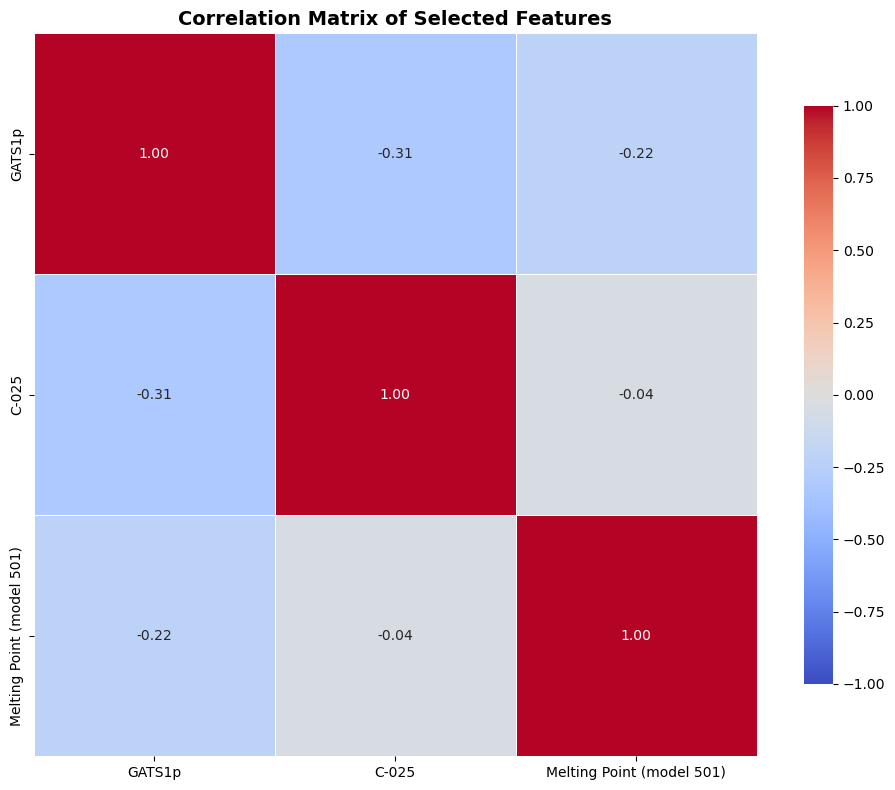


Y-randomization: 500 permutations on features ['GATS1p', 'C-025', 'Melting Point (model 501)']
Original model (CV): F1 = 0.6897 | BA = 0.8329 | ROC-AUC = 0.8117
Randomized (avg):    F1 = 0.2570 | BA = 0.5029 | ROC-AUC = 0.4996
Randomized (max):    F1 = 0.5333 | BA = 0.7891 | ROC-AUC = 0.7971
Permutations reaching the original ROC-AUC: 0.000

Model  Average F1  Average Balanced Accuracy  Average ROC-AUC
 H331       0.257                     0.5029           0.4996


In [28]:
#H331

import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.feature_selection import VarianceThreshold
from sklearn.metrics import (
    matthews_corrcoef,
    f1_score,
    balanced_accuracy_score,
    cohen_kappa_score,
    roc_auc_score
)

TEST_SIZE = 0.25
VAR_THRESHOLD = 0.01
CORR_THRESHOLD = 0.90
N_FEATURES = 3
N_OUTER = 3
N_INNER = 3
FINAL_SELECTION = "vote"
AD_K = 3


DATA_FILE = "H331.xlsx"
new_solvent_path = "Smiles_desc_distinct_cleaned.xlsx"


def filter_features(X):
    vt = VarianceThreshold(threshold=VAR_THRESHOLD).fit(X)
    cols = X.columns[vt.get_support()]
    corr = X[cols].corr().abs()
    upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
    to_drop = {c for c in upper.columns if any(upper[c] > CORR_THRESHOLD)}
    return [c for c in cols if c not in to_drop]


def fast_mcc(y_true, y_pred):
    tp = np.sum((y_true == 1) & (y_pred == 1))
    tn = np.sum((y_true == 0) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    denom = np.sqrt(float((tp + fp) * (tp + fn) * (tn + fp) * (tn + fn)))
    return 0.0 if denom == 0 else (tp * tn - fp * fn) / denom


def forward_selection(X, y, cv):
    names = list(X.columns)
    Xv, yv = X.to_numpy(dtype=float), y.to_numpy()
    folds = []
    for tr, va in cv.split(Xv, yv):
        sc = StandardScaler().fit(Xv[tr])
        folds.append((sc.transform(Xv[tr]), yv[tr], sc.transform(Xv[va]), yv[va]))

    selected, remaining = [], list(range(len(names)))
    for step in range(N_FEATURES):
        best_score, best_j = -np.inf, None
        for j in remaining:
            cols = selected + [j]
            scores = []
            for X_tr, y_tr, X_va, y_va in folds:
                m = make_model().fit(X_tr[:, cols], y_tr)
                scores.append(fast_mcc(y_va, m.predict(X_va[:, cols])))
            s = np.mean(scores)
            if s > best_score:
                best_score, best_j = s, j
        selected.append(best_j)
        remaining.remove(best_j)
    return [names[j] for j in selected]


def all_metrics(y_true, y_pred, y_score):
    return {
        "Balanced Accuracy": balanced_accuracy_score(y_true, y_pred),
        "F1": f1_score(y_true, y_pred),
        "MCC": matthews_corrcoef(y_true, y_pred),
        "Cohen's Kappa": cohen_kappa_score(y_true, y_pred),
        "ROC-AUC": roc_auc_score(y_true, y_score),
    }


def make_model():
    return SVC(kernel="rbf", C=1.0, class_weight="balanced", random_state=14)



full_df = pd.read_excel(DATA_FILE)
X = full_df.iloc[:, 1:-1]
y = full_df.iloc[:, -1]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=14
)
X_train = X_train.reset_index(drop=True)
X_test = X_test.reset_index(drop=True)
y_train = y_train.reset_index(drop=True)
y_test = y_test.reset_index(drop=True)


outer_cv = StratifiedKFold(n_splits=N_OUTER, shuffle=True, random_state=14)
inner_cv = StratifiedKFold(n_splits=N_INNER, shuffle=True, random_state=14)

fold_results = []
fold_features = []

for fold, (tr_idx, va_idx) in enumerate(outer_cv.split(X_train, y_train), 1):
    X_tr = X_train.iloc[tr_idx].reset_index(drop=True)
    X_va = X_train.iloc[va_idx].reset_index(drop=True)
    y_tr = y_train.iloc[tr_idx].reset_index(drop=True)
    y_va = y_train.iloc[va_idx].reset_index(drop=True)

    kept = filter_features(X_tr)
    feats = forward_selection(X_tr[kept], y_tr, inner_cv)

    fold_scaler = StandardScaler().fit(X_tr[feats])
    model = make_model().fit(fold_scaler.transform(X_tr[feats]), y_tr)

    X_va_s = fold_scaler.transform(X_va[feats])
    m = all_metrics(y_va, model.predict(X_va_s), model.decision_function(X_va_s))
    fold_results.append(m)
    fold_features.append(feats)

nested_df = pd.DataFrame(fold_results)
feature_freq = pd.Series([f for fs in fold_features for f in fs]).value_counts()


if FINAL_SELECTION == "vote":
    final_selected_features = list(feature_freq.index[:N_FEATURES])
else:
    kept = filter_features(X_train)
    final_selected_features = forward_selection(X_train[kept], y_train, inner_cv)

X_train_corr = X_train[final_selected_features]
scaler = StandardScaler().fit(X_train_corr)
X_train_final = pd.DataFrame(scaler.transform(X_train_corr), columns=final_selected_features)
X_test_final = pd.DataFrame(scaler.transform(X_test[final_selected_features]), columns=final_selected_features)

final_model = make_model().fit(X_train_final, y_train)

y_train_pred = final_model.predict(X_train_final)
y_test_pred = final_model.predict(X_test_final)
y_train_scores = final_model.decision_function(X_train_final)
y_test_scores = final_model.decision_function(X_test_final)

train_m = all_metrics(y_train, y_train_pred, y_train_scores)
test_m = all_metrics(y_test, y_test_pred, y_test_scores)
metric_names = list(train_m)

metrics = pd.DataFrame(
    [[len(y_train)] + [round(v, 4) for v in train_m.values()]
     + [len(y_test)] + [round(v, 4) for v in test_m.values()]],
    columns=["N_train"] + metric_names + ["N_test"] + metric_names,
)

print("Final descriptors:", final_selected_features)
print()
print(metrics.to_string(index=False))


feats = list(final_selected_features)
ad_scaler = StandardScaler().fit(X_train[feats])

X_tr_s = X_train_final[feats].to_numpy(dtype=float)
train_centroid = X_tr_s.mean(axis=0)
train_distances = np.linalg.norm(X_tr_s - train_centroid, axis=1)
AD_THRESHOLD = train_distances.mean() + AD_K * train_distances.std()


def ad_distance(X_scaled):
    return np.linalg.norm(np.asarray(X_scaled, dtype=float) - train_centroid, axis=1)


test_distances = ad_distance(X_test_final[feats])

new_solvents_df = pd.read_excel(new_solvent_path)
missing = [f for f in feats if f not in new_solvents_df.columns]
if missing:
    raise KeyError(f"New-solvent file is missing required features: {missing}")

new_names = new_solvents_df.iloc[:, 0]
X_new_raw = new_solvents_df[feats].apply(pd.to_numeric, errors="coerce")
valid = X_new_raw.notna().all(axis=1).to_numpy()

new_pred = np.full(len(X_new_raw), np.nan)
new_score = np.full(len(X_new_raw), np.nan)
new_distances = np.full(len(X_new_raw), np.nan)
if valid.any():
    X_new_scaled = pd.DataFrame(ad_scaler.transform(X_new_raw.loc[valid, feats]), columns=feats)
    new_pred[valid] = final_model.predict(X_new_scaled)
    new_score[valid] = final_model.decision_function(X_new_scaled)
    new_distances[valid] = ad_distance(X_new_scaled)

train_in_ad = train_distances <= AD_THRESHOLD
test_in_ad = test_distances <= AD_THRESHOLD
new_in_ad = valid & (np.nan_to_num(new_distances, nan=np.inf) <= AD_THRESHOLD)

ad_summary = pd.DataFrame({
    "Set": ["Train", "Test", "New solvents"],
    "Inside AD": [int(train_in_ad.sum()), int(test_in_ad.sum()), int(new_in_ad.sum())],
    "Total": [len(train_distances), len(test_distances), int(valid.sum())],
})
ad_summary["Inside AD (%)"] = (100 * ad_summary["Inside AD"] / ad_summary["Total"]).round(1)

print(f"\nApplicability domain (distance threshold = {AD_THRESHOLD:.4f}, mean + {AD_K}·SD)")
print(ad_summary.to_string(index=False))
if (~valid).any():
    print(f"{int((~valid).sum())} new solvents skipped (missing descriptor values)")

new_predictions = pd.DataFrame({
    "Solvent_Name": new_names.values,
    "Predicted_Class": pd.array(new_pred, dtype="Int64"),
    "SVM_Decision_Score": new_score,
    "Distance": new_distances,
    "AD_Status": np.where(~valid, "Not predicted",
                          np.where(new_in_ad, "Inside AD", "Outside AD")),
})

print(f"\nNew solvents: predicted class 1 = {int(np.nansum(new_pred == 1))}, "
      f"predicted class 0 = {int(np.nansum(new_pred == 0))}")


selected_corr_matrix = X_train[final_selected_features].corr()
plt.figure(figsize=(10, 8))
sns.heatmap(selected_corr_matrix, annot=True, cmap="coolwarm", fmt=".2f",
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.8},
            vmin=-1, vmax=1)
plt.title("Correlation Matrix of Selected Features", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

ENDPOINT_NAME = "H331"
N_PERMUTATIONS = 500


def cv_metrics(X_mat, y_vec, seed):
    cv = StratifiedKFold(n_splits=N_OUTER, shuffle=True, random_state=seed)
    pred = np.empty(len(y_vec))
    score = np.empty(len(y_vec))
    for tr, va in cv.split(X_mat, y_vec):
        m = make_model().fit(X_mat.iloc[tr], y_vec[tr])
        pred[va] = m.predict(X_mat.iloc[va])
        score[va] = m.decision_function(X_mat.iloc[va])
    return (f1_score(y_vec, pred, zero_division=0),
            balanced_accuracy_score(y_vec, pred),
            roc_auc_score(y_vec, score))


y_tr_np = y_train.to_numpy()
F1_orig, BA_orig, AUC_orig = cv_metrics(X_train_final, y_tr_np, 14)

rng = np.random.default_rng(2024)
rows = [cv_metrics(X_train_final, rng.permutation(y_tr_np), 14) for _ in range(N_PERMUTATIONS)]
yr = pd.DataFrame(rows, columns=["F1", "Balanced Accuracy", "ROC-AUC"])

print(f"\nY-randomization: {N_PERMUTATIONS} permutations on features {final_selected_features}")
print(f"Original model (CV): F1 = {F1_orig:.4f} | BA = {BA_orig:.4f} | ROC-AUC = {AUC_orig:.4f}")
print(f"Randomized (avg):    F1 = {yr['F1'].mean():.4f} | BA = {yr['Balanced Accuracy'].mean():.4f} | ROC-AUC = {yr['ROC-AUC'].mean():.4f}")
print(f"Randomized (max):    F1 = {yr['F1'].max():.4f} | BA = {yr['Balanced Accuracy'].max():.4f} | ROC-AUC = {yr['ROC-AUC'].max():.4f}")
print(f"Permutations reaching the original ROC-AUC: {(yr['ROC-AUC'] >= AUC_orig).mean():.3f}")

summary = pd.DataFrame([{
    "Model": ENDPOINT_NAME,
    "Average F1": round(yr["F1"].mean(), 4),
    "Average Balanced Accuracy": round(yr["Balanced Accuracy"].mean(), 4),
    "Average ROC-AUC": round(yr["ROC-AUC"].mean(), 4),
}])
print("\n" + summary.to_string(index=False))

Final descriptors: ['B01[C-O]', 'IVDE', 'P_VSA_MR_5']

 N_train  Balanced Accuracy     F1    MCC  Cohen's Kappa  ROC-AUC  N_test  Balanced Accuracy     F1    MCC  Cohen's Kappa  ROC-AUC
      69             0.8574 0.6923 0.6343          0.623   0.8997      23             0.9211 0.7273 0.6937         0.6497   0.9013

Applicability domain (distance threshold = 3.3572, mean + 3·SD)
         Set  Inside AD  Total  Inside AD (%)
       Train         69     69          100.0
        Test         23     23          100.0
New solvents        101    105           96.2

New solvents: predicted class 1 = 21, predicted class 0 = 84


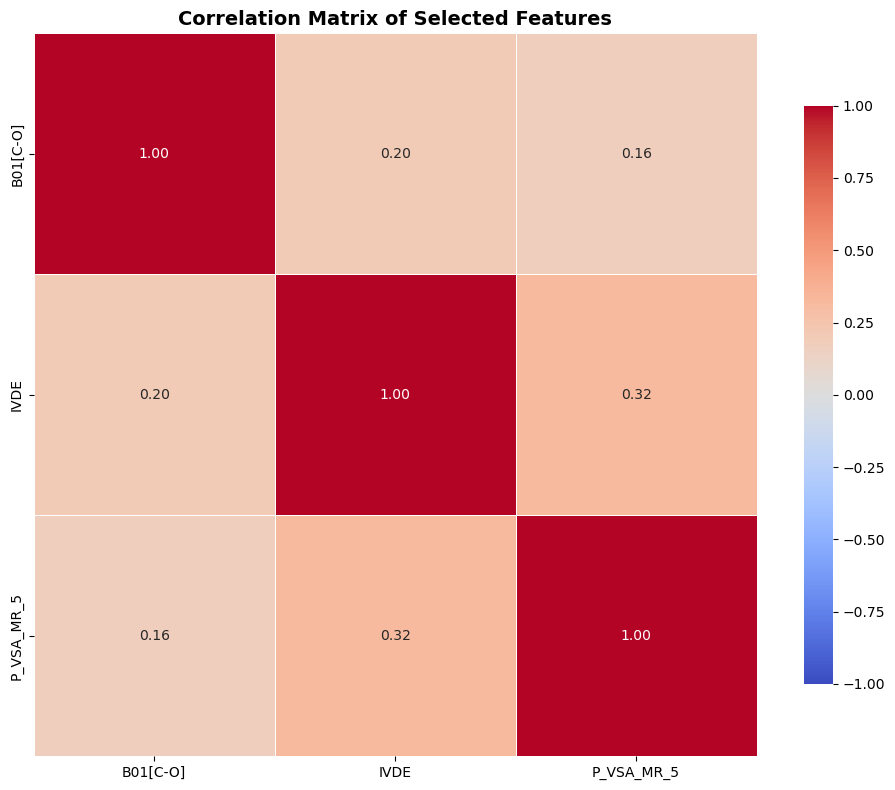


Y-randomization: 500 permutations on features ['B01[C-O]', 'IVDE', 'P_VSA_MR_5']
Original model (CV): F1 = 0.4667 | BA = 0.7147 | ROC-AUC = 0.6677
Randomized (avg):    F1 = 0.2266 | BA = 0.4996 | ROC-AUC = 0.4939
Randomized (max):    F1 = 0.4865 | BA = 0.7735 | ROC-AUC = 0.7884
Permutations reaching the original ROC-AUC: 0.092

Model  Average F1  Average Balanced Accuracy  Average ROC-AUC
 H351      0.2266                     0.4996           0.4939


In [30]:
#H351

import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.feature_selection import VarianceThreshold
from sklearn.metrics import (
    matthews_corrcoef,
    f1_score,
    balanced_accuracy_score,
    cohen_kappa_score,
    roc_auc_score
)

TEST_SIZE = 0.25
VAR_THRESHOLD = 0.01
CORR_THRESHOLD = 0.85
N_FEATURES = 3
N_OUTER = 3
N_INNER = 3
FINAL_SELECTION = "vote"
AD_K = 3


DATA_FILE = "H351.xlsx"
new_solvent_path = "Smiles_desc_distinct_cleaned.xlsx"


def filter_features(X):
    vt = VarianceThreshold(threshold=VAR_THRESHOLD).fit(X)
    cols = X.columns[vt.get_support()]
    corr = X[cols].corr().abs()
    upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
    to_drop = {c for c in upper.columns if any(upper[c] > CORR_THRESHOLD)}
    return [c for c in cols if c not in to_drop]


def fast_mcc(y_true, y_pred):
    tp = np.sum((y_true == 1) & (y_pred == 1))
    tn = np.sum((y_true == 0) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    denom = np.sqrt(float((tp + fp) * (tp + fn) * (tn + fp) * (tn + fn)))
    return 0.0 if denom == 0 else (tp * tn - fp * fn) / denom


def forward_selection(X, y, cv):
    names = list(X.columns)
    Xv, yv = X.to_numpy(dtype=float), y.to_numpy()
    folds = []
    for tr, va in cv.split(Xv, yv):
        sc = StandardScaler().fit(Xv[tr])
        folds.append((sc.transform(Xv[tr]), yv[tr], sc.transform(Xv[va]), yv[va]))

    selected, remaining = [], list(range(len(names)))
    for step in range(N_FEATURES):
        best_score, best_j = -np.inf, None
        for j in remaining:
            cols = selected + [j]
            scores = []
            for X_tr, y_tr, X_va, y_va in folds:
                m = make_model().fit(X_tr[:, cols], y_tr)
                scores.append(fast_mcc(y_va, m.predict(X_va[:, cols])))
            s = np.mean(scores)
            if s > best_score:
                best_score, best_j = s, j
        selected.append(best_j)
        remaining.remove(best_j)
    return [names[j] for j in selected]


def all_metrics(y_true, y_pred, y_score):
    return {
        "Balanced Accuracy": balanced_accuracy_score(y_true, y_pred),
        "F1": f1_score(y_true, y_pred),
        "MCC": matthews_corrcoef(y_true, y_pred),
        "Cohen's Kappa": cohen_kappa_score(y_true, y_pred),
        "ROC-AUC": roc_auc_score(y_true, y_score),
    }

def make_model():
    return SVC(kernel="rbf", C=1.0, class_weight="balanced", random_state=23)


full_df = pd.read_excel(DATA_FILE)
X = full_df.iloc[:, 1:-1]
y = full_df.iloc[:, -1]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=23
)
X_train = X_train.reset_index(drop=True)
X_test = X_test.reset_index(drop=True)
y_train = y_train.reset_index(drop=True)
y_test = y_test.reset_index(drop=True)


outer_cv = StratifiedKFold(n_splits=N_OUTER, shuffle=True, random_state=23)
inner_cv = StratifiedKFold(n_splits=N_INNER, shuffle=True, random_state=23)

fold_results = []
fold_features = []

for fold, (tr_idx, va_idx) in enumerate(outer_cv.split(X_train, y_train), 1):
    X_tr = X_train.iloc[tr_idx].reset_index(drop=True)
    X_va = X_train.iloc[va_idx].reset_index(drop=True)
    y_tr = y_train.iloc[tr_idx].reset_index(drop=True)
    y_va = y_train.iloc[va_idx].reset_index(drop=True)

    kept = filter_features(X_tr)
    feats = forward_selection(X_tr[kept], y_tr, inner_cv)

    fold_scaler = StandardScaler().fit(X_tr[feats])
    model = make_model().fit(fold_scaler.transform(X_tr[feats]), y_tr)

    X_va_s = fold_scaler.transform(X_va[feats])
    m = all_metrics(y_va, model.predict(X_va_s), model.decision_function(X_va_s))
    fold_results.append(m)
    fold_features.append(feats)

nested_df = pd.DataFrame(fold_results)
feature_freq = pd.Series([f for fs in fold_features for f in fs]).value_counts()


if FINAL_SELECTION == "vote":
    final_selected_features = list(feature_freq.index[:N_FEATURES])
else:
    kept = filter_features(X_train)
    final_selected_features = forward_selection(X_train[kept], y_train, inner_cv)

X_train_corr = X_train[final_selected_features]
scaler = StandardScaler().fit(X_train_corr)
X_train_final = pd.DataFrame(scaler.transform(X_train_corr), columns=final_selected_features)
X_test_final = pd.DataFrame(scaler.transform(X_test[final_selected_features]), columns=final_selected_features)

final_model = make_model().fit(X_train_final, y_train)

y_train_pred = final_model.predict(X_train_final)
y_test_pred = final_model.predict(X_test_final)
y_train_scores = final_model.decision_function(X_train_final)
y_test_scores = final_model.decision_function(X_test_final)

train_m = all_metrics(y_train, y_train_pred, y_train_scores)
test_m = all_metrics(y_test, y_test_pred, y_test_scores)
metric_names = list(train_m)

metrics = pd.DataFrame(
    [[len(y_train)] + [round(v, 4) for v in train_m.values()]
     + [len(y_test)] + [round(v, 4) for v in test_m.values()]],
    columns=["N_train"] + metric_names + ["N_test"] + metric_names,
)

print("Final descriptors:", final_selected_features)
print()
print(metrics.to_string(index=False))


feats = list(final_selected_features)
ad_scaler = StandardScaler().fit(X_train[feats])

X_tr_s = X_train_final[feats].to_numpy(dtype=float)
train_centroid = X_tr_s.mean(axis=0)
train_distances = np.linalg.norm(X_tr_s - train_centroid, axis=1)
AD_THRESHOLD = train_distances.mean() + AD_K * train_distances.std()


def ad_distance(X_scaled):
    return np.linalg.norm(np.asarray(X_scaled, dtype=float) - train_centroid, axis=1)


test_distances = ad_distance(X_test_final[feats])

new_solvents_df = pd.read_excel(NEW_SOLVENTS_PATH)
missing = [f for f in feats if f not in new_solvents_df.columns]
if missing:
    raise KeyError(f"New-solvent file is missing required features: {missing}")

new_names = new_solvents_df.iloc[:, 0]
X_new_raw = new_solvents_df[feats].apply(pd.to_numeric, errors="coerce")
valid = X_new_raw.notna().all(axis=1).to_numpy()

new_pred = np.full(len(X_new_raw), np.nan)
new_score = np.full(len(X_new_raw), np.nan)
new_distances = np.full(len(X_new_raw), np.nan)
if valid.any():
    X_new_scaled = pd.DataFrame(ad_scaler.transform(X_new_raw.loc[valid, feats]), columns=feats)
    new_pred[valid] = final_model.predict(X_new_scaled)
    new_score[valid] = final_model.decision_function(X_new_scaled)
    new_distances[valid] = ad_distance(X_new_scaled)

train_in_ad = train_distances <= AD_THRESHOLD
test_in_ad = test_distances <= AD_THRESHOLD
new_in_ad = valid & (np.nan_to_num(new_distances, nan=np.inf) <= AD_THRESHOLD)

ad_summary = pd.DataFrame({
    "Set": ["Train", "Test", "New solvents"],
    "Inside AD": [int(train_in_ad.sum()), int(test_in_ad.sum()), int(new_in_ad.sum())],
    "Total": [len(train_distances), len(test_distances), int(valid.sum())],
})
ad_summary["Inside AD (%)"] = (100 * ad_summary["Inside AD"] / ad_summary["Total"]).round(1)

print(f"\nApplicability domain (distance threshold = {AD_THRESHOLD:.4f}, mean + {AD_K}·SD)")
print(ad_summary.to_string(index=False))
if (~valid).any():
    print(f"{int((~valid).sum())} new solvents skipped (missing descriptor values)")

new_predictions = pd.DataFrame({
    "Solvent_Name": new_names.values,
    "Predicted_Class": pd.array(new_pred, dtype="Int64"),
    "SVM_Decision_Score": new_score,
    "Distance": new_distances,
    "AD_Status": np.where(~valid, "Not predicted",
                          np.where(new_in_ad, "Inside AD", "Outside AD")),
})

print(f"\nNew solvents: predicted class 1 = {int(np.nansum(new_pred == 1))}, "
      f"predicted class 0 = {int(np.nansum(new_pred == 0))}")


selected_corr_matrix = X_train[final_selected_features].corr()
plt.figure(figsize=(10, 8))
sns.heatmap(selected_corr_matrix, annot=True, cmap="coolwarm", fmt=".2f",
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.8},
            vmin=-1, vmax=1)
plt.title("Correlation Matrix of Selected Features", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


ENDPOINT_NAME = "H351"
N_PERMUTATIONS = 500


def cv_metrics(X_mat, y_vec, seed):
    cv = StratifiedKFold(n_splits=N_OUTER, shuffle=True, random_state=seed)
    pred = np.empty(len(y_vec))
    score = np.empty(len(y_vec))
    for tr, va in cv.split(X_mat, y_vec):
        m = make_model().fit(X_mat.iloc[tr], y_vec[tr])
        pred[va] = m.predict(X_mat.iloc[va])
        score[va] = m.decision_function(X_mat.iloc[va])
    return (f1_score(y_vec, pred, zero_division=0),
            balanced_accuracy_score(y_vec, pred),
            roc_auc_score(y_vec, score))


y_tr_np = y_train.to_numpy()
F1_orig, BA_orig, AUC_orig = cv_metrics(X_train_final, y_tr_np, 23)

rng = np.random.default_rng(2024)
rows = [cv_metrics(X_train_final, rng.permutation(y_tr_np), 23) for _ in range(N_PERMUTATIONS)]
yr = pd.DataFrame(rows, columns=["F1", "Balanced Accuracy", "ROC-AUC"])

print(f"\nY-randomization: {N_PERMUTATIONS} permutations on features {final_selected_features}")
print(f"Original model (CV): F1 = {F1_orig:.4f} | BA = {BA_orig:.4f} | ROC-AUC = {AUC_orig:.4f}")
print(f"Randomized (avg):    F1 = {yr['F1'].mean():.4f} | BA = {yr['Balanced Accuracy'].mean():.4f} | ROC-AUC = {yr['ROC-AUC'].mean():.4f}")
print(f"Randomized (max):    F1 = {yr['F1'].max():.4f} | BA = {yr['Balanced Accuracy'].max():.4f} | ROC-AUC = {yr['ROC-AUC'].max():.4f}")
print(f"Permutations reaching the original ROC-AUC: {(yr['ROC-AUC'] >= AUC_orig).mean():.3f}")

summary = pd.DataFrame([{
    "Model": ENDPOINT_NAME,
    "Average F1": round(yr["F1"].mean(), 4),
    "Average Balanced Accuracy": round(yr["Balanced Accuracy"].mean(), 4),
    "Average ROC-AUC": round(yr["ROC-AUC"].mean(), 4),
}])
print("\n" + summary.to_string(index=False))

Final descriptors: ['P_VSA_m_2', 'H-047', 'P_VSA_LogP_1', 'VE1sign_B(s)']

 N_train  Balanced Accuracy     F1    MCC  Cohen's Kappa  ROC-AUC  N_test  Balanced Accuracy  F1    MCC  Cohen's Kappa  ROC-AUC
      58                0.9 0.6154 0.5963         0.5246     0.95      25             0.8036 0.6 0.5212          0.505   0.8214

Applicability domain (distance threshold = 4.1635, mean + 3·SD)
         Set  Inside AD  Total  Inside AD (%)
       Train         56     58           96.6
        Test         23     25           92.0
New solvents        103    105           98.1

New solvents: predicted class 1 = 27, predicted class 0 = 78


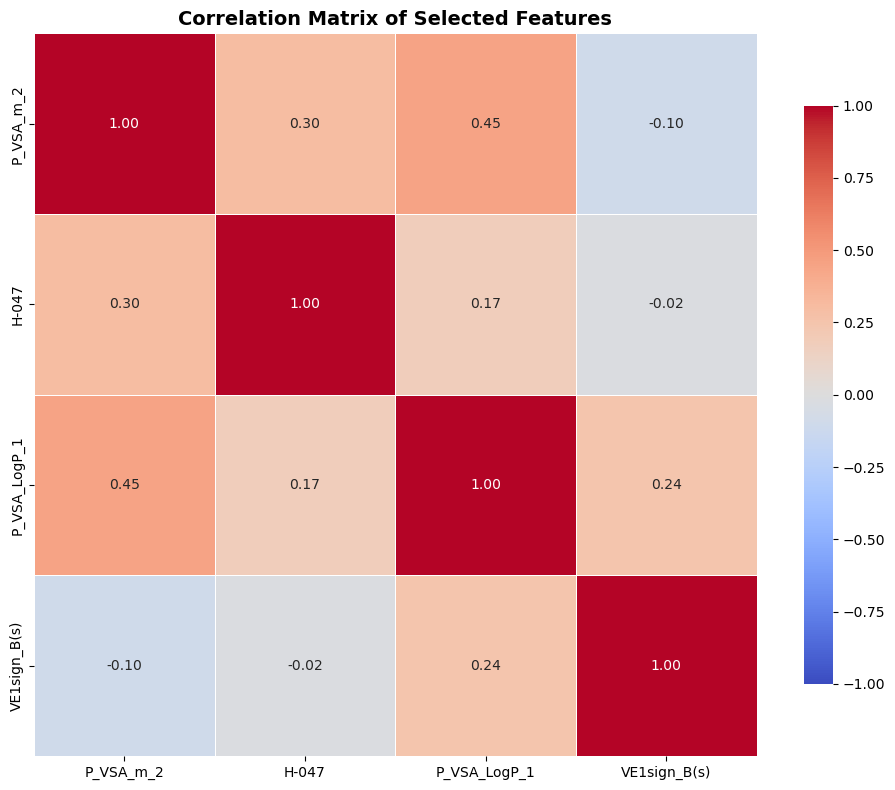


Y-randomization: 500 permutations on features ['P_VSA_m_2', 'H-047', 'P_VSA_LogP_1', 'VE1sign_B(s)']
Original model (CV): F1 = 0.5000 | BA = 0.8075 | ROC-AUC = 0.8875
Randomized (avg):    F1 = 0.1924 | BA = 0.5000 | ROC-AUC = 0.4969
Randomized (max):    F1 = 0.5556 | BA = 0.8175 | ROC-AUC = 0.8700
Permutations reaching the original ROC-AUC: 0.000

 Model  Average F1  Average Balanced Accuracy  Average ROC-AUC
EUH066      0.1924                        0.5           0.4969

Y-randomization: 500 permutations on features ['P_VSA_m_2', 'H-047', 'P_VSA_LogP_1', 'VE1sign_B(s)']
Original model (CV): F1 = 0.5000 | BA = 0.8075 | ROC-AUC = 0.8875
Randomized (avg):    F1 = 0.1924 | BA = 0.5000 | ROC-AUC = 0.4969
Randomized (max):    F1 = 0.5556 | BA = 0.8175 | ROC-AUC = 0.8700
Permutations reaching the original ROC-AUC: 0.000

 Model  Average F1  Average Balanced Accuracy  Average ROC-AUC
EUH066      0.1924                        0.5           0.4969


In [31]:
#EUH066

import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.feature_selection import VarianceThreshold
from sklearn.metrics import (
    matthews_corrcoef,
    f1_score,
    balanced_accuracy_score,
    cohen_kappa_score,
    roc_auc_score
)

TEST_SIZE = 0.3
VAR_THRESHOLD = 0.01
CORR_THRESHOLD = 0.85
N_FEATURES = 4
N_OUTER = 3
N_INNER = 3
FINAL_SELECTION = "vote"
AD_K = 3


DATA_FILE = "EUH066.xlsx"
new_solvent_path = "Smiles_desc_distinct_cleaned.xlsx"


def filter_features(X):
    vt = VarianceThreshold(threshold=VAR_THRESHOLD).fit(X)
    cols = X.columns[vt.get_support()]
    corr = X[cols].corr().abs()
    upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
    to_drop = {c for c in upper.columns if any(upper[c] > CORR_THRESHOLD)}
    return [c for c in cols if c not in to_drop]


def fast_mcc(y_true, y_pred):
    tp = np.sum((y_true == 1) & (y_pred == 1))
    tn = np.sum((y_true == 0) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    denom = np.sqrt(float((tp + fp) * (tp + fn) * (tn + fp) * (tn + fn)))
    return 0.0 if denom == 0 else (tp * tn - fp * fn) / denom


def forward_selection(X, y, cv):
    names = list(X.columns)
    Xv, yv = X.to_numpy(dtype=float), y.to_numpy()
    folds = []
    for tr, va in cv.split(Xv, yv):
        sc = StandardScaler().fit(Xv[tr])
        folds.append((sc.transform(Xv[tr]), yv[tr], sc.transform(Xv[va]), yv[va]))

    selected, remaining = [], list(range(len(names)))
    for step in range(N_FEATURES):
        best_score, best_j = -np.inf, None
        for j in remaining:
            cols = selected + [j]
            scores = []
            for X_tr, y_tr, X_va, y_va in folds:
                m = make_model().fit(X_tr[:, cols], y_tr)
                scores.append(fast_mcc(y_va, m.predict(X_va[:, cols])))
            s = np.mean(scores)
            if s > best_score:
                best_score, best_j = s, j
        selected.append(best_j)
        remaining.remove(best_j)
    return [names[j] for j in selected]


def all_metrics(y_true, y_pred, y_score):
    return {
        "Balanced Accuracy": balanced_accuracy_score(y_true, y_pred),
        "F1": f1_score(y_true, y_pred),
        "MCC": matthews_corrcoef(y_true, y_pred),
        "Cohen's Kappa": cohen_kappa_score(y_true, y_pred),
        "ROC-AUC": roc_auc_score(y_true, y_score),
    }

def make_model():
    return SVC(kernel="rbf", C=1.0, class_weight="balanced", random_state=22)
    

full_df = pd.read_excel(DATA_FILE)
X = full_df.iloc[:, 1:-1]
y = full_df.iloc[:, -1]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=22
)
X_train = X_train.reset_index(drop=True)
X_test = X_test.reset_index(drop=True)
y_train = y_train.reset_index(drop=True)
y_test = y_test.reset_index(drop=True)


outer_cv = StratifiedKFold(n_splits=N_OUTER, shuffle=True, random_state=22)
inner_cv = StratifiedKFold(n_splits=N_INNER, shuffle=True, random_state=22)

fold_results = []
fold_features = []

for fold, (tr_idx, va_idx) in enumerate(outer_cv.split(X_train, y_train), 1):
    X_tr = X_train.iloc[tr_idx].reset_index(drop=True)
    X_va = X_train.iloc[va_idx].reset_index(drop=True)
    y_tr = y_train.iloc[tr_idx].reset_index(drop=True)
    y_va = y_train.iloc[va_idx].reset_index(drop=True)

    kept = filter_features(X_tr)
    feats = forward_selection(X_tr[kept], y_tr, inner_cv)

    fold_scaler = StandardScaler().fit(X_tr[feats])
    model = make_model().fit(fold_scaler.transform(X_tr[feats]), y_tr)

    X_va_s = fold_scaler.transform(X_va[feats])
    m = all_metrics(y_va, model.predict(X_va_s), model.decision_function(X_va_s))
    fold_results.append(m)
    fold_features.append(feats)

nested_df = pd.DataFrame(fold_results)
feature_freq = pd.Series([f for fs in fold_features for f in fs]).value_counts()


if FINAL_SELECTION == "vote":
    final_selected_features = list(feature_freq.index[:N_FEATURES])
else:
    kept = filter_features(X_train)
    final_selected_features = forward_selection(X_train[kept], y_train, inner_cv)

X_train_corr = X_train[final_selected_features]
scaler = StandardScaler().fit(X_train_corr)
X_train_final = pd.DataFrame(scaler.transform(X_train_corr), columns=final_selected_features)
X_test_final = pd.DataFrame(scaler.transform(X_test[final_selected_features]), columns=final_selected_features)

final_model = make_model().fit(X_train_final, y_train)

y_train_pred = final_model.predict(X_train_final)
y_test_pred = final_model.predict(X_test_final)
y_train_scores = final_model.decision_function(X_train_final)
y_test_scores = final_model.decision_function(X_test_final)

train_m = all_metrics(y_train, y_train_pred, y_train_scores)
test_m = all_metrics(y_test, y_test_pred, y_test_scores)
metric_names = list(train_m)

metrics = pd.DataFrame(
    [[len(y_train)] + [round(v, 4) for v in train_m.values()]
     + [len(y_test)] + [round(v, 4) for v in test_m.values()]],
    columns=["N_train"] + metric_names + ["N_test"] + metric_names,
)

print("Final descriptors:", final_selected_features)
print()
print(metrics.to_string(index=False))


feats = list(final_selected_features)
ad_scaler = StandardScaler().fit(X_train[feats])

X_tr_s = X_train_final[feats].to_numpy(dtype=float)
train_centroid = X_tr_s.mean(axis=0)
train_distances = np.linalg.norm(X_tr_s - train_centroid, axis=1)
AD_THRESHOLD = train_distances.mean() + AD_K * train_distances.std()


def ad_distance(X_scaled):
    return np.linalg.norm(np.asarray(X_scaled, dtype=float) - train_centroid, axis=1)


test_distances = ad_distance(X_test_final[feats])

new_solvents_df = pd.read_excel(NEW_SOLVENTS_PATH)
missing = [f for f in feats if f not in new_solvents_df.columns]
if missing:
    raise KeyError(f"New-solvent file is missing required features: {missing}")

new_names = new_solvents_df.iloc[:, 0]
X_new_raw = new_solvents_df[feats].apply(pd.to_numeric, errors="coerce")
valid = X_new_raw.notna().all(axis=1).to_numpy()

new_pred = np.full(len(X_new_raw), np.nan)
new_score = np.full(len(X_new_raw), np.nan)
new_distances = np.full(len(X_new_raw), np.nan)
if valid.any():
    X_new_scaled = pd.DataFrame(ad_scaler.transform(X_new_raw.loc[valid, feats]), columns=feats)
    new_pred[valid] = final_model.predict(X_new_scaled)
    new_score[valid] = final_model.decision_function(X_new_scaled)
    new_distances[valid] = ad_distance(X_new_scaled)

train_in_ad = train_distances <= AD_THRESHOLD
test_in_ad = test_distances <= AD_THRESHOLD
new_in_ad = valid & (np.nan_to_num(new_distances, nan=np.inf) <= AD_THRESHOLD)

ad_summary = pd.DataFrame({
    "Set": ["Train", "Test", "New solvents"],
    "Inside AD": [int(train_in_ad.sum()), int(test_in_ad.sum()), int(new_in_ad.sum())],
    "Total": [len(train_distances), len(test_distances), int(valid.sum())],
})
ad_summary["Inside AD (%)"] = (100 * ad_summary["Inside AD"] / ad_summary["Total"]).round(1)

print(f"\nApplicability domain (distance threshold = {AD_THRESHOLD:.4f}, mean + {AD_K}·SD)")
print(ad_summary.to_string(index=False))
if (~valid).any():
    print(f"{int((~valid).sum())} new solvents skipped (missing descriptor values)")

new_predictions = pd.DataFrame({
    "Solvent_Name": new_names.values,
    "Predicted_Class": pd.array(new_pred, dtype="Int64"),
    "SVM_Decision_Score": new_score,
    "Distance": new_distances,
    "AD_Status": np.where(~valid, "Not predicted",
                          np.where(new_in_ad, "Inside AD", "Outside AD")),
})

print(f"\nNew solvents: predicted class 1 = {int(np.nansum(new_pred == 1))}, "
      f"predicted class 0 = {int(np.nansum(new_pred == 0))}")


selected_corr_matrix = X_train[final_selected_features].corr()
plt.figure(figsize=(10, 8))
sns.heatmap(selected_corr_matrix, annot=True, cmap="coolwarm", fmt=".2f",
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.8},
            vmin=-1, vmax=1)
plt.title("Correlation Matrix of Selected Features", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

ENDPOINT_NAME = "EUH066"
N_PERMUTATIONS = 500


def cv_metrics(X_mat, y_vec, seed):
    cv = StratifiedKFold(n_splits=N_OUTER, shuffle=True, random_state=seed)
    pred = np.empty(len(y_vec))
    score = np.empty(len(y_vec))
    for tr, va in cv.split(X_mat, y_vec):
        m = make_model().fit(X_mat.iloc[tr], y_vec[tr])
        pred[va] = m.predict(X_mat.iloc[va])
        score[va] = m.decision_function(X_mat.iloc[va])
    return (f1_score(y_vec, pred, zero_division=0),
            balanced_accuracy_score(y_vec, pred),
            roc_auc_score(y_vec, score))


y_tr_np = y_train.to_numpy()
F1_orig, BA_orig, AUC_orig = cv_metrics(X_train_final, y_tr_np, 22)

rng = np.random.default_rng(2024)
rows = [cv_metrics(X_train_final, rng.permutation(y_tr_np), 22) for _ in range(N_PERMUTATIONS)]
yr = pd.DataFrame(rows, columns=["F1", "Balanced Accuracy", "ROC-AUC"])

print(f"\nY-randomization: {N_PERMUTATIONS} permutations on features {final_selected_features}")
print(f"Original model (CV): F1 = {F1_orig:.4f} | BA = {BA_orig:.4f} | ROC-AUC = {AUC_orig:.4f}")
print(f"Randomized (avg):    F1 = {yr['F1'].mean():.4f} | BA = {yr['Balanced Accuracy'].mean():.4f} | ROC-AUC = {yr['ROC-AUC'].mean():.4f}")
print(f"Randomized (max):    F1 = {yr['F1'].max():.4f} | BA = {yr['Balanced Accuracy'].max():.4f} | ROC-AUC = {yr['ROC-AUC'].max():.4f}")
print(f"Permutations reaching the original ROC-AUC: {(yr['ROC-AUC'] >= AUC_orig).mean():.3f}")

summary = pd.DataFrame([{
    "Model": ENDPOINT_NAME,
    "Average F1": round(yr["F1"].mean(), 4),
    "Average Balanced Accuracy": round(yr["Balanced Accuracy"].mean(), 4),
    "Average ROC-AUC": round(yr["ROC-AUC"].mean(), 4),
}])
print("\n" + summary.to_string(index=False))

ENDPOINT_NAME = "EUH066"
N_PERMUTATIONS = 500


def cv_metrics(X_mat, y_vec, seed):
    cv = StratifiedKFold(n_splits=N_OUTER, shuffle=True, random_state=seed)
    pred = np.empty(len(y_vec))
    score = np.empty(len(y_vec))
    for tr, va in cv.split(X_mat, y_vec):
        m = make_model().fit(X_mat.iloc[tr], y_vec[tr])
        pred[va] = m.predict(X_mat.iloc[va])
        score[va] = m.decision_function(X_mat.iloc[va])
    return (f1_score(y_vec, pred, zero_division=0),
            balanced_accuracy_score(y_vec, pred),
            roc_auc_score(y_vec, score))


y_tr_np = y_train.to_numpy()
F1_orig, BA_orig, AUC_orig = cv_metrics(X_train_final, y_tr_np, 22)

rng = np.random.default_rng(2024)
rows = [cv_metrics(X_train_final, rng.permutation(y_tr_np), 22) for _ in range(N_PERMUTATIONS)]
yr = pd.DataFrame(rows, columns=["F1", "Balanced Accuracy", "ROC-AUC"])

print(f"\nY-randomization: {N_PERMUTATIONS} permutations on features {final_selected_features}")
print(f"Original model (CV): F1 = {F1_orig:.4f} | BA = {BA_orig:.4f} | ROC-AUC = {AUC_orig:.4f}")
print(f"Randomized (avg):    F1 = {yr['F1'].mean():.4f} | BA = {yr['Balanced Accuracy'].mean():.4f} | ROC-AUC = {yr['ROC-AUC'].mean():.4f}")
print(f"Randomized (max):    F1 = {yr['F1'].max():.4f} | BA = {yr['Balanced Accuracy'].max():.4f} | ROC-AUC = {yr['ROC-AUC'].max():.4f}")
print(f"Permutations reaching the original ROC-AUC: {(yr['ROC-AUC'] >= AUC_orig).mean():.3f}")

summary = pd.DataFrame([{
    "Model": ENDPOINT_NAME,
    "Average F1": round(yr["F1"].mean(), 4),
    "Average Balanced Accuracy": round(yr["Balanced Accuracy"].mean(), 4),
    "Average ROC-AUC": round(yr["ROC-AUC"].mean(), 4),
}])
print("\n" + summary.to_string(index=False))

Final descriptors: ['Water solubility (model 536)', 'P_VSA_MR_7', 'minssCH2']

 N_train  Balanced Accuracy     F1    MCC  Cohen's Kappa  ROC-AUC  N_test  Balanced Accuracy   F1    MCC  Cohen's Kappa  ROC-AUC
      62             0.9636 0.7778 0.7682         0.7422   0.9922      27             0.9583 0.75 0.7416         0.7097   0.9861

Applicability domain (distance threshold = 4.2927, mean + 3·SD)
         Set  Inside AD  Total  Inside AD (%)
       Train         61     62           98.4
        Test         27     27          100.0
New solvents         98    105           93.3

New solvents: predicted class 1 = 40, predicted class 0 = 65


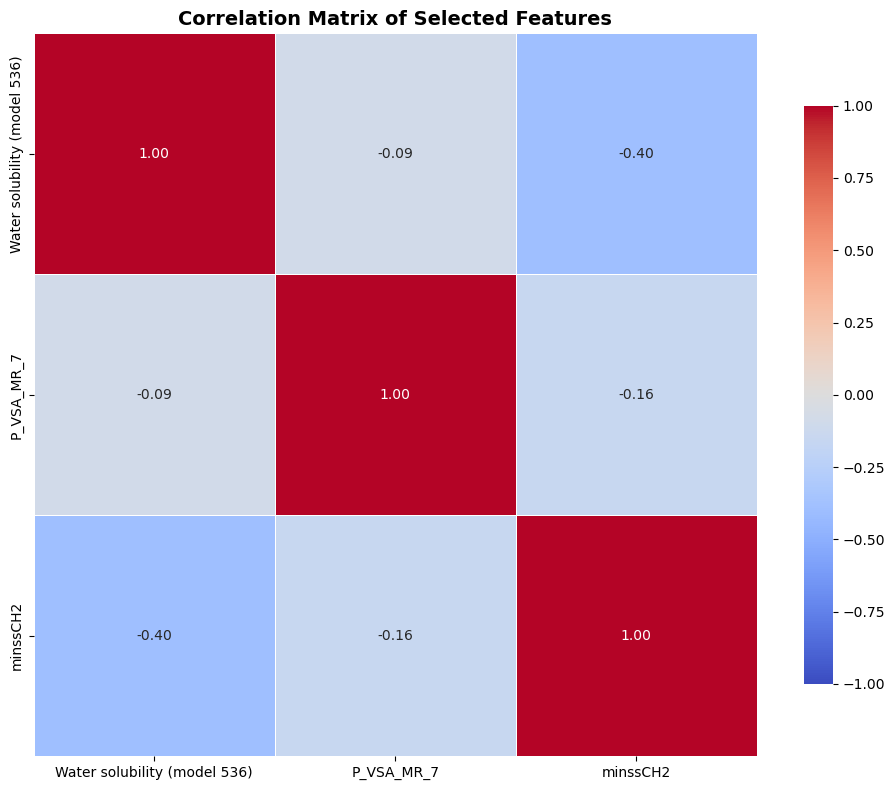


Y-randomization: 500 permutations on features ['Water solubility (model 536)', 'P_VSA_MR_7', 'minssCH2']
Original model (CV): F1 = 0.4000 | BA = 0.7039 | ROC-AUC = 0.8597
Randomized (avg):    F1 = 0.1765 | BA = 0.5044 | ROC-AUC = 0.5024
Randomized (max):    F1 = 0.5714 | BA = 0.8558 | ROC-AUC = 0.9143
Permutations reaching the original ROC-AUC: 0.004

Model  Average F1  Average Balanced Accuracy  Average ROC-AUC
 H400      0.1765                     0.5044           0.5024


In [36]:
#H400
import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.feature_selection import VarianceThreshold
from sklearn.metrics import (
    matthews_corrcoef,
    f1_score,
    balanced_accuracy_score,
    cohen_kappa_score,
    roc_auc_score
)

TEST_SIZE = 0.3
VAR_THRESHOLD = 0.01
CORR_THRESHOLD = 0.85
N_FEATURES = 3
N_OUTER = 3
N_INNER = 3
FINAL_SELECTION = "vote"
AD_K = 3


DATA_FILE = "H400.xlsx"
NEW_SOLVENTS_PATH = "Smiles_desc_distinct_cleaned.xlsx"


def filter_features(X):
    vt = VarianceThreshold(threshold=VAR_THRESHOLD).fit(X)
    cols = X.columns[vt.get_support()]
    corr = X[cols].corr().abs()
    upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
    to_drop = {c for c in upper.columns if any(upper[c] > CORR_THRESHOLD)}
    return [c for c in cols if c not in to_drop]


def fast_mcc(y_true, y_pred):
    tp = np.sum((y_true == 1) & (y_pred == 1))
    tn = np.sum((y_true == 0) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    denom = np.sqrt(float((tp + fp) * (tp + fn) * (tn + fp) * (tn + fn)))
    return 0.0 if denom == 0 else (tp * tn - fp * fn) / denom


def forward_selection(X, y, cv):
    names = list(X.columns)
    Xv, yv = X.to_numpy(dtype=float), y.to_numpy()
    folds = []
    for tr, va in cv.split(Xv, yv):
        sc = StandardScaler().fit(Xv[tr])
        folds.append((sc.transform(Xv[tr]), yv[tr], sc.transform(Xv[va]), yv[va]))

    selected, remaining = [], list(range(len(names)))
    for step in range(N_FEATURES):
        best_score, best_j = -np.inf, None
        for j in remaining:
            cols = selected + [j]
            scores = []
            for X_tr, y_tr, X_va, y_va in folds:
                m = make_model().fit(X_tr[:, cols], y_tr)
                scores.append(fast_mcc(y_va, m.predict(X_va[:, cols])))
            s = np.mean(scores)
            if s > best_score:
                best_score, best_j = s, j
        selected.append(best_j)
        remaining.remove(best_j)
    return [names[j] for j in selected]


def all_metrics(y_true, y_pred, y_score):
    return {
        "Balanced Accuracy": balanced_accuracy_score(y_true, y_pred),
        "F1": f1_score(y_true, y_pred),
        "MCC": matthews_corrcoef(y_true, y_pred),
        "Cohen's Kappa": cohen_kappa_score(y_true, y_pred),
        "ROC-AUC": roc_auc_score(y_true, y_score),
    }


def make_model():
    return SVC(kernel="rbf", C=1.0, class_weight="balanced", random_state=15)



full_df = pd.read_excel(DATA_FILE)
X = full_df.iloc[:, 1:-1]
y = full_df.iloc[:, -1]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=15
)
X_train = X_train.reset_index(drop=True)
X_test = X_test.reset_index(drop=True)
y_train = y_train.reset_index(drop=True)
y_test = y_test.reset_index(drop=True)


outer_cv = StratifiedKFold(n_splits=N_OUTER, shuffle=True, random_state=15)
inner_cv = StratifiedKFold(n_splits=N_INNER, shuffle=True, random_state=15)

fold_results = []
fold_features = []

for fold, (tr_idx, va_idx) in enumerate(outer_cv.split(X_train, y_train), 1):
    X_tr = X_train.iloc[tr_idx].reset_index(drop=True)
    X_va = X_train.iloc[va_idx].reset_index(drop=True)
    y_tr = y_train.iloc[tr_idx].reset_index(drop=True)
    y_va = y_train.iloc[va_idx].reset_index(drop=True)

    kept = filter_features(X_tr)
    feats = forward_selection(X_tr[kept], y_tr, inner_cv)

    fold_scaler = StandardScaler().fit(X_tr[feats])
    model = make_model().fit(fold_scaler.transform(X_tr[feats]), y_tr)

    X_va_s = fold_scaler.transform(X_va[feats])
    m = all_metrics(y_va, model.predict(X_va_s), model.decision_function(X_va_s))
    fold_results.append(m)
    fold_features.append(feats)

nested_df = pd.DataFrame(fold_results)
feature_freq = pd.Series([f for fs in fold_features for f in fs]).value_counts()


if FINAL_SELECTION == "vote":
    final_selected_features = list(feature_freq.index[:N_FEATURES])
else:
    kept = filter_features(X_train)
    final_selected_features = forward_selection(X_train[kept], y_train, inner_cv)

X_train_corr = X_train[final_selected_features]
scaler = StandardScaler().fit(X_train_corr)
X_train_final = pd.DataFrame(scaler.transform(X_train_corr), columns=final_selected_features)
X_test_final = pd.DataFrame(scaler.transform(X_test[final_selected_features]), columns=final_selected_features)

final_model = make_model().fit(X_train_final, y_train)

y_train_pred = final_model.predict(X_train_final)
y_test_pred = final_model.predict(X_test_final)
y_train_scores = final_model.decision_function(X_train_final)
y_test_scores = final_model.decision_function(X_test_final)

train_m = all_metrics(y_train, y_train_pred, y_train_scores)
test_m = all_metrics(y_test, y_test_pred, y_test_scores)
metric_names = list(train_m)

metrics = pd.DataFrame(
    [[len(y_train)] + [round(v, 4) for v in train_m.values()]
     + [len(y_test)] + [round(v, 4) for v in test_m.values()]],
    columns=["N_train"] + metric_names + ["N_test"] + metric_names,
)

print("Final descriptors:", final_selected_features)
print()
print(metrics.to_string(index=False))


feats = list(final_selected_features)
ad_scaler = StandardScaler().fit(X_train[feats])

X_tr_s = X_train_final[feats].to_numpy(dtype=float)
train_centroid = X_tr_s.mean(axis=0)
train_distances = np.linalg.norm(X_tr_s - train_centroid, axis=1)
AD_THRESHOLD = train_distances.mean() + AD_K * train_distances.std()


def ad_distance(X_scaled):
    return np.linalg.norm(np.asarray(X_scaled, dtype=float) - train_centroid, axis=1)


test_distances = ad_distance(X_test_final[feats])

new_solvents_df = pd.read_excel(NEW_SOLVENTS_PATH)
missing = [f for f in feats if f not in new_solvents_df.columns]
if missing:
    raise KeyError(f"New-solvent file is missing required features: {missing}")

new_names = new_solvents_df.iloc[:, 0]
X_new_raw = new_solvents_df[feats].apply(pd.to_numeric, errors="coerce")
valid = X_new_raw.notna().all(axis=1).to_numpy()

new_pred = np.full(len(X_new_raw), np.nan)
new_score = np.full(len(X_new_raw), np.nan)
new_distances = np.full(len(X_new_raw), np.nan)
if valid.any():
    X_new_scaled = pd.DataFrame(ad_scaler.transform(X_new_raw.loc[valid, feats]), columns=feats)
    new_pred[valid] = final_model.predict(X_new_scaled)
    new_score[valid] = final_model.decision_function(X_new_scaled)
    new_distances[valid] = ad_distance(X_new_scaled)

train_in_ad = train_distances <= AD_THRESHOLD
test_in_ad = test_distances <= AD_THRESHOLD
new_in_ad = valid & (np.nan_to_num(new_distances, nan=np.inf) <= AD_THRESHOLD)

ad_summary = pd.DataFrame({
    "Set": ["Train", "Test", "New solvents"],
    "Inside AD": [int(train_in_ad.sum()), int(test_in_ad.sum()), int(new_in_ad.sum())],
    "Total": [len(train_distances), len(test_distances), int(valid.sum())],
})
ad_summary["Inside AD (%)"] = (100 * ad_summary["Inside AD"] / ad_summary["Total"]).round(1)

print(f"\nApplicability domain (distance threshold = {AD_THRESHOLD:.4f}, mean + {AD_K}·SD)")
print(ad_summary.to_string(index=False))
if (~valid).any():
    print(f"{int((~valid).sum())} new solvents skipped (missing descriptor values)")

new_predictions = pd.DataFrame({
    "Solvent_Name": new_names.values,
    "Predicted_Class": pd.array(new_pred, dtype="Int64"),
    "SVM_Decision_Score": new_score,
    "Distance": new_distances,
    "AD_Status": np.where(~valid, "Not predicted",
                          np.where(new_in_ad, "Inside AD", "Outside AD")),
})

print(f"\nNew solvents: predicted class 1 = {int(np.nansum(new_pred == 1))}, "
      f"predicted class 0 = {int(np.nansum(new_pred == 0))}")


selected_corr_matrix = X_train[final_selected_features].corr()
plt.figure(figsize=(10, 8))
sns.heatmap(selected_corr_matrix, annot=True, cmap="coolwarm", fmt=".2f",
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.8},
            vmin=-1, vmax=1)
plt.title("Correlation Matrix of Selected Features", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

ENDPOINT_NAME = "H400"
N_PERMUTATIONS = 500


def cv_metrics(X_mat, y_vec, seed):
    cv = StratifiedKFold(n_splits=N_OUTER, shuffle=True, random_state=seed)
    pred = np.empty(len(y_vec))
    score = np.empty(len(y_vec))
    for tr, va in cv.split(X_mat, y_vec):
        m = make_model().fit(X_mat.iloc[tr], y_vec[tr])
        pred[va] = m.predict(X_mat.iloc[va])
        score[va] = m.decision_function(X_mat.iloc[va])
    return (f1_score(y_vec, pred, zero_division=0),
            balanced_accuracy_score(y_vec, pred),
            roc_auc_score(y_vec, score))


y_tr_np = y_train.to_numpy()
F1_orig, BA_orig, AUC_orig = cv_metrics(X_train_final, y_tr_np, 15)

rng = np.random.default_rng(2024)
rows = [cv_metrics(X_train_final, rng.permutation(y_tr_np), 15) for _ in range(N_PERMUTATIONS)]
yr = pd.DataFrame(rows, columns=["F1", "Balanced Accuracy", "ROC-AUC"])

print(f"\nY-randomization: {N_PERMUTATIONS} permutations on features {final_selected_features}")
print(f"Original model (CV): F1 = {F1_orig:.4f} | BA = {BA_orig:.4f} | ROC-AUC = {AUC_orig:.4f}")
print(f"Randomized (avg):    F1 = {yr['F1'].mean():.4f} | BA = {yr['Balanced Accuracy'].mean():.4f} | ROC-AUC = {yr['ROC-AUC'].mean():.4f}")
print(f"Randomized (max):    F1 = {yr['F1'].max():.4f} | BA = {yr['Balanced Accuracy'].max():.4f} | ROC-AUC = {yr['ROC-AUC'].max():.4f}")
print(f"Permutations reaching the original ROC-AUC: {(yr['ROC-AUC'] >= AUC_orig).mean():.3f}")

summary = pd.DataFrame([{
    "Model": ENDPOINT_NAME,
    "Average F1": round(yr["F1"].mean(), 4),
    "Average Balanced Accuracy": round(yr["Balanced Accuracy"].mean(), 4),
    "Average ROC-AUC": round(yr["ROC-AUC"].mean(), 4),
}])
print("\n" + summary.to_string(index=False))

Final descriptors: ['nAA', 'VE1sign_Dz(p)', 'nO']

 N_train  Balanced Accuracy     F1    MCC  Cohen's Kappa  ROC-AUC  N_test  Balanced Accuracy  F1   MCC  Cohen's Kappa  ROC-AUC
      70             0.8417 0.5625 0.5151         0.4556   0.9017      24             0.8571 0.5 0.488         0.3846   0.8413

Applicability domain (distance threshold = 3.9729, mean + 3·SD)
         Set  Inside AD  Total  Inside AD (%)
       Train         69     70           98.6
        Test         24     24          100.0
New solvents        102    105           97.1


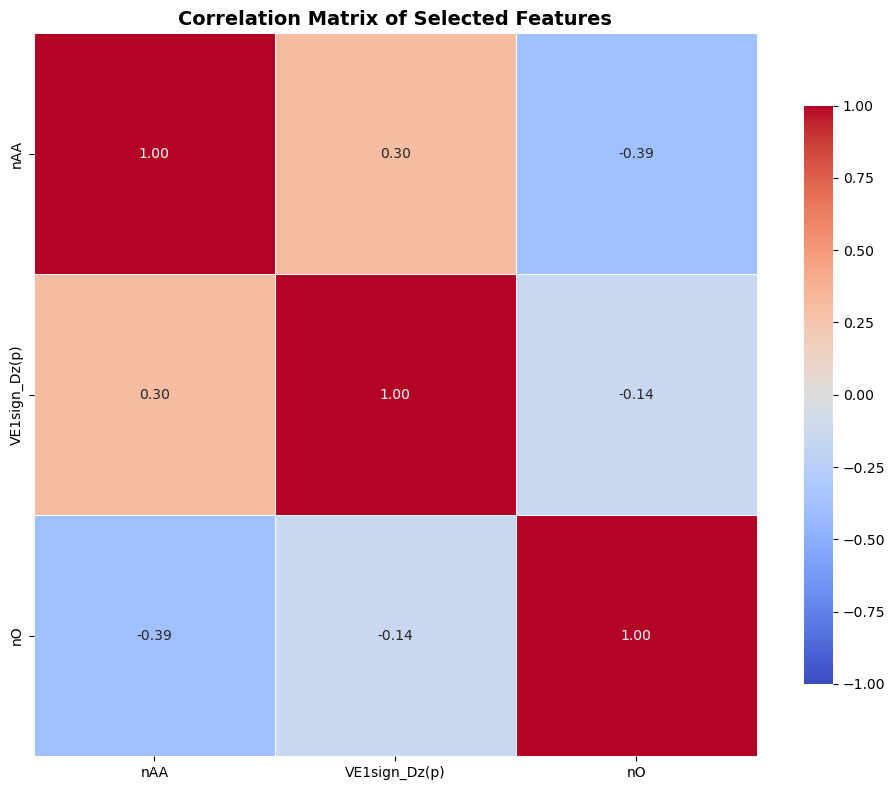


Y-randomization: 500 permutations on features ['nAA', 'VE1sign_Dz(p)', 'nO']
Original model (CV): F1 = 0.3448 | BA = 0.6333 | ROC-AUC = 0.7883
Randomized (avg):    F1 = 0.2080 | BA = 0.5001 | ROC-AUC = 0.4906
Randomized (max):    F1 = 0.5517 | BA = 0.8083 | ROC-AUC = 0.8400
Permutations reaching the original ROC-AUC: 0.016

Model  Average F1  Average Balanced Accuracy  Average ROC-AUC
 H411       0.208                     0.5001           0.4906


In [32]:
#H411

import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.feature_selection import VarianceThreshold
from sklearn.metrics import (
    matthews_corrcoef,
    f1_score,
    balanced_accuracy_score,
    cohen_kappa_score,
    roc_auc_score
)

TEST_SIZE = 0.25
VAR_THRESHOLD = 0.01
CORR_THRESHOLD = 0.85
N_FEATURES = 3
N_OUTER = 3
N_INNER = 3
FINAL_SELECTION = "vote"
AD_K = 3

DATA_FILE = "H411_d.xlsx"
new_solvent_path = "Smiles_desc_distinct_cleaned.xlsx"


def filter_features(X):
    vt = VarianceThreshold(threshold=VAR_THRESHOLD).fit(X)
    cols = X.columns[vt.get_support()]
    corr = X[cols].corr().abs()
    upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
    to_drop = {c for c in upper.columns if any(upper[c] > CORR_THRESHOLD)}
    return [c for c in cols if c not in to_drop]


def fast_mcc(y_true, y_pred):
    tp = np.sum((y_true == 1) & (y_pred == 1))
    tn = np.sum((y_true == 0) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    denom = np.sqrt(float((tp + fp) * (tp + fn) * (tn + fp) * (tn + fn)))
    return 0.0 if denom == 0 else (tp * tn - fp * fn) / denom


def forward_selection(X, y, cv):
    names = list(X.columns)
    Xv, yv = X.to_numpy(dtype=float), y.to_numpy()
    folds = []
    for tr, va in cv.split(Xv, yv):
        sc = StandardScaler().fit(Xv[tr])
        folds.append((sc.transform(Xv[tr]), yv[tr], sc.transform(Xv[va]), yv[va]))

    selected, remaining = [], list(range(len(names)))
    for step in range(N_FEATURES):
        best_score, best_j = -np.inf, None
        for j in remaining:
            cols = selected + [j]
            scores = []
            for X_tr, y_tr, X_va, y_va in folds:
                m = make_model().fit(X_tr[:, cols], y_tr)
                scores.append(fast_mcc(y_va, m.predict(X_va[:, cols])))
            s = np.mean(scores)
            if s > best_score:
                best_score, best_j = s, j
        selected.append(best_j)
        remaining.remove(best_j)
    return [names[j] for j in selected]


def all_metrics(y_true, y_pred, y_score):
    return {
        "Balanced Accuracy": balanced_accuracy_score(y_true, y_pred),
        "F1": f1_score(y_true, y_pred),
        "MCC": matthews_corrcoef(y_true, y_pred),
        "Cohen's Kappa": cohen_kappa_score(y_true, y_pred),
        "ROC-AUC": roc_auc_score(y_true, y_score),
    }

def make_model():
    return SVC(kernel="rbf", C=1.0, class_weight="balanced", random_state=4)



full_df = pd.read_excel(DATA_FILE)
X = full_df.iloc[:, 1:-1]
y = full_df.iloc[:, -1]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=4
)
X_train = X_train.reset_index(drop=True)
X_test = X_test.reset_index(drop=True)
y_train = y_train.reset_index(drop=True)
y_test = y_test.reset_index(drop=True)


outer_cv = StratifiedKFold(n_splits=N_OUTER, shuffle=True, random_state=4)
inner_cv = StratifiedKFold(n_splits=N_INNER, shuffle=True, random_state=4)

fold_results = []
fold_features = []

for fold, (tr_idx, va_idx) in enumerate(outer_cv.split(X_train, y_train), 1):
    X_tr = X_train.iloc[tr_idx].reset_index(drop=True)
    X_va = X_train.iloc[va_idx].reset_index(drop=True)
    y_tr = y_train.iloc[tr_idx].reset_index(drop=True)
    y_va = y_train.iloc[va_idx].reset_index(drop=True)

    kept = filter_features(X_tr)
    feats = forward_selection(X_tr[kept], y_tr, inner_cv)

    fold_scaler = StandardScaler().fit(X_tr[feats])
    model = make_model().fit(fold_scaler.transform(X_tr[feats]), y_tr)

    X_va_s = fold_scaler.transform(X_va[feats])
    m = all_metrics(y_va, model.predict(X_va_s), model.decision_function(X_va_s))
    fold_results.append(m)
    fold_features.append(feats)

nested_df = pd.DataFrame(fold_results)
feature_freq = pd.Series([f for fs in fold_features for f in fs]).value_counts()


if FINAL_SELECTION == "vote":
    final_selected_features = list(feature_freq.index[:N_FEATURES])
else:
    kept = filter_features(X_train)
    final_selected_features = forward_selection(X_train[kept], y_train, inner_cv)

X_train_corr = X_train[final_selected_features]
scaler = StandardScaler().fit(X_train_corr)
X_train_final = pd.DataFrame(scaler.transform(X_train_corr), columns=final_selected_features)
X_test_final = pd.DataFrame(scaler.transform(X_test[final_selected_features]), columns=final_selected_features)

final_model = make_model().fit(X_train_final, y_train)

y_train_pred = final_model.predict(X_train_final)
y_test_pred = final_model.predict(X_test_final)
y_train_scores = final_model.decision_function(X_train_final)
y_test_scores = final_model.decision_function(X_test_final)

train_m = all_metrics(y_train, y_train_pred, y_train_scores)
test_m = all_metrics(y_test, y_test_pred, y_test_scores)
metric_names = list(train_m)

metrics = pd.DataFrame(
    [[len(y_train)] + [round(v, 4) for v in train_m.values()]
     + [len(y_test)] + [round(v, 4) for v in test_m.values()]],
    columns=["N_train"] + metric_names + ["N_test"] + metric_names,
)

print("Final descriptors:", final_selected_features)
print()
print(metrics.to_string(index=False))


feats = list(final_selected_features)
ad_scaler = StandardScaler().fit(X_train[feats])

X_tr_s = X_train_final[feats].to_numpy(dtype=float)
train_centroid = X_tr_s.mean(axis=0)
train_distances = np.linalg.norm(X_tr_s - train_centroid, axis=1)
AD_THRESHOLD = train_distances.mean() + AD_K * train_distances.std()


def ad_distance(X_scaled):
    return np.linalg.norm(np.asarray(X_scaled, dtype=float) - train_centroid, axis=1)


test_distances = ad_distance(X_test_final[feats])

new_solvents_df = pd.read_excel(NEW_SOLVENTS_PATH)
missing = [f for f in feats if f not in new_solvents_df.columns]
if missing:
    raise KeyError(f"New-solvent file is missing required features: {missing}")

new_names = new_solvents_df.iloc[:, 0]
X_new_raw = new_solvents_df[feats].apply(pd.to_numeric, errors="coerce")
valid = X_new_raw.notna().all(axis=1).to_numpy()

new_pred = np.full(len(X_new_raw), np.nan)
new_score = np.full(len(X_new_raw), np.nan)
new_distances = np.full(len(X_new_raw), np.nan)
if valid.any():
    X_new_scaled = pd.DataFrame(ad_scaler.transform(X_new_raw.loc[valid, feats]), columns=feats)
    new_pred[valid] = final_model.predict(X_new_scaled)
    new_score[valid] = final_model.decision_function(X_new_scaled)
    new_distances[valid] = ad_distance(X_new_scaled)

train_in_ad = train_distances <= AD_THRESHOLD
test_in_ad = test_distances <= AD_THRESHOLD
new_in_ad = valid & (np.nan_to_num(new_distances, nan=np.inf) <= AD_THRESHOLD)

ad_summary = pd.DataFrame({
    "Set": ["Train", "Test", "New solvents"],
    "Inside AD": [int(train_in_ad.sum()), int(test_in_ad.sum()), int(new_in_ad.sum())],
    "Total": [len(train_distances), len(test_distances), int(valid.sum())],
})
ad_summary["Inside AD (%)"] = (100 * ad_summary["Inside AD"] / ad_summary["Total"]).round(1)

print(f"\nApplicability domain (distance threshold = {AD_THRESHOLD:.4f}, mean + {AD_K}·SD)")
print(ad_summary.to_string(index=False))
if (~valid).any():
    print(f"{int((~valid).sum())} new solvents skipped (missing descriptor values)")

new_predictions = pd.DataFrame({
    "Solvent_Name": new_names.values,
    "Predicted_Class": pd.array(new_pred, dtype="Int64"),
    "SVM_Decision_Score": new_score,
    "Distance": new_distances,
    "AD_Status": np.where(~valid, "Not predicted",
                          np.where(new_in_ad, "Inside AD", "Outside AD")),
})


selected_corr_matrix = X_train[final_selected_features].corr()
plt.figure(figsize=(10, 8))
sns.heatmap(selected_corr_matrix, annot=True, cmap="coolwarm", fmt=".2f",
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.8},
            vmin=-1, vmax=1)
plt.title("Correlation Matrix of Selected Features", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

ENDPOINT_NAME = "H411"
N_PERMUTATIONS = 500


def cv_metrics(X_mat, y_vec, seed):
    cv = StratifiedKFold(n_splits=N_OUTER, shuffle=True, random_state=seed)
    pred = np.empty(len(y_vec))
    score = np.empty(len(y_vec))
    for tr, va in cv.split(X_mat, y_vec):
        m = make_model().fit(X_mat.iloc[tr], y_vec[tr])
        pred[va] = m.predict(X_mat.iloc[va])
        score[va] = m.decision_function(X_mat.iloc[va])
    return (f1_score(y_vec, pred, zero_division=0),
            balanced_accuracy_score(y_vec, pred),
            roc_auc_score(y_vec, score))


y_tr_np = y_train.to_numpy()
F1_orig, BA_orig, AUC_orig = cv_metrics(X_train_final, y_tr_np, 4)

rng = np.random.default_rng(2024)
rows = [cv_metrics(X_train_final, rng.permutation(y_tr_np), 4) for _ in range(N_PERMUTATIONS)]
yr = pd.DataFrame(rows, columns=["F1", "Balanced Accuracy", "ROC-AUC"])

print(f"\nY-randomization: {N_PERMUTATIONS} permutations on features {final_selected_features}")
print(f"Original model (CV): F1 = {F1_orig:.4f} | BA = {BA_orig:.4f} | ROC-AUC = {AUC_orig:.4f}")
print(f"Randomized (avg):    F1 = {yr['F1'].mean():.4f} | BA = {yr['Balanced Accuracy'].mean():.4f} | ROC-AUC = {yr['ROC-AUC'].mean():.4f}")
print(f"Randomized (max):    F1 = {yr['F1'].max():.4f} | BA = {yr['Balanced Accuracy'].max():.4f} | ROC-AUC = {yr['ROC-AUC'].max():.4f}")
print(f"Permutations reaching the original ROC-AUC: {(yr['ROC-AUC'] >= AUC_orig).mean():.3f}")

summary = pd.DataFrame([{
    "Model": ENDPOINT_NAME,
    "Average F1": round(yr["F1"].mean(), 4),
    "Average Balanced Accuracy": round(yr["Balanced Accuracy"].mean(), 4),
    "Average ROC-AUC": round(yr["ROC-AUC"].mean(), 4),
}])
print("\n" + summary.to_string(index=False))

Final descriptors: ['nAA', 'P_VSA_MR_8', 'nTB']

 N_train  Balanced Accuracy     F1    MCC  Cohen's Kappa  ROC-AUC  N_test  Balanced Accuracy   F1    MCC  Cohen's Kappa  ROC-AUC
      66             0.9741 0.8421 0.8305         0.8163   0.9871      22             0.9474 0.75 0.7327         0.6986   0.9474

Applicability domain (distance threshold = 5.1603, mean + 3·SD)
         Set  Inside AD  Total  Inside AD (%)
       Train         64     66           97.0
        Test         22     22          100.0
New solvents        105    105          100.0


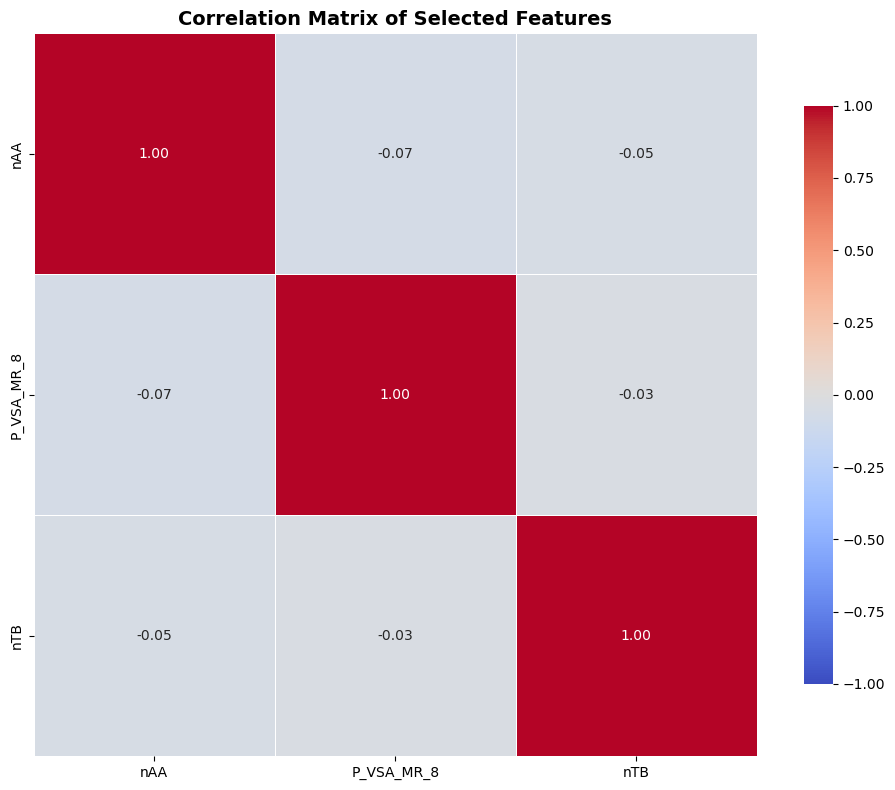


Y-randomization: 500 permutations on features ['nAA', 'P_VSA_MR_8', 'nTB']
Original model (CV): F1 = 0.8000 | BA = 0.9655 | ROC-AUC = 0.9558
Randomized (avg):    F1 = 0.1693 | BA = 0.4900 | ROC-AUC = 0.4869
Randomized (max):    F1 = 0.5000 | BA = 0.7155 | ROC-AUC = 0.7381
Permutations reaching the original ROC-AUC: 0.000

Model  Average F1  Average Balanced Accuracy  Average ROC-AUC
 H412      0.1693                       0.49           0.4869


In [33]:
#H412

import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.feature_selection import VarianceThreshold
from sklearn.metrics import (
    matthews_corrcoef,
    f1_score,
    balanced_accuracy_score,
    cohen_kappa_score,
    roc_auc_score
)


TEST_SIZE = 0.25
VAR_THRESHOLD = 0.01
CORR_THRESHOLD = 0.85
N_FEATURES = 3
N_OUTER = 3
N_INNER = 3
FINAL_SELECTION = "vote"
AD_K = 3


DATA_FILE = "H412.xlsx"
new_solvent_path = "Smiles_desc_distinct_cleaned.xlsx"



def filter_features(X):
    vt = VarianceThreshold(threshold=VAR_THRESHOLD).fit(X)
    cols = X.columns[vt.get_support()]
    corr = X[cols].corr().abs()
    upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
    to_drop = {c for c in upper.columns if any(upper[c] > CORR_THRESHOLD)}
    return [c for c in cols if c not in to_drop]


def fast_mcc(y_true, y_pred):
    tp = np.sum((y_true == 1) & (y_pred == 1))
    tn = np.sum((y_true == 0) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    denom = np.sqrt(float((tp + fp) * (tp + fn) * (tn + fp) * (tn + fn)))
    return 0.0 if denom == 0 else (tp * tn - fp * fn) / denom


def forward_selection(X, y, cv):
    names = list(X.columns)
    Xv, yv = X.to_numpy(dtype=float), y.to_numpy()
    folds = []
    for tr, va in cv.split(Xv, yv):
        sc = StandardScaler().fit(Xv[tr])
        folds.append((sc.transform(Xv[tr]), yv[tr], sc.transform(Xv[va]), yv[va]))

    selected, remaining = [], list(range(len(names)))
    for step in range(N_FEATURES):
        best_score, best_j = -np.inf, None
        for j in remaining:
            cols = selected + [j]
            scores = []
            for X_tr, y_tr, X_va, y_va in folds:
                m = make_model().fit(X_tr[:, cols], y_tr)
                scores.append(fast_mcc(y_va, m.predict(X_va[:, cols])))
            s = np.mean(scores)
            if s > best_score:
                best_score, best_j = s, j
        selected.append(best_j)
        remaining.remove(best_j)
    return [names[j] for j in selected]


def all_metrics(y_true, y_pred, y_score):
    return {
        "Balanced Accuracy": balanced_accuracy_score(y_true, y_pred),
        "F1": f1_score(y_true, y_pred),
        "MCC": matthews_corrcoef(y_true, y_pred),
        "Cohen's Kappa": cohen_kappa_score(y_true, y_pred),
        "ROC-AUC": roc_auc_score(y_true, y_score),
    }

def make_model():
    return SVC(kernel="rbf", C=1.0, class_weight="balanced", random_state=3)



full_df = pd.read_excel(DATA_FILE)
X = full_df.iloc[:, 1:-1]
y = full_df.iloc[:, -1]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=3
)
X_train = X_train.reset_index(drop=True)
X_test = X_test.reset_index(drop=True)
y_train = y_train.reset_index(drop=True)
y_test = y_test.reset_index(drop=True)


outer_cv = StratifiedKFold(n_splits=N_OUTER, shuffle=True, random_state=3)
inner_cv = StratifiedKFold(n_splits=N_INNER, shuffle=True, random_state=3)

fold_results = []
fold_features = []

for fold, (tr_idx, va_idx) in enumerate(outer_cv.split(X_train, y_train), 1):
    X_tr = X_train.iloc[tr_idx].reset_index(drop=True)
    X_va = X_train.iloc[va_idx].reset_index(drop=True)
    y_tr = y_train.iloc[tr_idx].reset_index(drop=True)
    y_va = y_train.iloc[va_idx].reset_index(drop=True)

    kept = filter_features(X_tr)
    feats = forward_selection(X_tr[kept], y_tr, inner_cv)

    fold_scaler = StandardScaler().fit(X_tr[feats])
    model = make_model().fit(fold_scaler.transform(X_tr[feats]), y_tr)

    X_va_s = fold_scaler.transform(X_va[feats])
    m = all_metrics(y_va, model.predict(X_va_s), model.decision_function(X_va_s))
    fold_results.append(m)
    fold_features.append(feats)

nested_df = pd.DataFrame(fold_results)
feature_freq = pd.Series([f for fs in fold_features for f in fs]).value_counts()


if FINAL_SELECTION == "vote":
    final_selected_features = list(feature_freq.index[:N_FEATURES])
else:
    kept = filter_features(X_train)
    final_selected_features = forward_selection(X_train[kept], y_train, inner_cv)

X_train_corr = X_train[final_selected_features]
scaler = StandardScaler().fit(X_train_corr)
X_train_final = pd.DataFrame(scaler.transform(X_train_corr), columns=final_selected_features)
X_test_final = pd.DataFrame(scaler.transform(X_test[final_selected_features]), columns=final_selected_features)

final_model = make_model().fit(X_train_final, y_train)

y_train_pred = final_model.predict(X_train_final)
y_test_pred = final_model.predict(X_test_final)
y_train_scores = final_model.decision_function(X_train_final)
y_test_scores = final_model.decision_function(X_test_final)

train_m = all_metrics(y_train, y_train_pred, y_train_scores)
test_m = all_metrics(y_test, y_test_pred, y_test_scores)
metric_names = list(train_m)

metrics = pd.DataFrame(
    [[len(y_train)] + [round(v, 4) for v in train_m.values()]
     + [len(y_test)] + [round(v, 4) for v in test_m.values()]],
    columns=["N_train"] + metric_names + ["N_test"] + metric_names,
)

print("Final descriptors:", final_selected_features)
print()
print(metrics.to_string(index=False))


feats = list(final_selected_features)
ad_scaler = StandardScaler().fit(X_train[feats])

X_tr_s = X_train_final[feats].to_numpy(dtype=float)
train_centroid = X_tr_s.mean(axis=0)
train_distances = np.linalg.norm(X_tr_s - train_centroid, axis=1)
AD_THRESHOLD = train_distances.mean() + AD_K * train_distances.std()


def ad_distance(X_scaled):
    return np.linalg.norm(np.asarray(X_scaled, dtype=float) - train_centroid, axis=1)


test_distances = ad_distance(X_test_final[feats])

new_solvents_df = pd.read_excel(NEW_SOLVENTS_PATH)
missing = [f for f in feats if f not in new_solvents_df.columns]
if missing:
    raise KeyError(f"New-solvent file is missing required features: {missing}")

new_names = new_solvents_df.iloc[:, 0]
X_new_raw = new_solvents_df[feats].apply(pd.to_numeric, errors="coerce")
valid = X_new_raw.notna().all(axis=1).to_numpy()

new_pred = np.full(len(X_new_raw), np.nan)
new_score = np.full(len(X_new_raw), np.nan)
new_distances = np.full(len(X_new_raw), np.nan)
if valid.any():
    X_new_scaled = pd.DataFrame(ad_scaler.transform(X_new_raw.loc[valid, feats]), columns=feats)
    new_pred[valid] = final_model.predict(X_new_scaled)
    new_score[valid] = final_model.decision_function(X_new_scaled)
    new_distances[valid] = ad_distance(X_new_scaled)

train_in_ad = train_distances <= AD_THRESHOLD
test_in_ad = test_distances <= AD_THRESHOLD
new_in_ad = valid & (np.nan_to_num(new_distances, nan=np.inf) <= AD_THRESHOLD)

ad_summary = pd.DataFrame({
    "Set": ["Train", "Test", "New solvents"],
    "Inside AD": [int(train_in_ad.sum()), int(test_in_ad.sum()), int(new_in_ad.sum())],
    "Total": [len(train_distances), len(test_distances), int(valid.sum())],
})
ad_summary["Inside AD (%)"] = (100 * ad_summary["Inside AD"] / ad_summary["Total"]).round(1)

print(f"\nApplicability domain (distance threshold = {AD_THRESHOLD:.4f}, mean + {AD_K}·SD)")
print(ad_summary.to_string(index=False))
if (~valid).any():
    print(f"{int((~valid).sum())} new solvents skipped (missing descriptor values)")

new_predictions = pd.DataFrame({
    "Solvent_Name": new_names.values,
    "Predicted_Class": pd.array(new_pred, dtype="Int64"),
    "SVM_Decision_Score": new_score,
    "Distance": new_distances,
    "AD_Status": np.where(~valid, "Not predicted",
                          np.where(new_in_ad, "Inside AD", "Outside AD")),
})


selected_corr_matrix = X_train[final_selected_features].corr()
plt.figure(figsize=(10, 8))
sns.heatmap(selected_corr_matrix, annot=True, cmap="coolwarm", fmt=".2f",
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.8},
            vmin=-1, vmax=1)
plt.title("Correlation Matrix of Selected Features", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

ENDPOINT_NAME = "H412"
N_PERMUTATIONS = 500


def cv_metrics(X_mat, y_vec, seed):
    cv = StratifiedKFold(n_splits=N_OUTER, shuffle=True, random_state=seed)
    pred = np.empty(len(y_vec))
    score = np.empty(len(y_vec))
    for tr, va in cv.split(X_mat, y_vec):
        m = make_model().fit(X_mat.iloc[tr], y_vec[tr])
        pred[va] = m.predict(X_mat.iloc[va])
        score[va] = m.decision_function(X_mat.iloc[va])
    return (f1_score(y_vec, pred, zero_division=0),
            balanced_accuracy_score(y_vec, pred),
            roc_auc_score(y_vec, score))


y_tr_np = y_train.to_numpy()
F1_orig, BA_orig, AUC_orig = cv_metrics(X_train_final, y_tr_np, 3)

rng = np.random.default_rng(2024)
rows = [cv_metrics(X_train_final, rng.permutation(y_tr_np), 3) for _ in range(N_PERMUTATIONS)]
yr = pd.DataFrame(rows, columns=["F1", "Balanced Accuracy", "ROC-AUC"])

print(f"\nY-randomization: {N_PERMUTATIONS} permutations on features {final_selected_features}")
print(f"Original model (CV): F1 = {F1_orig:.4f} | BA = {BA_orig:.4f} | ROC-AUC = {AUC_orig:.4f}")
print(f"Randomized (avg):    F1 = {yr['F1'].mean():.4f} | BA = {yr['Balanced Accuracy'].mean():.4f} | ROC-AUC = {yr['ROC-AUC'].mean():.4f}")
print(f"Randomized (max):    F1 = {yr['F1'].max():.4f} | BA = {yr['Balanced Accuracy'].max():.4f} | ROC-AUC = {yr['ROC-AUC'].max():.4f}")
print(f"Permutations reaching the original ROC-AUC: {(yr['ROC-AUC'] >= AUC_orig).mean():.3f}")

summary = pd.DataFrame([{
    "Model": ENDPOINT_NAME,
    "Average F1": round(yr["F1"].mean(), 4),
    "Average Balanced Accuracy": round(yr["Balanced Accuracy"].mean(), 4),
    "Average ROC-AUC": round(yr["ROC-AUC"].mean(), 4),
}])
print("\n" + summary.to_string(index=False))